In [1]:
# ============================================================
# CELL 1 — BERT + SELECTIVE
# ============================================================

import os
import re
import gc
import json
import html
import random
import warnings

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_NAME = "bert-base-uncased"
EXPERIMENT_NAME = "BERT + Selective"
CLEANING_METHOD = "Selective"

MAX_LENGTH = 512
METADATA_DIM = 53
FREEZE_TRANSFORMER = True

BASE_RESULT_DIR = "/kaggle/working/bert_selective"

RESULT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "results"
)

CHECKPOINT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "checkpoints"
)

BACKUP_DIR = os.path.join(
    BASE_RESULT_DIR,
    "backup"
)

for directory in [
    RESULT_DIR,
    CHECKPOINT_DIR,
    BACKUP_DIR
]:
    os.makedirs(
        directory,
        exist_ok=True
    )

FIXED_CONTROLS = {
    "user_level_split": True,
    "train_users": 6135,
    "validation_users": 767,
    "test_users": 767,
    "diagnostic_anchor_removal": True,
    "metadata_features": 53,
    "metadata_scaling": "TRAIN ONLY",
    "training_balance": "2013 negative + 2013 positive",
    "batch_size": 16,
    "context_length": 512,
    "random_seed": 42,
    "checkpoint_metric": "Validation F1",
    "early_stopping_patience": 2,
    "maximum_epochs": 10,
    "transformer_frozen": True
}

print("=" * 60)
print("BERT + SELECTIVE")
print("=" * 60)

print()
print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )
    print(
        "CUDA:",
        torch.version.cuda
    )

print()
print("Model:", MODEL_NAME)
print("Cleaning:", CLEANING_METHOD)
print("Context length:", MAX_LENGTH)
print("Metadata features:", METADATA_DIM)
print("Transformer frozen:", FREEZE_TRANSFORMER)
print("Seed:", SEED)

print()
print("=" * 60)
print("SELECTIVE CLEANING POLICY")
print("=" * 60)

print("01. Remove URLs")
print("02. Remove malformed URL variants")
print("03. Remove user mentions")
print("04. Remove hashtag symbols")
print("05. Remove HTML / markup")
print("06. Preserve normal punctuation")
print("07. Preserve emojis")
print("08. Preserve emoticons")
print("09. Preserve expressive symbols where applicable")
print("10. Normalize unnecessary whitespace")
print("11. Lowercase text")

print()
print("=" * 60)
print("BERT CONFIGURATION")
print("=" * 60)

print("Base encoder: BERT-base-uncased")
print("Pretrained model:", MODEL_NAME)
print("Backbone training: FROZEN")
print("Downstream classifier: TRAINABLE")
print("Metadata branch: TRAINABLE")

experiment_config = {
    "experiment_name": EXPERIMENT_NAME,
    "model_name": MODEL_NAME,
    "cleaning_method": CLEANING_METHOD,
    "context_length": MAX_LENGTH,
    "metadata_dimension": METADATA_DIM,
    "transformer_frozen": FREEZE_TRANSFORMER,
    "seed": SEED,
    "fixed_controls": FIXED_CONTROLS
}

with open(
    os.path.join(
        RESULT_DIR,
        "experiment_config.json"
    ),
    "w"
) as f:
    json.dump(
        experiment_config,
        f,
        indent=2
    )

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print("✓ BERT-base-uncased selected")
print("✓ Selective cleaning selected")
print("✓ Context length = 512")
print("✓ Metadata dimension = 53")
print("✓ Transformer backbone = FROZEN")
print("✓ Downstream layers = TRAINABLE")
print("✓ Random seed = 42")
print("✓ Result directory created")
print("✓ Checkpoint directory created")
print("✓ Backup directory created")
print("✓ Experiment configuration saved")
print("✓ Previous experiment outputs untouched")
print("✓ Fixed experimental controls recorded")

BERT + SELECTIVE

Device: cuda
GPU: Tesla T4
CUDA: 12.8

Model: bert-base-uncased
Cleaning: Selective
Context length: 512
Metadata features: 53
Transformer frozen: True
Seed: 42

SELECTIVE CLEANING POLICY
01. Remove URLs
02. Remove malformed URL variants
03. Remove user mentions
04. Remove hashtag symbols
05. Remove HTML / markup
06. Preserve normal punctuation
07. Preserve emojis
08. Preserve emoticons
09. Preserve expressive symbols where applicable
10. Normalize unnecessary whitespace
11. Lowercase text

BERT CONFIGURATION
Base encoder: BERT-base-uncased
Pretrained model: bert-base-uncased
Backbone training: FROZEN
Downstream classifier: TRAINABLE
Metadata branch: TRAINABLE

CELL 1 COMPLETE
✓ BERT-base-uncased selected
✓ Selective cleaning selected
✓ Context length = 512
✓ Metadata dimension = 53
✓ Transformer backbone = FROZEN
✓ Downstream layers = TRAINABLE
✓ Random seed = 42
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory created
✓ Experiment configur

In [2]:
# ============================================================
# CELL 2 — BERT + SELECTIVE
# ============================================================

print("=" * 60)
print("BERT + SELECTIVE — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)

print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)

assert os.path.exists(TRAIN_PATH)
assert os.path.exists(VAL_PATH)
assert os.path.exists(TEST_PATH)

print()
print("✓ All split files found")

train_df = pd.read_pickle(TRAIN_PATH)
val_df = pd.read_pickle(VAL_PATH)
test_df = pd.read_pickle(TEST_PATH)

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

assert train_df.shape == (6135, 82)
assert val_df.shape == (767, 82)
assert test_df.shape == (767, 82)

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:
    assert column in train_df.columns
    assert column in val_df.columns
    assert column in test_df.columns
    print("✓", column)

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(train_df["user_id"])
val_users = set(val_df["user_id"])
test_users = set(test_df["user_id"])

print("Train unique users:", train_df["user_id"].nunique())
print("Validation unique users:", val_df["user_id"].nunique())
print("Test unique users:", test_df["user_id"].nunique())

assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique

print("TRAIN ↔ VAL:", len(train_users & val_users))
print("TRAIN ↔ TEST:", len(train_users & test_users))
print("VAL ↔ TEST:", len(val_users & test_users))

assert len(train_users & val_users) == 0
assert len(train_users & test_users) == 0
assert len(val_users & test_users) == 0

print()
print("✓ No duplicate users")
print("✓ No cross-split overlap")

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(train_df["label"].value_counts().sort_index())

print()
print("VALIDATION:")
print(val_df["label"].value_counts().sort_index())

print()
print("TEST:")
print(test_df["label"].value_counts().sort_index())

assert (
    train_df["label"].value_counts().sort_index().to_dict()
    == {0: 4122, 1: 2013}
)

assert (
    val_df["label"].value_counts().sort_index().to_dict()
    == {0: 515, 1: 252}
)

assert (
    test_df["label"].value_counts().sort_index().to_dict()
    == {0: 516, 1: 251}
)

print()
print("=" * 60)
print("TIMELINE TEXT CHECK")
print("=" * 60)

train_null = int(train_df["timeline_text"].isna().sum())
val_null = int(val_df["timeline_text"].isna().sum())
test_null = int(test_df["timeline_text"].isna().sum())

print("TRAIN null timeline texts:", train_null)
print("VALIDATION null timeline texts:", val_null)
print("TEST null timeline texts:", test_null)

assert train_null == 0
assert val_null == 0
assert test_null == 0

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print("✓ Exact user-level split restored")
print("✓ TRAIN = 6135")
print("✓ VALIDATION = 767")
print("✓ TEST = 767")
print("✓ Same labels as previous experiments")
print("✓ No duplicate users")
print("✓ No cross-split user overlap")
print("✓ Timeline text available")

BERT + SELECTIVE — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TIMELINE TEXT CHECK
TRAIN null timeline texts: 0
VALIDATION null timeline texts: 0
TEST null timeline texts: 0

CELL 2 COMPL

In [3]:
# ============================================================
# CELL 3 — BERT + SELECTIVE
# ============================================================

print("=" * 60)
print("BERT + SELECTIVE — EXACT D1 ANCHOR DETECTION")
print("=" * 60)

import os
import re
import json
import glob
from collections import defaultdict

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

D1_TIMELINE_DIR = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(D1_TIMELINE_DIR)

d1_timeline_files = glob.glob(
    os.path.join(D1_TIMELINE_DIR, "*.json")
)

print()
print("D1 timeline files found:", len(d1_timeline_files))

assert len(d1_timeline_files) == 2626

REFINED_ANCHOR_PATTERNS = [
    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",
    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",
    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",
    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",
    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",
    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",
    r"\bi\s+have\s+(?:major\s+)?depression\b",
    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",
    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",
    r"\b(?:my|a)\s+(?:doctor|psychiatrist)\s+(?:has\s+)?diagnosed\s+me\b.{0,80}\bdepress"
]

EXCLUSION_PATTERNS = [
    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",
    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",
    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",
    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",
    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",
    r"\bmy\s+answer\s+to\s*:",
    r"\banswer\s+to\s*:",
    r"\bquestion\s*:",
    r"\bq\s*:"
]

compiled_anchor_patterns = [
    re.compile(p, re.IGNORECASE | re.DOTALL)
    for p in REFINED_ANCHOR_PATTERNS
]

compiled_exclusion_patterns = [
    re.compile(p, re.IGNORECASE | re.DOTALL)
    for p in EXCLUSION_PATTERNS
]


def is_refined_anchor_tweet(text):
    if text is None:
        return False

    text = str(text).strip()

    if not text:
        return False

    for pattern in compiled_exclusion_patterns:
        if pattern.search(text):
            return False

    for pattern in compiled_anchor_patterns:
        if pattern.search(text):
            return True

    return False


train_positive_users = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ].astype(str)
)

val_positive_users = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ].astype(str)
)

test_positive_users = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ].astype(str)
)

all_positive_users = (
    train_positive_users
    | val_positive_users
    | test_positive_users
)

print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print("TRAIN:", len(train_positive_users))
print("VALIDATION:", len(val_positive_users))
print("TEST:", len(test_positive_users))

assert len(train_positive_users) == 2013
assert len(val_positive_users) == 252
assert len(test_positive_users) == 251
assert len(all_positive_users) == 2516


timeline_files_by_user = defaultdict(list)

for timeline_file in d1_timeline_files:
    filename = os.path.basename(timeline_file)
    username = filename.split("created_at")[0]

    timeline_files_by_user[
        username
    ].append(timeline_file)

assert len(timeline_files_by_user) == 2516


anchor_records = []
users_processed = set()
tweets_scanned = 0

for username in sorted(all_positive_users):

    if username not in timeline_files_by_user:
        raise KeyError(
            f"Missing D1 timeline for user: {username}"
        )

    users_processed.add(username)

    for timeline_file in timeline_files_by_user[username]:

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:
                line = line.strip()

                if not line:
                    continue

                record = json.loads(line)
                tweets_scanned += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get("id", "")
                    )
                )

                tweet_text = str(
                    record.get("text", "")
                )

                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):
                    anchor_records.append({
                        "username": username,
                        "tweet_id": tweet_id,
                        "created_at":
                            record.get("created_at"),
                        "text": tweet_text
                    })


anchor_pairs = {
    (
        record["username"],
        record["tweet_id"]
    )
    for record in anchor_records
}

train_anchor_pairs = {
    pair for pair in anchor_pairs
    if pair[0] in train_positive_users
}

val_anchor_pairs = {
    pair for pair in anchor_pairs
    if pair[0] in val_positive_users
}

test_anchor_pairs = {
    pair for pair in anchor_pairs
    if pair[0] in test_positive_users
}


print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print("Positive users processed:", len(users_processed))
print("Tweets scanned:", tweets_scanned)
print("Raw anchor records:", len(anchor_records))
print("Unique anchor pairs:", len(anchor_pairs))

print()
print("TRAIN unique anchors:", len(train_anchor_pairs))
print("VAL unique anchors:", len(val_anchor_pairs))
print("TEST unique anchors:", len(test_anchor_pairs))

assert len(users_processed) == 2516
assert tweets_scanned == 508806
assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847

assert len(train_anchor_pairs) == 1476
assert len(val_anchor_pairs) == 190
assert len(test_anchor_pairs) == 181


bert_selective_anchor_df = pd.DataFrame(
    anchor_records
)

bert_selective_anchor_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "exact_anchor_records.csv"
    ),
    index=False
)

pd.DataFrame(
    list(anchor_pairs),
    columns=["username", "tweet_id"]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "unique_anchor_pairs.csv"
    ),
    index=False
)

print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print("✓ Exact anchor detector reproduced")
print("✓ 1,847 unique anchors confirmed")
print("✓ 1,920 anchor records confirmed")
print("✓ TRAIN = 1,476 unique anchors")
print("✓ VAL = 190 unique anchors")
print("✓ TEST = 181 unique anchors")
print("✓ No D2 users included")
print("✓ Anchor records saved")
print("✓ No timelines modified yet")

BERT + SELECTIVE — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ 1,920 anchor records confirmed
✓ TRAIN = 1,476 unique anchors
✓ VAL = 190 unique anchors
✓ TEST = 181 unique anchors
✓ No D2 users included
✓ Anchor records saved
✓ No timelines modified yet


In [4]:
# ============================================================
# CELL 4 — BERT + SELECTIVE
# EXACT D1 ANCHOR REMOVAL
# ============================================================

print("=" * 60)
print("BERT + SELECTIVE — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)

EXACT_ANCHOR_SET = set(anchor_pairs)

train_anchor_records = [
    r for r in anchor_records
    if r["username"] in train_positive_users
]

val_anchor_records = [
    r for r in anchor_records
    if r["username"] in val_positive_users
]

test_anchor_records = [
    r for r in anchor_records
    if r["username"] in test_positive_users
]

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_anchor_occurrences = (
    len(anchor_records) - len(anchor_pairs)
)

print("Raw anchor records:", len(anchor_records))
print("Unique anchor pairs:", len(anchor_pairs))
print("Duplicate anchor occurrences:", duplicate_anchor_occurrences)

assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847
assert duplicate_anchor_occurrences == 73

print("✓ 1,847 unique anchors verified")
print("✓ 73 duplicate occurrences verified")
print("✓ 1,920 total anchor records verified")

print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print("TRAIN:", len(train_anchor_records), "| expected: 1535")
print("VAL:", len(val_anchor_records), "| expected: 199")
print("TEST:", len(test_anchor_records), "| expected: 186")

assert len(train_anchor_records) == 1535
assert len(val_anchor_records) == 199
assert len(test_anchor_records) == 186

# Build timeline index
timeline_files_by_user = defaultdict(list)

for timeline_file in d1_timeline_files:
    filename = os.path.basename(timeline_file)
    username = filename.split("created_at")[0]
    timeline_files_by_user[username].append(timeline_file)

assert len(timeline_files_by_user) == 2516


def build_anchor_removed_text(username):
    kept_texts = []
    removed_count = 0

    for timeline_file in timeline_files_by_user[username]:
        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:
                line = line.strip()

                if not line:
                    continue

                record = json.loads(line)

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get("id", "")
                    )
                )

                if (
                    str(username),
                    tweet_id
                ) in EXACT_ANCHOR_SET:

                    removed_count += 1
                    continue

                tweet_text = str(
                    record.get("text", "")
                ).strip()

                if tweet_text:
                    kept_texts.append(tweet_text)

    return " ".join(kept_texts), removed_count


# Copy original data
train_bert_selective_df = train_df.copy(deep=True)
val_bert_selective_df = val_df.copy(deep=True)
test_bert_selective_df = test_df.copy(deep=True)

positive_anchor_removed_text = {}

train_removed = 0
val_removed = 0
test_removed = 0

for username in sorted(all_positive_users):

    text, removed = build_anchor_removed_text(username)

    positive_anchor_removed_text[username] = text

    if username in train_positive_users:
        train_removed += removed
    elif username in val_positive_users:
        val_removed += removed
    elif username in test_positive_users:
        test_removed += removed

print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print("TRAIN removed:", train_removed)
print("VAL removed:", val_removed)
print("TEST removed:", test_removed)

total_removed = (
    train_removed +
    val_removed +
    test_removed
)

print("TOTAL removed:", total_removed)

assert train_removed == 1535
assert val_removed == 199
assert test_removed == 186
assert total_removed == 1920

print(
    "✓ Record-level removal exactly matches previous experiments"
)

# Assign anchor-removed text
for df in [
    train_bert_selective_df,
    val_bert_selective_df,
    test_bert_selective_df
]:

    positive_mask = df["label"] == 1

    df.loc[
        positive_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(positive_anchor_removed_text)
        .fillna("")
        .values
    )

    negative_mask = df["label"] == 0

    df.loc[
        negative_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            negative_mask,
            "timeline_text"
        ]
        .fillna("")
        .astype(str)
        .values
    )

# D2 preservation
print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)

for original_df, result_df, name in [
    (train_df, train_bert_selective_df, "TRAIN"),
    (val_df, val_bert_selective_df, "VALIDATION"),
    (test_df, test_bert_selective_df, "TEST")
]:

    original_d2 = (
        original_df.loc[
            original_df["label"] == 0,
            ["username", "timeline_text"]
        ]
        .set_index("username")
        .sort_index()
    )

    result_d2 = (
        result_df.loc[
            result_df["label"] == 0,
            ["username", "anchor_removed_text"]
        ]
        .rename(
            columns={
                "anchor_removed_text": "timeline_text"
            }
        )
        .set_index("username")
        .sort_index()
    )

    assert original_d2.equals(result_d2)
    print(f"✓ {name} D2 unchanged")

# User and label preservation
print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, name in [
    (train_df, train_bert_selective_df, "TRAIN"),
    (val_df, val_bert_selective_df, "VALIDATION"),
    (test_df, test_bert_selective_df, "TEST")
]:

    assert original_df["user_id"].tolist() == result_df["user_id"].tolist()
    assert original_df["username"].tolist() == result_df["username"].tolist()
    assert original_df["label"].tolist() == result_df["label"].tolist()

    print(
        f"✓ {name}: users and labels unchanged"
    )

# Empty text check
print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT INTEGRITY")
print("=" * 60)

for name, df in [
    ("TRAIN", train_bert_selective_df),
    ("VALIDATION", val_bert_selective_df),
    ("TEST", test_bert_selective_df)
]:

    empty_count = int(
        (
            df["anchor_removed_text"]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq("")
        ).sum()
    )

    print(
        f"{name}: empty anchor-removed texts = {empty_count}"
    )

# Save
train_bert_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_anchor_removed.pkl"
    )
)

val_bert_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_anchor_removed.pkl"
    )
)

test_bert_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_anchor_removed.pkl"
    )
)

print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print("✓ 1,847 unique D1 anchors removed")
print("✓ 73 duplicate occurrences handled")
print("✓ 1,920 total anchor records removed")
print("✓ TRAIN = 1,535 removed")
print("✓ VAL = 199 removed")
print("✓ TEST = 186 removed")
print("✓ D2 completely preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ Anchor-removed source saved")

BERT + SELECTIVE — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ 1,847 unique anchors verified
✓ 73 duplicate occurrences verified
✓ 1,920 total anchor records verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920
✓ Record-level removal exactly matches previous experiments

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

ANCHOR-REMOVED TEXT INTEGRITY
TRAIN: empty anchor-removed texts = 29
VALIDATION: empty anchor-removed texts = 4
TEST: empty anchor-removed texts = 1

CELL 4 COMPLETE
✓ 1,847 unique D1 anchors removed
✓ 73 duplicate occurrences

In [5]:
# ============================================================
# CELL 5 — BERT + SELECTIVE
# ============================================================

import re
import html

print("=" * 60)
print("BERT + SELECTIVE — TEXT CLEANING")
print("=" * 60)

def selective_clean(text):
    text = str(text)
    text = html.unescape(text)

    # Remove URLs and mentions
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)

    # Remove hashtag symbol but keep the word
    text = re.sub(r"#", "", text)

    # Remove HTML / markup
    text = re.sub(r"<[^>]+>", " ", text)

    # Keep punctuation, emojis and emoticons
    # Remove only unwanted control characters
    text = re.sub(r"[\r\n\t]+", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip().lower()


# Apply selective cleaning
train_bert_selective_df["model_text"] = (
    train_bert_selective_df["anchor_removed_text"]
    .fillna("")
    .map(selective_clean)
)

val_bert_selective_df["model_text"] = (
    val_bert_selective_df["anchor_removed_text"]
    .fillna("")
    .map(selective_clean)
)

test_bert_selective_df["model_text"] = (
    test_bert_selective_df["anchor_removed_text"]
    .fillna("")
    .map(selective_clean)
)

print()
print("Cleaning applied:")
print("✓ URLs removed")
print("✓ Mentions removed")
print("✓ Hashtag symbols removed")
print("✓ HTML / markup removed")
print("✓ Normal punctuation preserved")
print("✓ Emojis preserved")
print("✓ Emoticons preserved")
print("✓ Expressive symbols preserved")
print("✓ Whitespace normalized")
print("✓ Text lowercased")


# ============================================================
# TEXT INTEGRITY
# ============================================================

print()
print("=" * 60)
print("MODEL TEXT INTEGRITY")
print("=" * 60)

for name, df in [
    ("TRAIN", train_bert_selective_df),
    ("VALIDATION", val_bert_selective_df),
    ("TEST", test_bert_selective_df)
]:

    empty_count = int(
        df["model_text"]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )

    print(
        f"{name}: empty model texts = {empty_count}"
    )


# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original, result, name in [
    (train_df, train_bert_selective_df, "TRAIN"),
    (val_df, val_bert_selective_df, "VALIDATION"),
    (test_df, test_bert_selective_df, "TEST")
]:

    assert (
        original["user_id"].tolist()
        ==
        result["user_id"].tolist()
    )

    assert (
        original["username"].tolist()
        ==
        result["username"].tolist()
    )

    assert (
        original["label"].tolist()
        ==
        result["label"].tolist()
    )

    print(
        f"✓ {name}: users and labels unchanged"
    )


# ============================================================
# SAVE
# ============================================================

train_bert_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_cleaned.pkl"
    )
)

val_bert_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_cleaned.pkl"
    )
)

test_bert_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_cleaned.pkl"
    )
)


print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print("✓ Selective cleaning applied")
print("✓ Anchor-removed source used")
print("✓ Model text created")
print("✓ Users preserved")
print("✓ Labels preserved")
print("✓ Cleaned data saved")

BERT + SELECTIVE — TEXT CLEANING

Cleaning applied:
✓ URLs removed
✓ Mentions removed
✓ Hashtag symbols removed
✓ HTML / markup removed
✓ Normal punctuation preserved
✓ Emojis preserved
✓ Emoticons preserved
✓ Expressive symbols preserved
✓ Whitespace normalized
✓ Text lowercased

MODEL TEXT INTEGRITY
TRAIN: empty model texts = 32
VALIDATION: empty model texts = 4
TEST: empty model texts = 1

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

CELL 5 COMPLETE
✓ Selective cleaning applied
✓ Anchor-removed source used
✓ Model text created
✓ Users preserved
✓ Labels preserved
✓ Cleaned data saved


In [6]:
# ============================================================
# CELL 6 — BERT + SELECTIVE
# ============================================================

from transformers import AutoTokenizer
import numpy as np
import pandas as pd

print("=" * 60)
print("BERT + SELECTIVE — TOKEN LENGTH ANALYSIS")
print("=" * 60)

print()
print("Tokenizer:", MODEL_NAME)
print("Experimental context length:", MAX_LENGTH)

from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
hf_token = user_secrets.get_secret("HF_TOKEN")

print()
print("✓ HF_TOKEN retrieved")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

print()
print("Tokenizer max length:", tokenizer.model_max_length)
print("✓ BERT tokenizer loaded")


def get_token_lengths(texts, name):
    print()
    print(f"Processing {name}...")

    lengths = []

    for i, text in enumerate(texts):
        encoded = tokenizer(
            str(text),
            add_special_tokens=True,
            truncation=False,
            padding=False
        )

        lengths.append(len(encoded["input_ids"]))

        if (i + 1) % 1000 == 0 or (i + 1) == len(texts):
            print(f"{name}: {i + 1}/{len(texts)}")

    return np.array(lengths, dtype=np.int64)


train_token_lengths = get_token_lengths(
    train_bert_selective_df["model_text"].fillna("").tolist(),
    "TRAIN"
)

val_token_lengths = get_token_lengths(
    val_bert_selective_df["model_text"].fillna("").tolist(),
    "VALIDATION"
)

test_token_lengths = get_token_lengths(
    test_bert_selective_df["model_text"].fillna("").tolist(),
    "TEST"
)


def show_stats(lengths, name):
    print()
    print("=" * 60)
    print(f"{name} TOKEN STATISTICS")
    print("=" * 60)

    print("Minimum:", int(lengths.min()))
    print("Maximum:", int(lengths.max()))
    print("Mean:", round(float(lengths.mean()), 2))
    print("Median:", round(float(np.median(lengths)), 2))
    print("25th percentile:", round(float(np.percentile(lengths, 25)), 2))
    print("75th percentile:", round(float(np.percentile(lengths, 75)), 2))
    print("90th percentile:", round(float(np.percentile(lengths, 90)), 2))
    print("95th percentile:", round(float(np.percentile(lengths, 95)), 2))
    print("99th percentile:", round(float(np.percentile(lengths, 99)), 2))

    within_512 = int(np.sum(lengths <= 512))
    above_512 = int(np.sum(lengths > 512))

    print()
    print("512-TOKEN COVERAGE")
    print("Users <= 512:", within_512)
    print("Users > 512:", above_512)
    print(
        "Percentage <= 512:",
        round(100 * within_512 / len(lengths), 2),
        "%"
    )
    print(
        "Percentage > 512:",
        round(100 * above_512 / len(lengths), 2),
        "%"
    )

    within_4096 = int(np.sum(lengths <= 4096))
    above_4096 = int(np.sum(lengths > 4096))

    print()
    print("4096-TOKEN REFERENCE")
    print("Users <= 4096:", within_4096)
    print("Users > 4096:", above_4096)
    print(
        "Percentage <= 4096:",
        round(100 * within_4096 / len(lengths), 2),
        "%"
    )
    print(
        "Percentage > 4096:",
        round(100 * above_4096 / len(lengths), 2),
        "%"
    )


show_stats(train_token_lengths, "TRAIN")
show_stats(val_token_lengths, "VALIDATION")
show_stats(test_token_lengths, "TEST")


print()
print("=" * 60)
print("ESTIMATED CONTEXT CHUNKS")
print("=" * 60)

for context_length in [512, 4096]:
    print()
    print("Context length:", context_length)

    train_chunks = np.ceil(
        train_token_lengths / context_length
    )

    val_chunks = np.ceil(
        val_token_lengths / context_length
    )

    test_chunks = np.ceil(
        test_token_lengths / context_length
    )

    print(
        "TRAIN mean chunks:",
        round(float(train_chunks.mean()), 2)
    )
    print(
        "TRAIN maximum chunks:",
        int(train_chunks.max())
    )

    print(
        "VALIDATION mean chunks:",
        round(float(val_chunks.mean()), 2)
    )
    print(
        "VALIDATION maximum chunks:",
        int(val_chunks.max())
    )

    print(
        "TEST mean chunks:",
        round(float(test_chunks.mean()), 2)
    )
    print(
        "TEST maximum chunks:",
        int(test_chunks.max())
    )


token_summary = pd.DataFrame([
    {
        "Split": "Train",
        "Users": len(train_token_lengths),
        "Mean": train_token_lengths.mean(),
        "Median": np.median(train_token_lengths),
        "<=512 (%)": 100 * np.mean(train_token_lengths <= 512),
        "<=4096 (%)": 100 * np.mean(train_token_lengths <= 4096)
    },
    {
        "Split": "Validation",
        "Users": len(val_token_lengths),
        "Mean": val_token_lengths.mean(),
        "Median": np.median(val_token_lengths),
        "<=512 (%)": 100 * np.mean(val_token_lengths <= 512),
        "<=4096 (%)": 100 * np.mean(val_token_lengths <= 4096)
    },
    {
        "Split": "Test",
        "Users": len(test_token_lengths),
        "Mean": test_token_lengths.mean(),
        "Median": np.median(test_token_lengths),
        "<=512 (%)": 100 * np.mean(test_token_lengths <= 512),
        "<=4096 (%)": 100 * np.mean(test_token_lengths <= 4096)
    }
])

print()
print("=" * 60)
print("TOKEN-LENGTH SUMMARY")
print("=" * 60)

print(
    token_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


np.save(
    os.path.join(
        RESULT_DIR,
        "train_token_lengths.npy"
    ),
    train_token_lengths
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_token_lengths.npy"
    ),
    val_token_lengths
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_token_lengths.npy"
    ),
    test_token_lengths
)

token_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_length_summary.csv"
    ),
    index=False
)


print()
print("=" * 60)
print("CELL 6 COMPLETE")
print("=" * 60)

print("✓ Authenticated BERT tokenizer loaded")
print("✓ Selective cleaned text analyzed")
print("✓ No truncation used during analysis")
print("✓ 512-token coverage measured")
print("✓ 4096-token reference measured")
print("✓ Context chunk estimates calculated")
print("✓ Token-length files saved")

BERT + SELECTIVE — TOKEN LENGTH ANALYSIS

Tokenizer: bert-base-uncased
Experimental context length: 512

✓ HF_TOKEN retrieved


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (5127 > 512). Running this sequence through the model will result in indexing errors



Tokenizer max length: 512
✓ BERT tokenizer loaded

Processing TRAIN...
TRAIN: 1000/6135
TRAIN: 2000/6135
TRAIN: 3000/6135
TRAIN: 4000/6135
TRAIN: 5000/6135
TRAIN: 6000/6135
TRAIN: 6135/6135

Processing VALIDATION...
VALIDATION: 767/767

Processing TEST...
TEST: 767/767

TRAIN TOKEN STATISTICS
Minimum: 2
Maximum: 331220
Mean: 10092.94
Median: 3414.0
25th percentile: 1034.0
75th percentile: 10376.0
90th percentile: 25151.0
95th percentile: 38220.5
99th percentile: 85674.3

512-TOKEN COVERAGE
Users <= 512: 920
Users > 512: 5215
Percentage <= 512: 15.0 %
Percentage > 512: 85.0 %

4096-TOKEN REFERENCE
Users <= 4096: 3400
Users > 4096: 2735
Percentage <= 4096: 55.42 %
Percentage > 4096: 44.58 %

VALIDATION TOKEN STATISTICS
Minimum: 2
Maximum: 281366
Mean: 9421.48
Median: 3494.0
25th percentile: 992.5
75th percentile: 10597.0
90th percentile: 26516.0
95th percentile: 36658.4
99th percentile: 65200.96

512-TOKEN COVERAGE
Users <= 512: 111
Users > 512: 656
Percentage <= 512: 14.47 %
Percentage

In [7]:
# ============================================================
# CELL 7 — BERT + SELECTIVE
# METADATA EXTRACTION + NORMALIZATION
# ============================================================

from sklearn.preprocessing import StandardScaler

behavioral_features = [
    "tweet_count", "posting_frequency", "active_days",
    "night_posting_ratio", "engagement", "total_retweets",
    "total_favorites", "follower_friend_ratio"
]

linguistic_features = [
    "lexical_diversity", "word_count",
    "avg_paragraph_length", "repeated_letters"
]

readability_features = [
    "flesch_reading_ease", "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score", "emotion_score",
    "pos_emoji_count", "neg_emoji_count",
    "emoji_density", "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score", "hopelessness_score",
    "loneliness_score", "anxiety_score",
    "sleep_words_ratio", "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "first_person_ratio", "negation_ratio",
    "uppercase_ratio", "punctuation_freq",
    "avg_sentence_length"
]

non_lda_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
)

print("=" * 60)
print("BERT + SELECTIVE — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)

print()
print("Behavioral:", len(behavioral_features))
print("Linguistic:", len(linguistic_features))
print("Readability:", len(readability_features))
print("Emotional:", len(emotional_features))
print("Psychological:", len(psychological_features))
print("Writing Style:", len(writing_style_features))
print("LDA: 20")
print()
print("TOTAL EXPECTED: 53")

assert len(non_lda_features) == 33

# Check features
print()
print("=" * 60)
print("NON-LDA FEATURE VERIFICATION")
print("=" * 60)

for df, name in [
    (train_bert_selective_df, "TRAIN"),
    (val_bert_selective_df, "VALIDATION"),
    (test_bert_selective_df, "TEST")
]:
    missing = [
        c for c in non_lda_features
        if c not in df.columns
    ]

    assert not missing

    print(
        f"✓ {name}: all 33 non-LDA features found"
    )

# Schema check
train_columns = list(
    train_bert_selective_df.columns
)

val_columns = list(
    val_bert_selective_df.columns
)

test_columns = list(
    test_bert_selective_df.columns
)

assert len(train_columns) == 84
assert len(val_columns) == 84
assert len(test_columns) == 84

assert (
    train_columns
    ==
    val_columns
    ==
    test_columns
)

print()
print("=" * 60)
print("PHYSICAL SCHEMA")
print("=" * 60)

print("Train columns:", len(train_columns))
print("Validation columns:", len(val_columns))
print("Test columns:", len(test_columns))
print("✓ 84-column current schema confirmed")

# Non-LDA positions
non_lda_positions = []

for feature in non_lda_features:

    positions = [
        i
        for i, col in enumerate(train_columns)
        if col == feature
    ]

    assert len(positions) == 1
    non_lda_positions.append(
        positions[0]
    )

print()
print("Non-LDA physical positions:")
print(non_lda_positions)

# LDA positions
first_lda_positions = list(
    range(42, 62)
)

print()
print("=" * 60)
print("LDA COLUMN SELECTION")
print("=" * 60)

for i in range(20):

    p1 = 42 + i
    p2 = 62 + i

    assert train_columns[p1] == (
        f"lda_topic_{i + 1}"
    )

    assert train_columns[p2] == (
        f"lda_topic_{i + 1}"
    )

    print(
        f"lda_topic_{i + 1}: "
        f"duplicate columns [{p1}, {p2}] "
        f"→ using position {p1}"
    )

print()
print("✓ First LDA occurrence selected")

# Final feature selection
selected_metadata_positions = (
    non_lda_positions
    + first_lda_positions
)

assert len(
    selected_metadata_positions
) == 53

assert len(
    set(selected_metadata_positions)
) == 53

selected_metadata_names = (
    non_lda_features
    + [
        train_columns[i]
        for i in first_lda_positions
    ]
)

print()
print("=" * 60)
print("FINAL METADATA SELECTION")
print("=" * 60)

print(
    "Non-LDA features:",
    len(non_lda_features)
)

print(
    "LDA features:",
    len(first_lda_positions)
)

print(
    "Total selected:",
    len(selected_metadata_positions)
)

# Extract
def extract_metadata(df):
    return df.iloc[
        :,
        selected_metadata_positions
    ].to_numpy(
        dtype=np.float32
    )

print()
print("Extracting metadata — TRAIN")

train_bert_selective_metadata = (
    extract_metadata(
        train_bert_selective_df
    )
)

print(
    "TRAIN metadata:",
    train_bert_selective_metadata.shape
)

print()
print("Extracting metadata — VALIDATION")

val_bert_selective_metadata = (
    extract_metadata(
        val_bert_selective_df
    )
)

print(
    "VALIDATION metadata:",
    val_bert_selective_metadata.shape
)

print()
print("Extracting metadata — TEST")

test_bert_selective_metadata = (
    extract_metadata(
        test_bert_selective_df
    )
)

print(
    "TEST metadata:",
    test_bert_selective_metadata.shape
)

# Shape verification
print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print(
    "Train:",
    train_bert_selective_metadata.shape
)

print(
    "Validation:",
    val_bert_selective_metadata.shape
)

print(
    "Test:",
    test_bert_selective_metadata.shape
)

assert (
    train_bert_selective_metadata.shape
    ==
    (6135, 53)
)

assert (
    val_bert_selective_metadata.shape
    ==
    (767, 53)
)

assert (
    test_bert_selective_metadata.shape
    ==
    (767, 53)
)

print("✓ Exact 53 metadata features confirmed")

# Numerical integrity
print()
print("=" * 60)
print("METADATA NUMERICAL INTEGRITY")
print("=" * 60)

for metadata, name in [
    (train_bert_selective_metadata, "TRAIN"),
    (val_bert_selective_metadata, "VALIDATION"),
    (test_bert_selective_metadata, "TEST")
]:

    nan_count = int(
        np.isnan(metadata).sum()
    )

    inf_count = int(
        np.isinf(metadata).sum()
    )

    print(
        f"{name}: "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0

# Train-only scaling
print()
print("=" * 60)
print("TRAIN-ONLY METADATA NORMALIZATION")
print("=" * 60)

metadata_scaler = StandardScaler()

train_bert_selective_metadata_scaled = (
    metadata_scaler
    .fit_transform(
        train_bert_selective_metadata
    )
    .astype(np.float32)
)

val_bert_selective_metadata_scaled = (
    metadata_scaler
    .transform(
        val_bert_selective_metadata
    )
    .astype(np.float32)
)

test_bert_selective_metadata_scaled = (
    metadata_scaler
    .transform(
        test_bert_selective_metadata
    )
    .astype(np.float32)
)

training_mean_abs = float(
    np.abs(
        train_bert_selective_metadata_scaled
        .mean(axis=0)
    ).mean()
)

training_std_mean = float(
    train_bert_selective_metadata_scaled
    .std(axis=0)
    .mean()
)

print(
    "Training mean absolute mean:",
    training_mean_abs
)

print(
    "Training mean std:",
    training_std_mean
)

print()
print("Scaler fitted on: TRAIN ONLY")
print("Validation: transform only")
print("Test: transform only")

# Save
np.save(
    os.path.join(
        RESULT_DIR,
        "train_metadata_scaled.npy"
    ),
    train_bert_selective_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_metadata_scaled.npy"
    ),
    val_bert_selective_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_metadata_scaled.npy"
    ),
    test_bert_selective_metadata_scaled
)

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_columns.json"
    ),
    "w"
) as f:
    json.dump(
        selected_metadata_names,
        f,
        indent=2
    )

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_physical_positions.json"
    ),
    "w"
) as f:
    json.dump(
        selected_metadata_positions,
        f,
        indent=2
    )

print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print("✓ 33 non-LDA metadata features selected")
print("✓ First 20 LDA features selected")
print("✓ Duplicate LDA block excluded")
print("✓ Exact 53 metadata features confirmed")
print("✓ Train = 6135 × 53")
print("✓ Validation = 767 × 53")
print("✓ Test = 767 × 53")
print("✓ No NaN / Inf")
print("✓ StandardScaler fitted on TRAIN only")
print("✓ Validation transformed only")
print("✓ Test transformed only")
print("✓ Metadata arrays saved")
print("✓ Column mapping saved")

BERT + SELECTIVE — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL EXPECTED: 53

NON-LDA FEATURE VERIFICATION
✓ TRAIN: all 33 non-LDA features found
✓ VALIDATION: all 33 non-LDA features found
✓ TEST: all 33 non-LDA features found

PHYSICAL SCHEMA
Train columns: 84
Validation columns: 84
Test columns: 84
✓ 84-column current schema confirmed

Non-LDA physical positions:
[3, 12, 13, 14, 15, 9, 10, 16, 38, 39, 40, 41, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

LDA COLUMN SELECTION
lda_topic_1: duplicate columns [42, 62] → using position 42
lda_topic_2: duplicate columns [43, 63] → using position 43
lda_topic_3: duplicate columns [44, 64] → using position 44
lda_topic_4: duplicate columns [45, 65] → using position 45
lda_topic_5: duplicate columns [46, 66] → using position 46
lda_topic_6: duplicate columns [47, 67] → using position 47
lda_topic_7: duplicat

In [8]:
# ============================================================
# CELL 8 — BERT + SELECTIVE
# TOKENIZATION
# ============================================================

from transformers import AutoTokenizer
import numpy as np

print("=" * 60)
print("BERT + SELECTIVE — TOKENIZATION")
print("=" * 60)

print()
print("Tokenizer:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)
print("Truncation: ENABLED")
print("Padding: MAX_LENGTH")
print("Text source: Selective cleaned model_text")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

print()
print("✓ BERT tokenizer available")


def tokenize_texts(texts, name):
    print()
    print(f"Tokenizing {name}...")

    enc = tokenizer(
        texts,
        max_length=MAX_LENGTH,
        truncation=True,
        padding="max_length",
        return_attention_mask=True
    )

    input_ids = np.asarray(
        enc["input_ids"],
        dtype=np.int64
    )

    attention_masks = np.asarray(
        enc["attention_mask"],
        dtype=np.int64
    )

    print(f"{name} input IDs:", input_ids.shape)
    print(
        f"{name} attention masks:",
        attention_masks.shape
    )

    return input_ids, attention_masks


train_input_ids, train_attention_masks = tokenize_texts(
    train_bert_selective_df["model_text"].fillna("").tolist(),
    "TRAIN"
)

val_input_ids, val_attention_masks = tokenize_texts(
    val_bert_selective_df["model_text"].fillna("").tolist(),
    "VALIDATION"
)

test_input_ids, test_attention_masks = tokenize_texts(
    test_bert_selective_df["model_text"].fillna("").tolist(),
    "TEST"
)


print()
print("=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print("Train:", train_input_ids.shape)
print("Validation:", val_input_ids.shape)
print("Test:", test_input_ids.shape)

assert train_input_ids.shape == (6135, 512)
assert val_input_ids.shape == (767, 512)
assert test_input_ids.shape == (767, 512)

assert train_attention_masks.shape == (6135, 512)
assert val_attention_masks.shape == (767, 512)
assert test_attention_masks.shape == (767, 512)

print("✓ All token shapes correct")


print()
print("=" * 60)
print("ATTENTION MASK CHECK")
print("=" * 60)

for name, masks in [
    ("TRAIN", train_attention_masks),
    ("VALIDATION", val_attention_masks),
    ("TEST", test_attention_masks)
]:
    active = masks.sum(axis=1)

    print()
    print(name)
    print("Minimum active tokens:", int(active.min()))
    print("Maximum active tokens:", int(active.max()))
    print(
        "Mean active tokens:",
        round(float(active.mean()), 2)
    )

    assert np.all(active >= 1)

print()
print("✓ Labels aligned")


np.save(
    os.path.join(RESULT_DIR, "train_input_ids.npy"),
    train_input_ids
)

np.save(
    os.path.join(RESULT_DIR, "train_attention_masks.npy"),
    train_attention_masks
)

np.save(
    os.path.join(RESULT_DIR, "val_input_ids.npy"),
    val_input_ids
)

np.save(
    os.path.join(RESULT_DIR, "val_attention_masks.npy"),
    val_attention_masks
)

np.save(
    os.path.join(RESULT_DIR, "test_input_ids.npy"),
    test_input_ids
)

np.save(
    os.path.join(RESULT_DIR, "test_attention_masks.npy"),
    test_attention_masks
)


print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print("✓ Selective cleaned text tokenized")
print("✓ BERT maximum length = 512")
print("✓ Truncation enabled")
print("✓ Padding = MAX_LENGTH")
print("✓ Attention masks generated")
print("✓ Labels aligned")
print("✓ Tokenized arrays saved")

BERT + SELECTIVE — TOKENIZATION

Tokenizer: bert-base-uncased
Maximum sequence length: 512
Truncation: ENABLED
Padding: MAX_LENGTH
Text source: Selective cleaned model_text

✓ BERT tokenizer available

Tokenizing TRAIN...
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)

Tokenizing VALIDATION...
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)

Tokenizing TEST...
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKENIZATION VERIFICATION
Train: (6135, 512)
Validation: (767, 512)
Test: (767, 512)
✓ All token shapes correct

ATTENTION MASK CHECK

TRAIN
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 468.3

VALIDATION
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 470.08

TEST
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 468.93

✓ Labels aligned

CELL 8 COMPLETE
✓ Selective cleaned text tokenized
✓ BERT maximum length = 512
✓ Truncation enabled
✓ Padding = MAX_LENGT

In [9]:
# ============================================================
# CELL 9 — BERT + SELECTIVE
# ============================================================

print("=" * 60)
print("BERT + SELECTIVE — TRAINING-ONLY RANDOM UNDERSAMPLING")
print("=" * 60)

print()
print("=" * 60)
print("ORIGINAL LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(train_bert_selective_df["label"].value_counts().sort_index())

print()
print("VALIDATION:")
print(val_bert_selective_df["label"].value_counts().sort_index())

print()
print("TEST:")
print(test_bert_selective_df["label"].value_counts().sort_index())

positive_train = train_bert_selective_df[
    train_bert_selective_df["label"] == 1
].copy()

negative_train = train_bert_selective_df[
    train_bert_selective_df["label"] == 0
].copy()

print()
print("=" * 60)
print("TRAINING-ONLY UNDERSAMPLING")
print("=" * 60)

print("Original positive users:", len(positive_train))
print("Original negative users:", len(negative_train))

assert len(positive_train) == 2013
assert len(negative_train) == 4122

negative_sample = negative_train.sample(
    n=len(positive_train),
    random_state=SEED
)

balanced_train_bert_selective_df = pd.concat(
    [positive_train, negative_sample]
).sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

balanced_counts = (
    balanced_train_bert_selective_df["label"]
    .value_counts()
    .sort_index()
)

print(balanced_counts)

assert balanced_counts.to_dict() == {
    0: 2013,
    1: 2013
}

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

balanced_users = set(
    balanced_train_bert_selective_df["user_id"]
)

val_users = set(
    val_bert_selective_df["user_id"]
)

test_users = set(
    test_bert_selective_df["user_id"]
)

print("Balanced training users:", len(balanced_users))
print(
    "Unique balanced users:",
    balanced_train_bert_selective_df["user_id"].nunique()
)

assert len(balanced_users) == 4026
assert balanced_train_bert_selective_df["user_id"].is_unique
assert len(balanced_users & val_users) == 0
assert len(balanced_users & test_users) == 0

print("✓ No duplicate training users")
print("✓ No train/validation overlap")
print("✓ No train/test overlap")

print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

assert len(val_bert_selective_df) == 767
assert len(test_bert_selective_df) == 767

print("Validation users:", len(val_bert_selective_df))
print("Test users:", len(test_bert_selective_df))
print("✓ Validation unchanged")
print("✓ Test unchanged")

balanced_train_bert_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "balanced_train.pkl"
    )
)

print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print("✓ Random undersampling applied to TRAIN ONLY")
print("✓ All 2,013 positive users retained")
print("✓ 2,013 negative users randomly selected")
print("✓ Balanced TRAIN = 4,026 users")
print("✓ VALIDATION = 767 users")
print("✓ TEST = 767 users")
print("✓ Random seed = 42")
print("✓ No cross-split user overlap")
print("✓ Balanced training split saved")

BERT + SELECTIVE — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TRAINING-ONLY UNDERSAMPLING
Original positive users: 2013
Original negative users: 4122

BALANCED TRAINING DISTRIBUTION
label
0    2013
1    2013
Name: count, dtype: int64

USER-LEVEL INTEGRITY
Balanced training users: 4026
Unique balanced users: 4026
✓ No duplicate training users
✓ No train/validation overlap
✓ No train/test overlap

VALIDATION / TEST PRESERVATION
Validation users: 767
Test users: 767
✓ Validation unchanged
✓ Test unchanged

CELL 9 COMPLETE
✓ Random undersampling applied to TRAIN ONLY
✓ All 2,013 positive users retained
✓ 2,013 negative users randomly selected
✓ Balanced TRAIN = 4,026 users
✓ VALIDATION = 767 users
✓ TEST = 767 users
✓ Random seed = 42
✓ No cross-split user overlap
✓ Balanced training split s

In [10]:
# ============================================================
# CELL 10 — BERT + SELECTIVE
# ============================================================

from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("BERT + SELECTIVE — BUILDING PYTORCH DATASETS")
print("=" * 60)

user_to_index = {
    user_id: i
    for i, user_id in enumerate(
        train_bert_selective_df["user_id"]
    )
}

balanced_indices = np.array(
    [
        user_to_index[user_id]
        for user_id in
        balanced_train_bert_selective_df["user_id"]
    ],
    dtype=np.int64
)

train_input_ids_balanced = train_input_ids[
    balanced_indices
]

train_attention_masks_balanced = (
    train_attention_masks[balanced_indices]
)

train_metadata_balanced = (
    train_bert_selective_metadata_scaled[
        balanced_indices
    ]
)

train_labels_balanced = (
    balanced_train_bert_selective_df["label"]
    .to_numpy(dtype=np.int64)
)

val_labels = (
    val_bert_selective_df["label"]
    .to_numpy(dtype=np.int64)
)

test_labels = (
    test_bert_selective_df["label"]
    .to_numpy(dtype=np.int64)
)


class UserLevelDataset(Dataset):
    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        labels
    ):
        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )
        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )
        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )
        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_masks[idx],
            "metadata": self.metadata[idx],
            "labels": self.labels[idx]
        }


train_dataset = UserLevelDataset(
    train_input_ids_balanced,
    train_attention_masks_balanced,
    train_metadata_balanced,
    train_labels_balanced
)

val_dataset = UserLevelDataset(
    val_input_ids,
    val_attention_masks,
    val_bert_selective_metadata_scaled,
    val_labels
)

test_dataset = UserLevelDataset(
    test_input_ids,
    test_attention_masks,
    test_bert_selective_metadata_scaled,
    test_labels
)


BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print("Balanced Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

assert len(train_dataset) == 4026
assert len(val_dataset) == 767
assert len(test_dataset) == 767


print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print("Batch size:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

assert len(train_loader) == 252
assert len(val_loader) == 48
assert len(test_loader) == 48


batch = next(iter(train_loader))

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

print("Input IDs:", tuple(batch["input_ids"].shape))
print("Attention mask:", tuple(batch["attention_mask"].shape))
print("Metadata:", tuple(batch["metadata"].shape))
print("Labels:", tuple(batch["labels"].shape))

assert tuple(batch["input_ids"].shape) == (16, 512)
assert tuple(batch["attention_mask"].shape) == (16, 512)
assert tuple(batch["metadata"].shape) == (16, 53)
assert tuple(batch["labels"].shape) == (16,)


print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print("Input IDs:", batch["input_ids"].dtype)
print("Attention mask:", batch["attention_mask"].dtype)
print("Metadata:", batch["metadata"].dtype)
print("Labels:", batch["labels"].dtype)

assert batch["input_ids"].dtype == torch.int64
assert batch["attention_mask"].dtype == torch.int64
assert batch["metadata"].dtype == torch.float32
assert batch["labels"].dtype == torch.int64


print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

balanced_counts = np.bincount(
    train_labels_balanced,
    minlength=2
)

print(
    "Balanced TRAIN:",
    balanced_counts
)

assert np.array_equal(
    balanced_counts,
    np.array([2013, 2013])
)


print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

assert (
    len(balanced_train_bert_selective_df)
    ==
    len(train_dataset)
)

print(
    "Balanced training users:",
    len(balanced_train_bert_selective_df)
)

print("✓ User alignment verified")


dataset_info = {
    "train_users": 4026,
    "validation_users": 767,
    "test_users": 767,
    "batch_size": 16,
    "train_batches": 252,
    "validation_batches": 48,
    "test_batches": 48,
    "context_length": 512,
    "metadata_features": 53
}

with open(
    os.path.join(
        RESULT_DIR,
        "dataset_info.json"
    ),
    "w"
) as f:
    json.dump(
        dataset_info,
        f,
        indent=2
    )


print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print("✓ Balanced TRAIN Dataset created")
print("✓ Validation Dataset unchanged")
print("✓ Test Dataset unchanged")
print("✓ TRAIN = 4,026 users")
print("✓ TRAIN = 2,013 negative + 2,013 positive")
print("✓ Batch size = 16")
print("✓ Training shuffle enabled")
print("✓ Validation shuffle disabled")
print("✓ Test shuffle disabled")
print("✓ 512-token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ Labels aligned")
print("✓ DataLoader sanity check passed")

BERT + SELECTIVE — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767

DATALOADER CONFIGURATION
Batch size: 16
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
✓ User alignment verified

CELL 10 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ Labels aligned
✓ DataLoader sanity check passed


In [11]:
# ============================================================
# CELL 11 — BERT + SELECTIVE
# ============================================================

from transformers import AutoModel
import torch.nn as nn

print("=" * 60)
print("BERT + SELECTIVE — BUILDING FROZEN BERT + METADATA MODEL")
print("=" * 60)

bert_encoder = AutoModel.from_pretrained(
    MODEL_NAME,
    token=hf_token
).to(device)

for p in bert_encoder.parameters():
    p.requires_grad = False


class BERTMetadataClassifier(nn.Module):
    def __init__(self, encoder, metadata_dim=53):
        super().__init__()

        self.encoder = encoder
        self.text_hidden_size = 768

        self.attention_projection = nn.Linear(768, 256)
        self.attention_score = nn.Linear(256, 1)

        self.metadata_branch = nn.Sequential(
            nn.Linear(metadata_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        self.metadata_beta = nn.Parameter(
            torch.tensor(0.0)
        )

        self.classifier = nn.Sequential(
            nn.Linear(832, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        metadata
    ):
        with torch.no_grad():
            outputs = self.encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        hidden_states = outputs.last_hidden_state

        projected = torch.tanh(
            self.attention_projection(hidden_states)
        )

        scores = self.attention_score(
            projected
        ).squeeze(-1)

        scores = scores.masked_fill(
            attention_mask == 0,
            -1e9
        )

        attention_weights = torch.softmax(
            scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states *
            attention_weights.unsqueeze(-1),
            dim=1
        )

        metadata_representation = (
            self.metadata_branch(metadata)
        )

        metadata_gate = torch.sigmoid(
            self.metadata_beta
        )

        gated_metadata = (
            metadata_gate *
            metadata_representation
        )

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        logits = self.classifier(fused)

        return {
            "logits": logits,
            "text_representation":
                text_representation,
            "metadata_representation":
                metadata_representation,
            "attention_weights":
                attention_weights,
            "metadata_gate":
                metadata_gate
        }


model = BERTMetadataClassifier(
    bert_encoder,
    METADATA_DIM
).to(device)


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)

print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", frozen_params)

print(
    "Total parameters (M):",
    round(total_params / 1e6, 3)
)

print(
    "Trainable parameters (M):",
    round(trainable_params / 1e6, 3)
)

print(
    "Frozen parameters (M):",
    round(frozen_params / 1e6, 3)
)

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print("✓ All BERT backbone parameters frozen")


# ============================================================
# TRAINABLE COMPONENTS
# ============================================================

print()
print("=" * 60)
print("TRAINABLE COMPONENTS")
print("=" * 60)

for name, p in model.named_parameters():
    if p.requires_grad:
        print("✓", name)


# ============================================================
# ARCHITECTURE
# ============================================================

print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print("Transformer:", MODEL_NAME)
print("Base architecture: BERT-base-uncased")
print("Text hidden size: 768")
print("Attention projection: 256")
print("Metadata: 53 -> 128 -> 64")
print("Gate: g = sigmoid(beta)")
print("Initial beta: 0.0")
print("Initial gate: 0.5")
print("Fusion: 768 + 64 = 832")
print("Classifier: 832 -> 512 -> 256 -> 2")
print("Dropout: 0.3")
print("Transformer frozen: True")


# ============================================================
# FORWARD PASS CHECK
# ============================================================

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)

model.eval()

batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
metadata = batch["metadata"].to(device)

with torch.no_grad():
    output = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        metadata=metadata
    )

print("Input IDs:", tuple(input_ids.shape))
print("Attention mask:", tuple(attention_mask.shape))
print("Metadata:", tuple(metadata.shape))
print("Logits:", tuple(output["logits"].shape))
print(
    "Text representation:",
    tuple(output["text_representation"].shape)
)
print(
    "Metadata representation:",
    tuple(output["metadata_representation"].shape)
)
print(
    "Attention weights:",
    tuple(output["attention_weights"].shape)
)

gate = float(
    output["metadata_gate"].item()
)

print(
    "Metadata gate:",
    gate
)

padding_attention = output[
    "attention_weights"
][attention_mask == 0]

max_padding_attention = (
    float(padding_attention.max().item())
    if padding_attention.numel()
    else 0.0
)

print(
    "Maximum attention on padding:",
    max_padding_attention
)

assert output["logits"].shape == (16, 2)
assert output["text_representation"].shape == (16, 768)
assert output["metadata_representation"].shape == (16, 64)
assert output["attention_weights"].shape == (16, 512)
assert max_padding_attention == 0.0
assert abs(gate - 0.5) < 1e-6

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print("✓ Transformer freeze verified")


# ============================================================
# SAVE CONFIG
# ============================================================

architecture_config = {
    "model_name": MODEL_NAME,
    "base_architecture": "BERT-base-uncased",
    "text_hidden_size": 768,
    "attention_projection": 256,
    "metadata_dimension": 53,
    "metadata_branch": "53 -> 128 -> 64",
    "initial_beta": 0.0,
    "initial_gate": 0.5,
    "fusion": "768 + 64 = 832",
    "classifier": "832 -> 512 -> 256 -> 2",
    "dropout": 0.3,
    "transformer_frozen": True,
    "total_parameters": total_params,
    "trainable_parameters": trainable_params,
    "frozen_parameters": frozen_params
}

with open(
    os.path.join(
        RESULT_DIR,
        "architecture_config.json"
    ),
    "w"
) as f:
    json.dump(
        architecture_config,
        f,
        indent=2
    )


print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

print("✓ BERT-base-uncased loaded")
print("✓ Transformer backbone frozen")
print("✓ Attention pooling active")
print("✓ Metadata branch = 53 -> 128 -> 64")
print("✓ Single metadata gate active")
print("✓ Text representation = 768")
print("✓ Fusion = 768 + 64 = 832")
print("✓ Classifier = 832 -> 512 -> 256 -> 2")
print("✓ Padding attention masked")
print("✓ Forward pass successful")
print("✓ Frozen BERT + Selective model ready for training")

BERT + SELECTIVE — BUILDING FROZEN BERT + METADATA MODEL


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



PARAMETER COUNT
Total parameters: 110252868
Trainable parameters: 770628
Frozen parameters: 109482240
Total parameters (M): 110.253
Trainable parameters (M): 0.771
Frozen parameters (M): 109.482

✓ All BERT backbone parameters frozen

TRAINABLE COMPONENTS
✓ metadata_beta
✓ attention_projection.weight
✓ attention_projection.bias
✓ attention_score.weight
✓ attention_score.bias
✓ metadata_branch.0.weight
✓ metadata_branch.0.bias
✓ metadata_branch.3.weight
✓ metadata_branch.3.bias
✓ classifier.0.weight
✓ classifier.0.bias
✓ classifier.3.weight
✓ classifier.3.bias
✓ classifier.6.weight
✓ classifier.6.bias

ARCHITECTURE CONFIGURATION
Transformer: bert-base-uncased
Base architecture: BERT-base-uncased
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Gate: g = sigmoid(beta)
Initial beta: 0.0
Initial gate: 0.5
Fusion: 768 + 64 = 832
Classifier: 832 -> 512 -> 256 -> 2
Dropout: 0.3
Transformer frozen: True

FORWARD PASS SANITY CHECK
Input IDs: (16, 512)
Attention mask: (

In [12]:
# ============================================================
# CELL 12 — BERT + SELECTIVE
# MODEL TRAINING
# ============================================================

import os
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

print("=" * 60)
print("STARTING BERT + SELECTIVE TRAINING")
print("=" * 60)

print()
print("Training users:", len(train_dataset))
print("Validation users:", len(val_dataset))
print("Test users:", len(test_dataset))
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Checkpoint metric: Validation F1")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)
print("Transformer: FROZEN")

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0
print()
print("✓ BERT backbone confirmed frozen")

trainable_params = [
    p for p in model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = len(train_loader) * MAX_EPOCHS
warmup_steps = int(
    total_steps * WARMUP_RATIO
)

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / max(
            1,
            warmup_steps
        )

    return max(
        0.0,
        (total_steps - step) /
        max(
            1,
            total_steps - warmup_steps
        )
    )

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda
)

criterion = nn.CrossEntropyLoss()


def evaluate_model(model, loader):
    model.eval()

    total_loss = 0.0
    labels_all = []
    preds_all = []
    probs_all = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            metadata = batch["metadata"].to(device)
            labels = batch["labels"].to(device)

            output = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                metadata=metadata
            )

            logits = output["logits"]

            loss = criterion(
                logits,
                labels
            )

            total_loss += (
                loss.item() * labels.size(0)
            )

            probs = torch.softmax(
                logits,
                dim=1
            )[:, 1]

            preds = torch.argmax(
                logits,
                dim=1
            )

            labels_all.extend(
                labels.cpu().numpy()
            )

            preds_all.extend(
                preds.cpu().numpy()
            )

            probs_all.extend(
                probs.cpu().numpy()
            )

    return {
        "loss":
            total_loss / len(loader.dataset),

        "accuracy":
            accuracy_score(
                labels_all,
                preds_all
            ),

        "precision":
            precision_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "recall":
            recall_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "f1":
            f1_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                labels_all,
                probs_all
            )
    }


history = []
best_val_f1 = -np.inf
best_epoch = None
best_state_dict = None
epochs_without_improvement = 0

training_start = time.time()

for epoch in range(1, MAX_EPOCHS + 1):

    epoch_start = time.time()

    print()
    print("=" * 60)
    print(f"EPOCH {epoch}/{MAX_EPOCHS}")
    print("=" * 60)

    model.train()

    running_loss = 0.0
    train_labels = []
    train_preds = []

    for batch_idx, batch in enumerate(
        train_loader,
        start=1
    ):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        metadata = batch["metadata"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output["logits"]

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            trainable_params,
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        running_loss += (
            loss.item() * labels.size(0)
        )

        preds = torch.argmax(
            logits.detach(),
            dim=1
        )

        train_labels.extend(
            labels.detach().cpu().numpy()
        )

        train_preds.extend(
            preds.cpu().numpy()
        )

        if (
            batch_idx == 1
            or batch_idx % 50 == 0
            or batch_idx == len(train_loader)
        ):

            batch_acc = accuracy_score(
                labels.detach().cpu().numpy(),
                preds.cpu().numpy()
            )

            elapsed = time.time() - epoch_start

            print(
                f"Epoch {epoch} | "
                f"Batch {batch_idx}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: {batch_acc:.4f} | "
                f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
                f"Time: {elapsed:.1f}s"
            )

    train_loss = (
        running_loss / len(train_loader.dataset)
    )

    train_accuracy = accuracy_score(
        train_labels,
        train_preds
    )

    train_precision = precision_score(
        train_labels,
        train_preds,
        zero_division=0
    )

    train_recall = recall_score(
        train_labels,
        train_preds,
        zero_division=0
    )

    train_f1 = f1_score(
        train_labels,
        train_preds,
        zero_division=0
    )

    print()
    print(f"Epoch {epoch} — Validation")

    val_metrics = evaluate_model(
        model,
        val_loader
    )

    with torch.no_grad():
        metadata_gate = float(
            torch.sigmoid(
                model.metadata_beta
            ).item()
        )

    epoch_time = time.time() - epoch_start

    print()
    print("=" * 60)
    print(f"EPOCH {epoch} SUMMARY")
    print("=" * 60)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Train Precision: {train_precision:.4f}")
    print(f"Train Recall: {train_recall:.4f}")
    print(f"Train F1: {train_f1:.4f}")

    print()
    print(f"Val Loss: {val_metrics['loss']:.4f}")
    print(f"Val Accuracy: {val_metrics['accuracy']:.4f}")
    print(f"Val Precision: {val_metrics['precision']:.4f}")
    print(f"Val Recall: {val_metrics['recall']:.4f}")
    print(f"Val F1: {val_metrics['f1']:.4f}")
    print(f"Val ROC-AUC: {val_metrics['roc_auc']:.4f}")
    print(f"Metadata gate: {metadata_gate:.6f}")
    print(f"Epoch Time: {epoch_time:.2f}s")

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_precision": train_precision,
        "train_recall": train_recall,
        "train_f1": train_f1,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "val_roc_auc": val_metrics["roc_auc"],
        "metadata_gate": metadata_gate,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "epoch_time": epoch_time
    })

    if val_metrics["f1"] > best_val_f1:

        best_val_f1 = val_metrics["f1"]
        best_epoch = epoch

        best_state_dict = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        epochs_without_improvement = 0

        checkpoint_path = os.path.join(
            CHECKPOINT_DIR,
            "best_bert_selective.pt"
        )

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": best_state_dict,
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "scheduler_state_dict":
                    scheduler.state_dict(),
                "best_val_f1": best_val_f1,
                "experiment_name":
                    EXPERIMENT_NAME,
                "model_name":
                    MODEL_NAME,
                "cleaning_method":
                    CLEANING_METHOD
            },
            checkpoint_path
        )

        print()
        print("✓ NEW BEST CHECKPOINT")
        print(
            "Best Validation F1:",
            f"{best_val_f1:.4f}"
        )
        print("Saved:", checkpoint_path)

    else:

        epochs_without_improvement += 1

        print()
        print("No validation F1 improvement.")
        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement} / "
            f"{EARLY_STOPPING_PATIENCE}"
        )

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print()
        print("EARLY STOPPING TRIGGERED")
        break


assert best_state_dict is not None
assert best_epoch is not None

model.load_state_dict(best_state_dict)
model.to(device)
model.eval()

total_training_time = (
    time.time() - training_start
)

history_df = pd.DataFrame(history)

history_path = os.path.join(
    RESULT_DIR,
    "bert_selective_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

with torch.no_grad():

    learned_beta = float(
        model.metadata_beta.item()
    )

    learned_gate = float(
        torch.sigmoid(
            model.metadata_beta
        ).item()
    )

print()
print("=" * 60)
print("BERT + SELECTIVE TRAINING COMPLETE")
print("=" * 60)

print("Epochs completed:", len(history))
print("Best epoch:", best_epoch)
print(
    "Best Validation F1:",
    f"{best_val_f1:.4f}"
)
print(
    "Total training time:",
    f"{total_training_time:.2f} seconds"
)
print(
    "Best checkpoint:",
    os.path.join(
        CHECKPOINT_DIR,
        "best_bert_selective.pt"
    )
)
print(
    "Training history saved:",
    history_path
)

print()
print("Learned beta:", learned_beta)
print(
    "Metadata gate:",
    f"{learned_gate:.6f}"
)

print()
print("✓ BERT transformer remained frozen")
print("✓ Downstream layers trained")

print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

STARTING BERT + SELECTIVE TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Weight decay: 0.01
Batch size: 16
Transformer: FROZEN

✓ BERT backbone confirmed frozen

EPOCH 1/10
Epoch 1 | Batch 1/252 | Loss: 0.7029 | Accuracy: 0.3750 | LR: 1.59e-07 | Time: 0.9s
Epoch 1 | Batch 50/252 | Loss: 0.6904 | Accuracy: 0.5625 | LR: 4.05e-06 | Time: 22.6s
Epoch 1 | Batch 100/252 | Loss: 0.6768 | Accuracy: 0.6250 | LR: 8.02e-06 | Time: 46.0s
Epoch 1 | Batch 150/252 | Loss: 0.6724 | Accuracy: 0.5000 | LR: 1.20e-05 | Time: 70.6s
Epoch 1 | Batch 200/252 | Loss: 0.6949 | Accuracy: 0.5000 | LR: 1.60e-05 | Time: 96.9s
Epoch 1 | Batch 250/252 | Loss: 0.6182 | Accuracy: 0.7500 | LR: 1.99e-05 | Time: 125.4s
Epoch 1 | Batch 252/252 | Loss: 0.6817 | Accuracy: 0.7000 | LR: 2.00e-05 | Time: 126.4s

Epoch 1 — Validation

EPOCH 1 SUMMARY
Train Loss: 0.6804
Train Accuracy: 0.5718
Train Precision: 

In [13]:
# ============================================================
# CELL 13 — BERT + SELECTIVE
# FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

print("=" * 60)
print("BERT + SELECTIVE — FINAL TEST EVALUATION")
print("=" * 60)

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "best_bert_selective.pt"
)

assert os.path.exists(checkpoint_path)

print()
print("✓ Best checkpoint found")

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(device)
model.eval()

best_epoch = checkpoint["epoch"]
best_val_f1 = checkpoint["best_val_f1"]

print()
print("Best epoch:", best_epoch)
print("Best validation F1:", f"{best_val_f1:.4f}")
print("Checkpoint:", checkpoint_path)

# Gate check
with torch.no_grad():
    learned_beta = float(
        model.metadata_beta.item()
    )
    metadata_gate = float(
        torch.sigmoid(
            model.metadata_beta
        ).item()
    )

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print("=" * 60)
print("GATE VERIFICATION")
print("=" * 60)

print("Learned beta:", learned_beta)
print(
    "Metadata gate g = sigmoid(beta):",
    f"{metadata_gate:.6f}"
)
print("✓ Single metadata gate verified")
print("✓ BERT backbone remains frozen")

# Test integrity
print()
print("=" * 60)
print("TEST SET INTEGRITY")
print("=" * 60)

assert len(test_dataset) == 767

print("Expected test users: 767")
print("Actual test users:", len(test_dataset))
print("✓ Test set size correct")

# Evaluation
print()
print("=" * 60)
print("EVALUATING TEST SET")
print("=" * 60)

labels_all = []
preds_all = []
probs_all = []

total_test_loss = 0.0

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader,
        start=1
    ):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        metadata = batch["metadata"].to(device)
        labels = batch["labels"].to(device)

        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output["logits"]

        loss = criterion(
            logits,
            labels
        )

        total_test_loss += (
            loss.item() * labels.size(0)
        )

        probs = torch.softmax(
            logits,
            dim=1
        )[:, 1]

        preds = torch.argmax(
            logits,
            dim=1
        )

        labels_all.extend(
            labels.cpu().numpy()
        )

        preds_all.extend(
            preds.cpu().numpy()
        )

        probs_all.extend(
            probs.cpu().numpy()
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == len(test_loader)
        ):
            print(
                f"Test batch "
                f"{batch_idx}/{len(test_loader)}"
            )

test_loss = (
    total_test_loss /
    len(test_loader.dataset)
)

test_accuracy = accuracy_score(
    labels_all,
    preds_all
)

test_precision = precision_score(
    labels_all,
    preds_all,
    zero_division=0
)

test_recall = recall_score(
    labels_all,
    preds_all,
    zero_division=0
)

test_f1 = f1_score(
    labels_all,
    preds_all,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    labels_all,
    probs_all
)

cm = confusion_matrix(
    labels_all,
    preds_all
)

print()
print("=" * 60)
print("BERT + SELECTIVE — FINAL TEST RESULTS")
print("=" * 60)

print(f"Test Loss: {test_loss:.4f}")
print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)
print(
    f"Test Precision: "
    f"{test_precision * 100:.2f}%"
)
print(
    f"Test Recall: "
    f"{test_recall * 100:.2f}%"
)
print(
    f"Test F1: "
    f"{test_f1 * 100:.2f}%"
)
print(
    f"Test ROC-AUC: "
    f"{test_roc_auc * 100:.2f}%"
)

print()
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print("                 Predicted")
print("                 0       1")
print(
    f"Actual 0        "
    f"{cm[0,0]:<7}{cm[0,1]}"
)
print(
    f"Actual 1        "
    f"{cm[1,0]:<7}{cm[1,1]}"
)

print()
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        labels_all,
        preds_all,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4,
        zero_division=0
    )
)

# Integrity
assert len(labels_all) == 767
assert len(preds_all) == 767
assert len(probs_all) == 767

print()
print("=" * 60)
print("FINAL TEST INTEGRITY CHECK")
print("=" * 60)

print("✓ All test users evaluated exactly once")
print("✓ Predictions aligned with labels")
print("✓ Best BERT Selective checkpoint used")
print("✓ Training data not used for evaluation")
print("✓ Validation data not used for evaluation")
print("✓ Transformer backbone remained frozen")

# Save predictions
predictions_df = pd.DataFrame({
    "label": labels_all,
    "prediction": preds_all,
    "probability_positive": probs_all
})

predictions_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "bert_selective_test_predictions.csv"
    ),
    index=False
)

# Save metrics
metrics = {
    "test_loss": float(test_loss),
    "accuracy": float(test_accuracy),
    "precision": float(test_precision),
    "recall": float(test_recall),
    "f1": float(test_f1),
    "roc_auc": float(test_roc_auc),
    "best_epoch": int(best_epoch),
    "best_validation_f1": float(best_val_f1),
    "learned_beta": float(learned_beta),
    "metadata_gate": float(metadata_gate),
    "test_users": 767,
    "confusion_matrix": cm.tolist()
}

with open(
    os.path.join(
        RESULT_DIR,
        "bert_selective_test_metrics.json"
    ),
    "w"
) as f:
    json.dump(
        metrics,
        f,
        indent=2
    )

# Save confusion matrix
pd.DataFrame(
    cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "bert_selective_confusion_matrix.csv"
    )
)

# Save classification report
report = classification_report(
    labels_all,
    preds_all,
    target_names=[
        "Negative",
        "Positive"
    ],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    os.path.join(
        RESULT_DIR,
        "bert_selective_classification_report.csv"
    )
)

print()
print("=" * 60)
print("CELL 13 COMPLETE")
print("=" * 60)

print("✓ Best checkpoint evaluated")
print("✓ Held-out test evaluated exactly once")
print("✓ Final metrics calculated")
print("✓ Predictions saved")
print("✓ Metrics saved")
print("✓ Confusion matrix saved")
print("✓ Classification report saved")
print("✓ Complete test results saved")
print("✓ Frozen transformer verified")

BERT + SELECTIVE — FINAL TEST EVALUATION

✓ Best checkpoint found

Best epoch: 9
Best validation F1: 0.8029
Checkpoint: /kaggle/working/bert_selective/checkpoints/best_bert_selective.pt

GATE VERIFICATION
Learned beta: 0.03126749396324158
Metadata gate g = sigmoid(beta): 0.507816
✓ Single metadata gate verified
✓ BERT backbone remains frozen

TEST SET INTEGRITY
Expected test users: 767
Actual test users: 767
✓ Test set size correct

EVALUATING TEST SET
Test batch 1/48
Test batch 10/48
Test batch 20/48
Test batch 30/48
Test batch 40/48
Test batch 48/48

BERT + SELECTIVE — FINAL TEST RESULTS
Test Loss: 0.3144
Test Accuracy: 85.79%
Test Precision: 72.61%
Test Recall: 90.84%
Test F1: 80.71%
Test ROC-AUC: 94.88%

CONFUSION MATRIX
                 Predicted
                 0       1
Actual 0        430    86
Actual 1        23     228

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.9492    0.8333    0.8875       516
    Positive     0.7261   

In [14]:
# ============================================================
# CELL 14 — BERT + SELECTIVE
# GRAPHS + TABLES
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

GRAPH_DIR = os.path.join(
    BASE_RESULT_DIR,
    "graphs"
)

TABLE_DIR = os.path.join(
    BASE_RESULT_DIR,
    "tables"
)

os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

print("=" * 60)
print("BERT + SELECTIVE — GRAPHS + TABLES")
print("=" * 60)

# Load saved results
with open(
    os.path.join(
        RESULT_DIR,
        "bert_selective_test_metrics.json"
    ),
    "r"
) as f:
    final_metrics = json.load(f)

history_df = pd.read_csv(
    os.path.join(
        RESULT_DIR,
        "bert_selective_training_history.csv"
    )
)

# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results_table = pd.DataFrame({
    "Model": ["BERT"],
    "Cleaning": ["Selective"],
    "Accuracy": [final_metrics["accuracy"] * 100],
    "Precision": [final_metrics["precision"] * 100],
    "Recall": [final_metrics["recall"] * 100],
    "F1-Score": [final_metrics["f1"] * 100],
    "ROC-AUC": [final_metrics["roc_auc"] * 100]
}).round(2)

print()
print("=" * 60)
print("FINAL RESULTS TABLE")
print("=" * 60)

print(
    results_table.to_string(index=False)
)

results_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "bert_selective_results_table.csv"
    ),
    index=False
)

# Training history
history_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "bert_selective_training_history_table.csv"
    ),
    index=False
)

# ============================================================
# GRAPH 1 — LOSS CURVE
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "BERT + Selective — Training vs Validation Loss"
)
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_selective_loss_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# GRAPH 2 — F1 CURVE
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_f1"] * 100,
    marker="o",
    label="Train F1"
)

plt.plot(
    history_df["epoch"],
    history_df["val_f1"] * 100,
    marker="o",
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1-Score (%)")
plt.title(
    "BERT + Selective — Training vs Validation F1"
)
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_selective_f1_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# GRAPH 3 — VALIDATION ROC-AUC
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["val_roc_auc"] * 100,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC (%)")
plt.title(
    "BERT + Selective — Validation ROC-AUC"
)
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_selective_validation_roc_auc.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# GRAPH 4 — VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title(
    "BERT + Selective — Validation Accuracy"
)
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_selective_validation_accuracy.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# GRAPH 5 — FINAL TEST METRICS
# ============================================================

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

metric_values = [
    final_metrics["accuracy"] * 100,
    final_metrics["precision"] * 100,
    final_metrics["recall"] * 100,
    final_metrics["f1"] * 100,
    final_metrics["roc_auc"] * 100
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    metric_names,
    metric_values
)

plt.xlabel("Metric")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.title(
    "BERT + Selective — Final Test Performance"
)

for bar, value in zip(
    bars,
    metric_values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_selective_final_metrics.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# GRAPH 6 — CONFUSION MATRIX
# ============================================================

cm = np.array(
    final_metrics["confusion_matrix"]
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "BERT + Selective — Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_selective_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# SUMMARY FILE
# ============================================================

with open(
    os.path.join(
        TABLE_DIR,
        "bert_selective_summary.txt"
    ),
    "w"
) as f:

    f.write(
        "BERT + SELECTIVE — FINAL TEST RESULTS\n"
    )
    f.write(
        "======================================\n"
    )

    f.write(
        f"Accuracy : "
        f"{final_metrics['accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Precision: "
        f"{final_metrics['precision'] * 100:.2f}%\n"
    )

    f.write(
        f"Recall   : "
        f"{final_metrics['recall'] * 100:.2f}%\n"
    )

    f.write(
        f"F1-Score : "
        f"{final_metrics['f1'] * 100:.2f}%\n"
    )

    f.write(
        f"ROC-AUC  : "
        f"{final_metrics['roc_auc'] * 100:.2f}%\n"
    )

    f.write("\nConfusion Matrix:\n")
    f.write(
        f"TN={cm[0,0]}, FP={cm[0,1]}\n"
    )
    f.write(
        f"FN={cm[1,0]}, TP={cm[1,1]}\n"
    )

print()
print("=" * 60)
print("CELL 14 COMPLETE")
print("=" * 60)

print("✓ Final results table saved")
print("✓ Training history table saved")
print("✓ Loss curve saved")
print("✓ F1 curve saved")
print("✓ Validation ROC-AUC graph saved")
print("✓ Validation accuracy graph saved")
print("✓ Final metrics graph saved")
print("✓ Confusion matrix saved")

print()
print("Graphs:", GRAPH_DIR)
print("Tables:", TABLE_DIR)

BERT + SELECTIVE — GRAPHS + TABLES

FINAL RESULTS TABLE
Model  Cleaning  Accuracy  Precision  Recall  F1-Score  ROC-AUC
 BERT Selective     85.79      72.61   90.84     80.71    94.88

CELL 14 COMPLETE
✓ Final results table saved
✓ Training history table saved
✓ Loss curve saved
✓ F1 curve saved
✓ Validation ROC-AUC graph saved
✓ Validation accuracy graph saved
✓ Final metrics graph saved
✓ Confusion matrix saved

Graphs: /kaggle/working/bert_selective/graphs
Tables: /kaggle/working/bert_selective/tables


BERT + SELECTIVE — DISPLAYING SAVED GRAPHS

▶ bert_selective_loss_curve.png


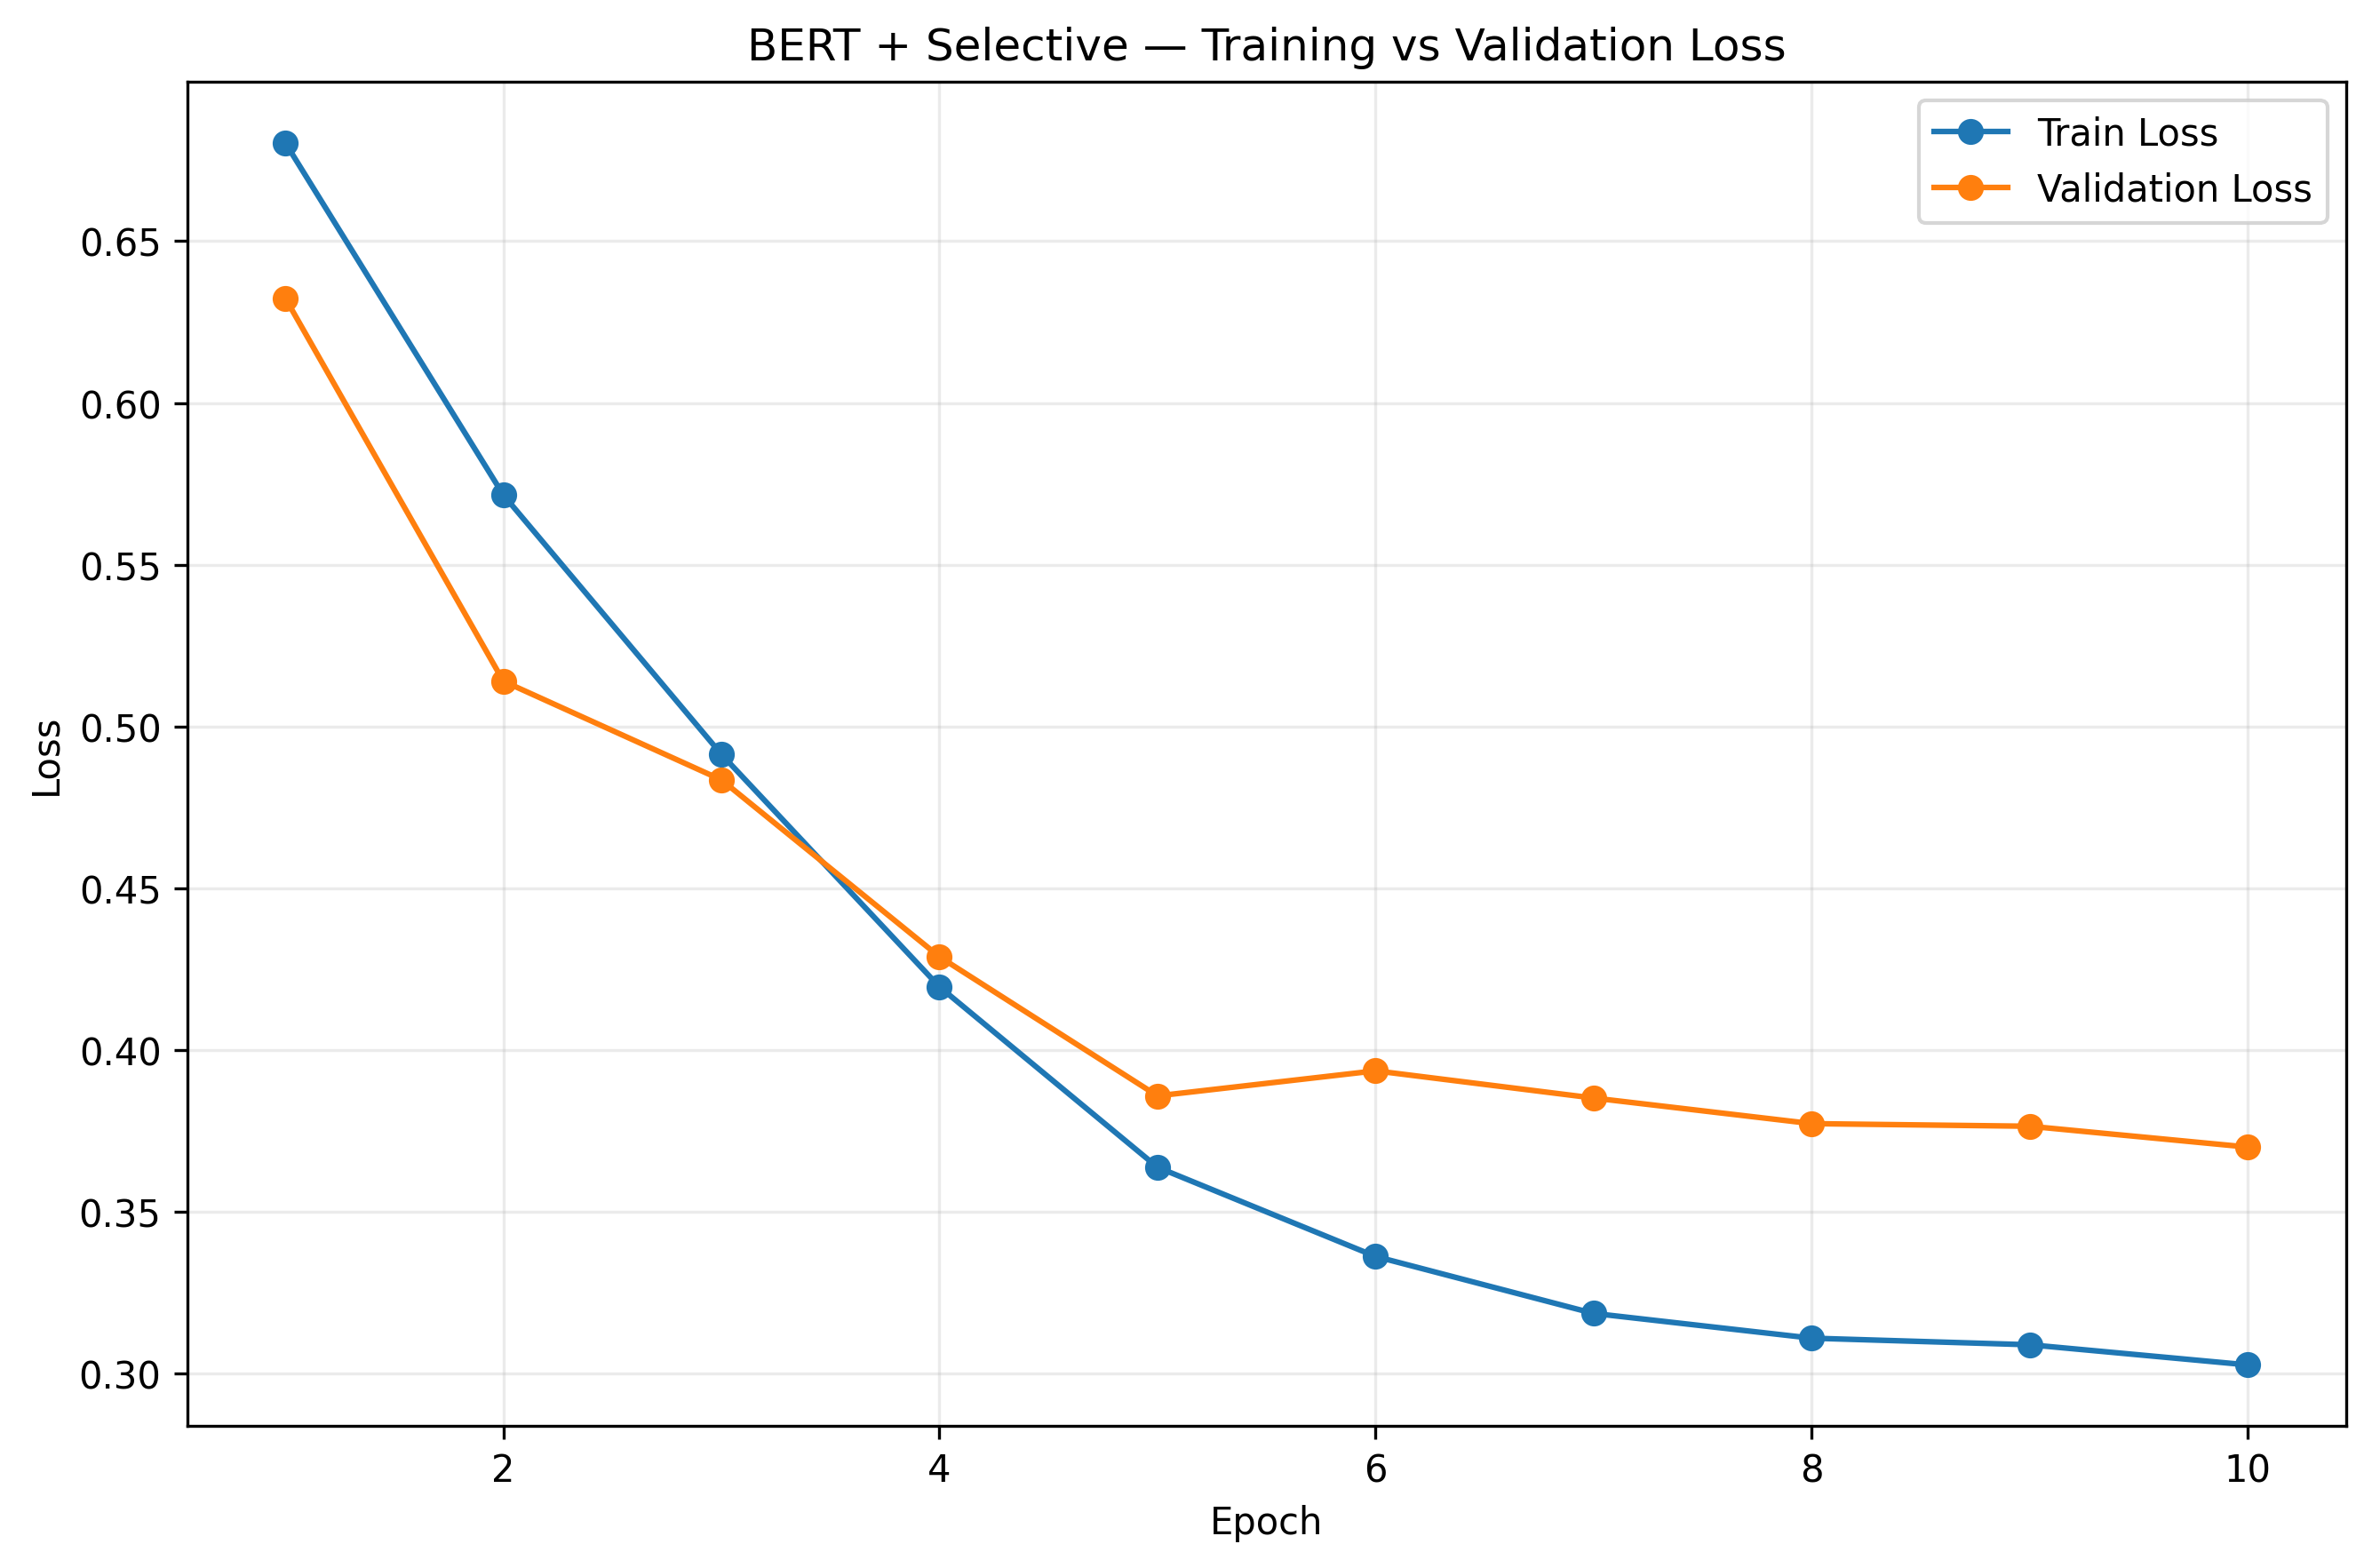


▶ bert_selective_f1_curve.png


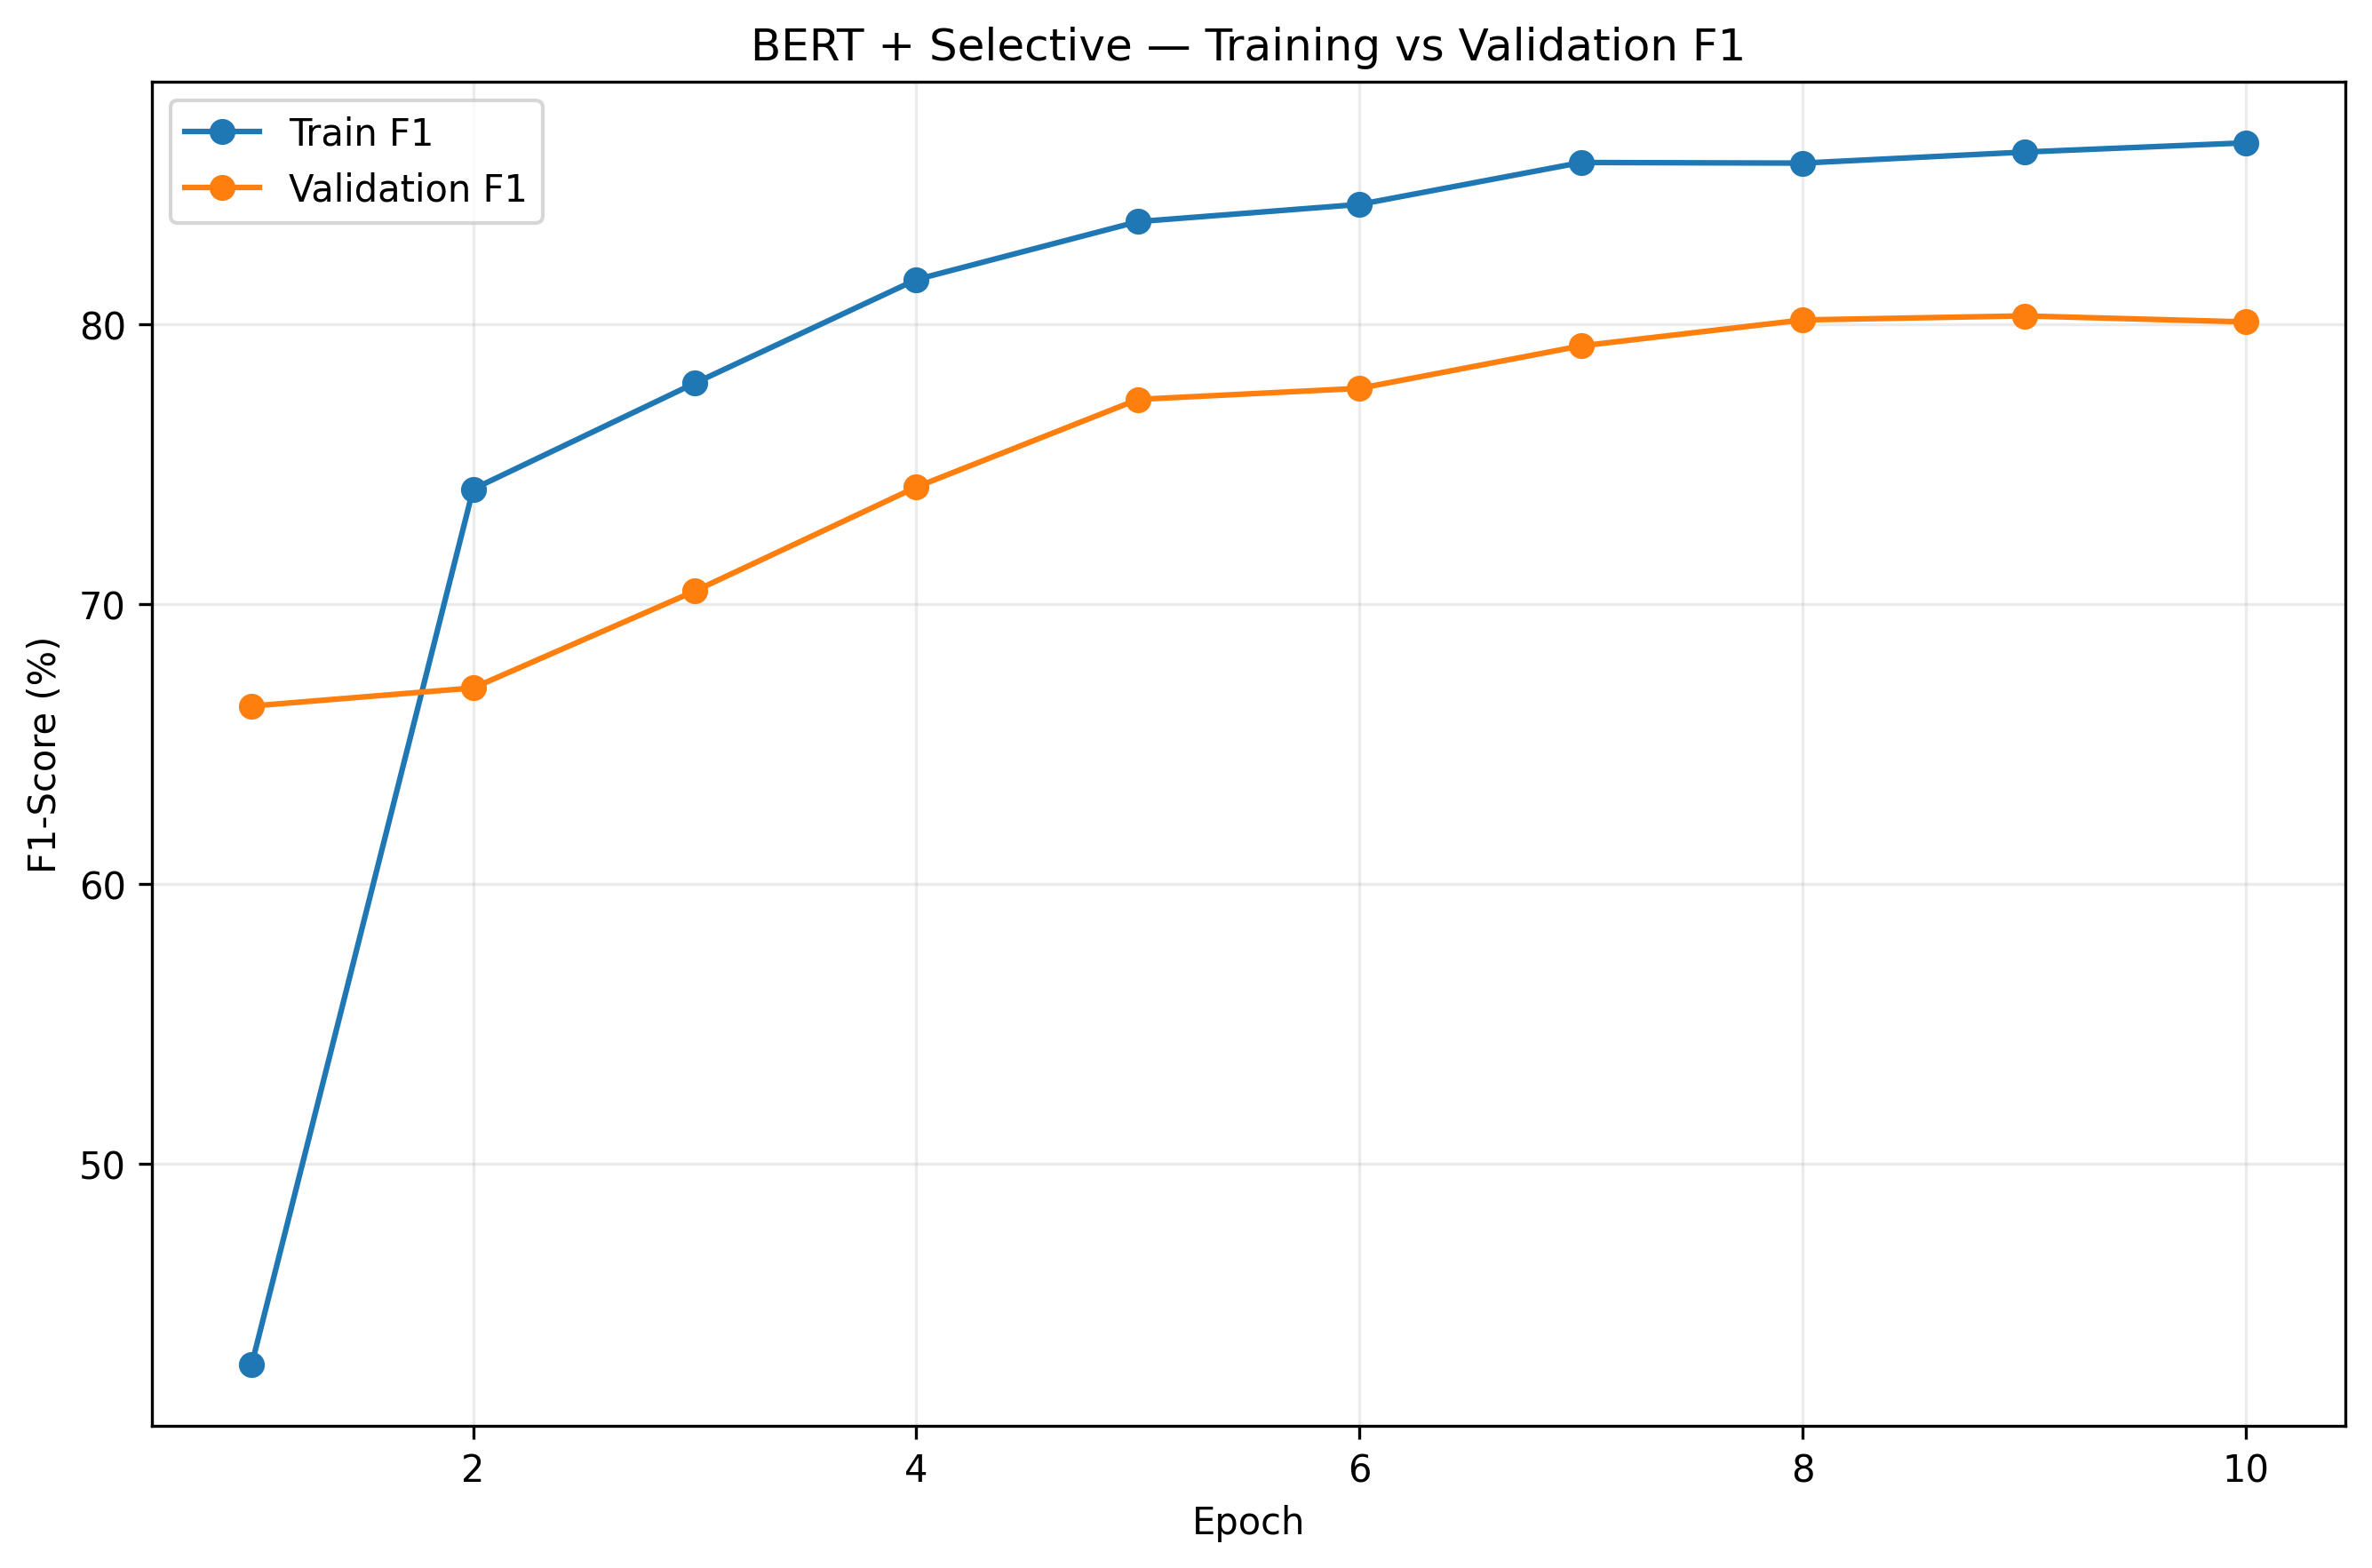


▶ bert_selective_validation_roc_auc.png


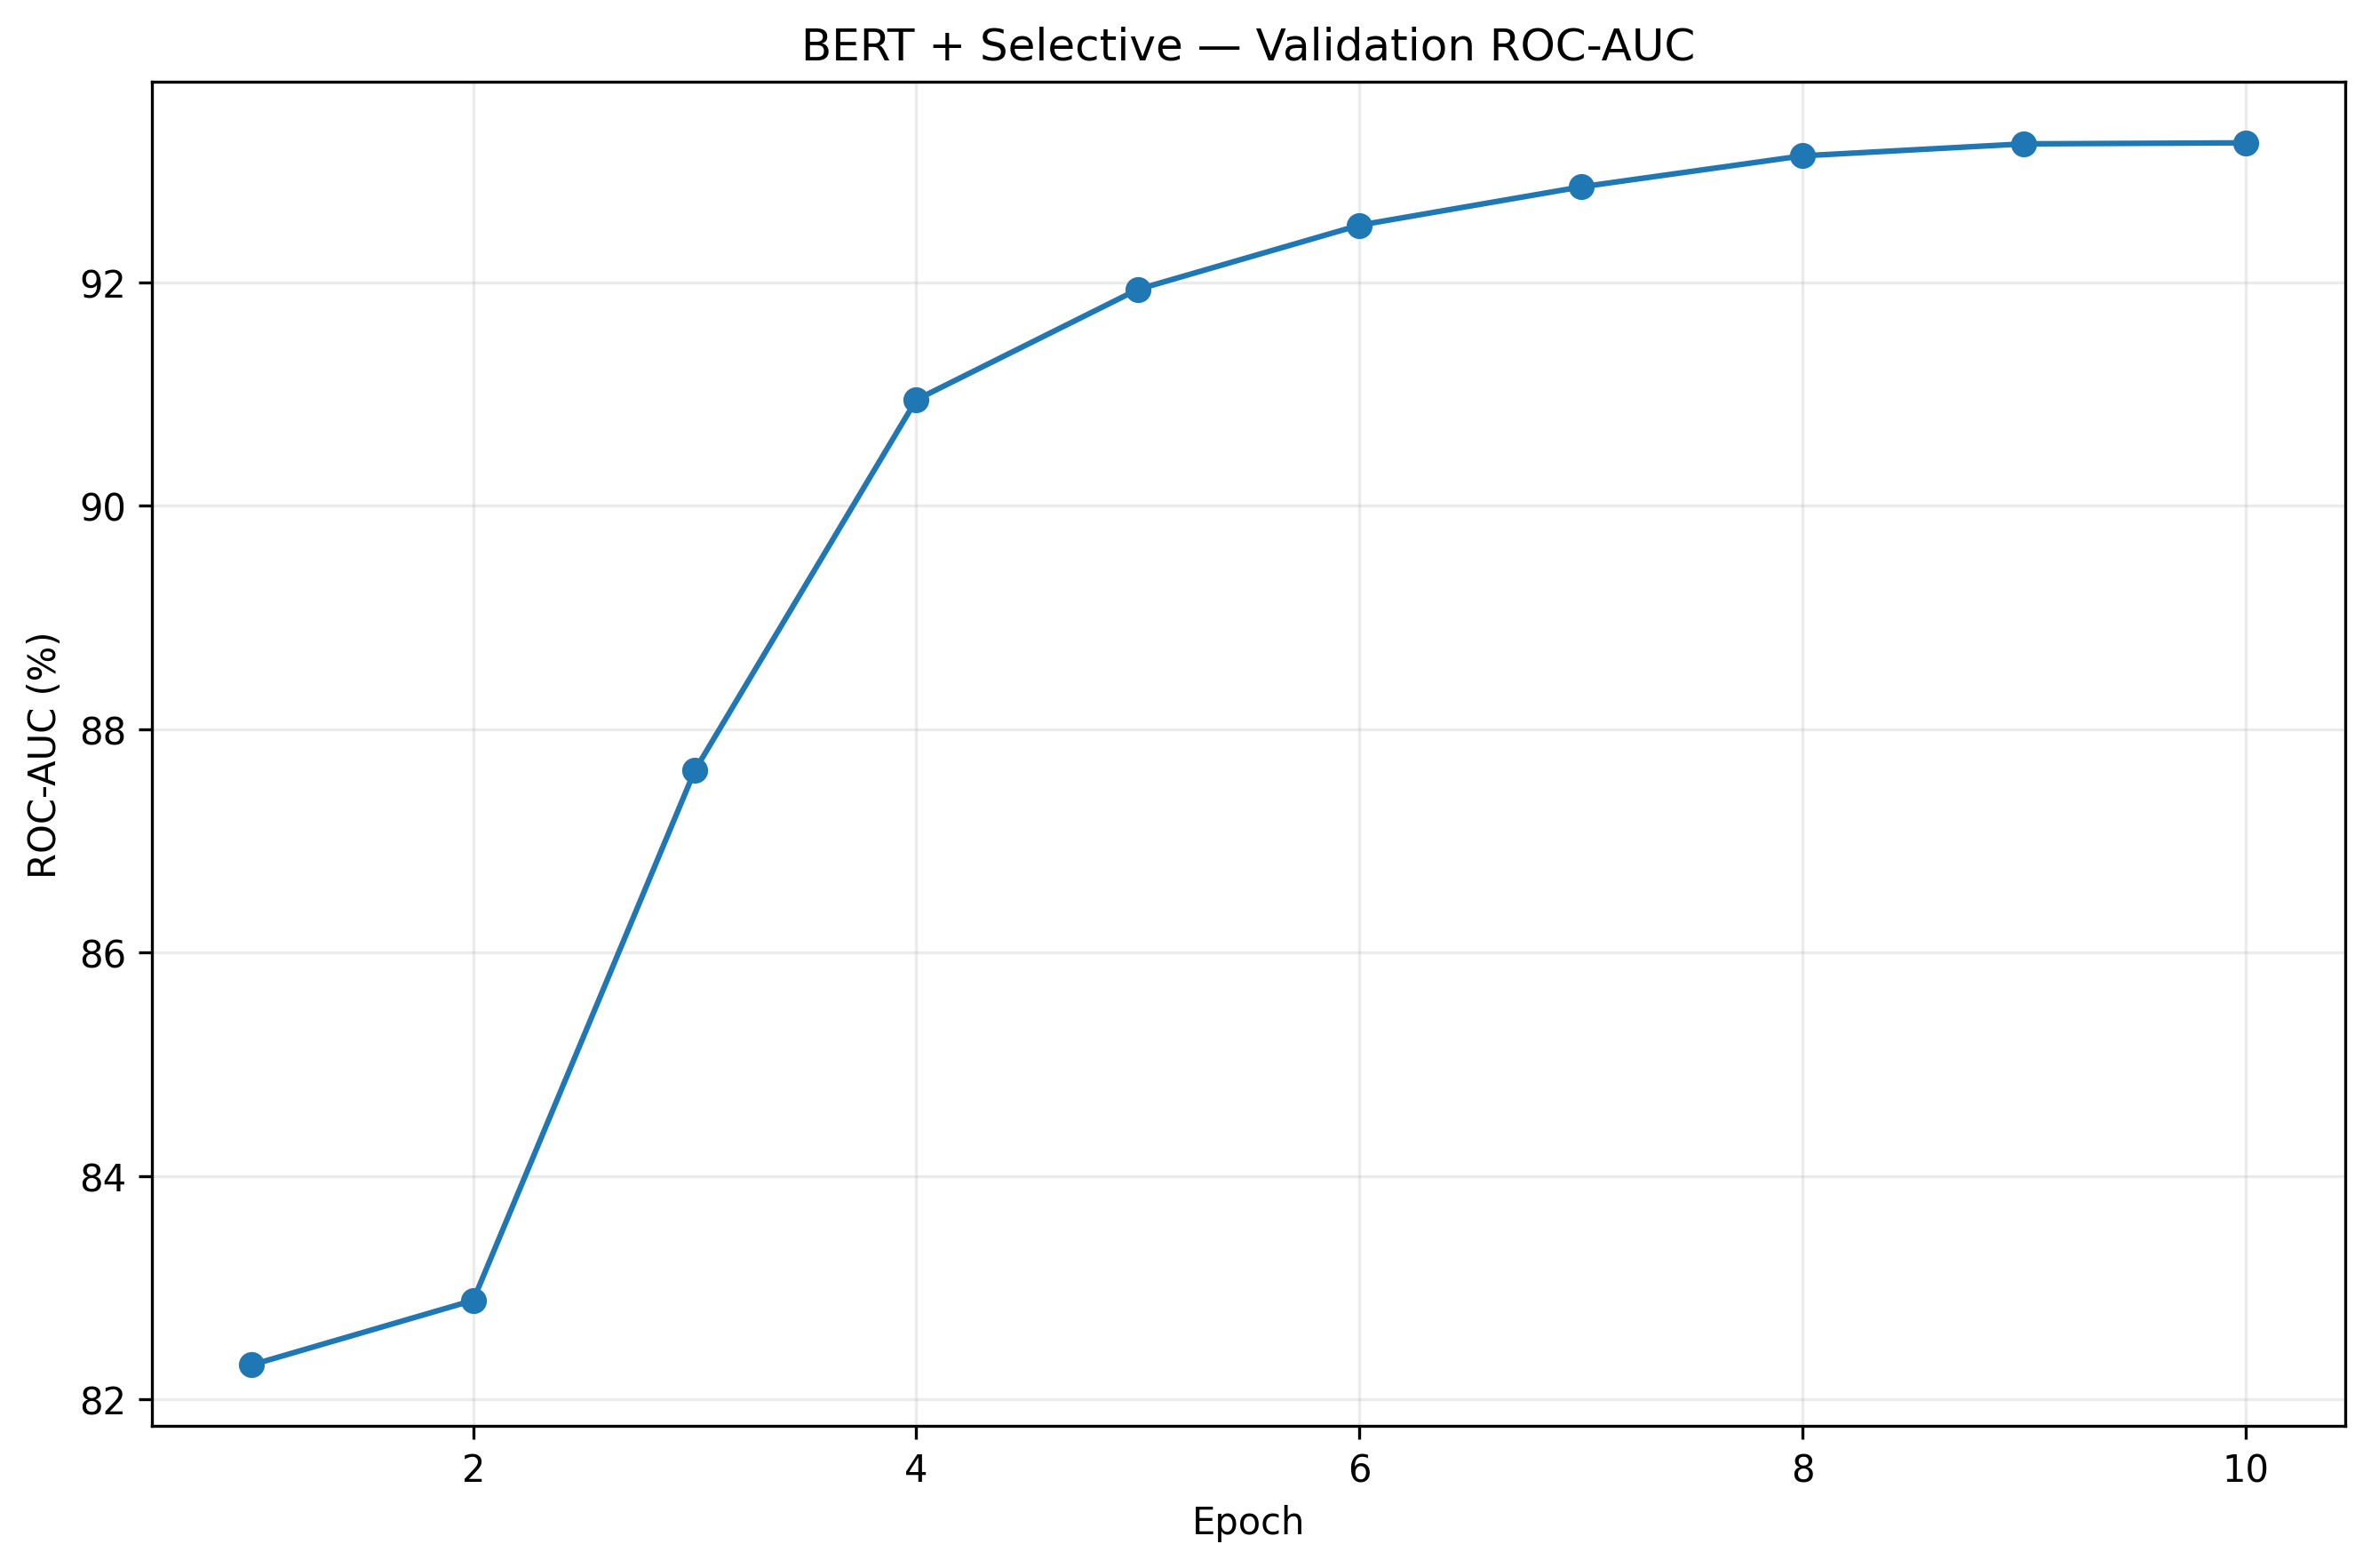


▶ bert_selective_validation_accuracy.png


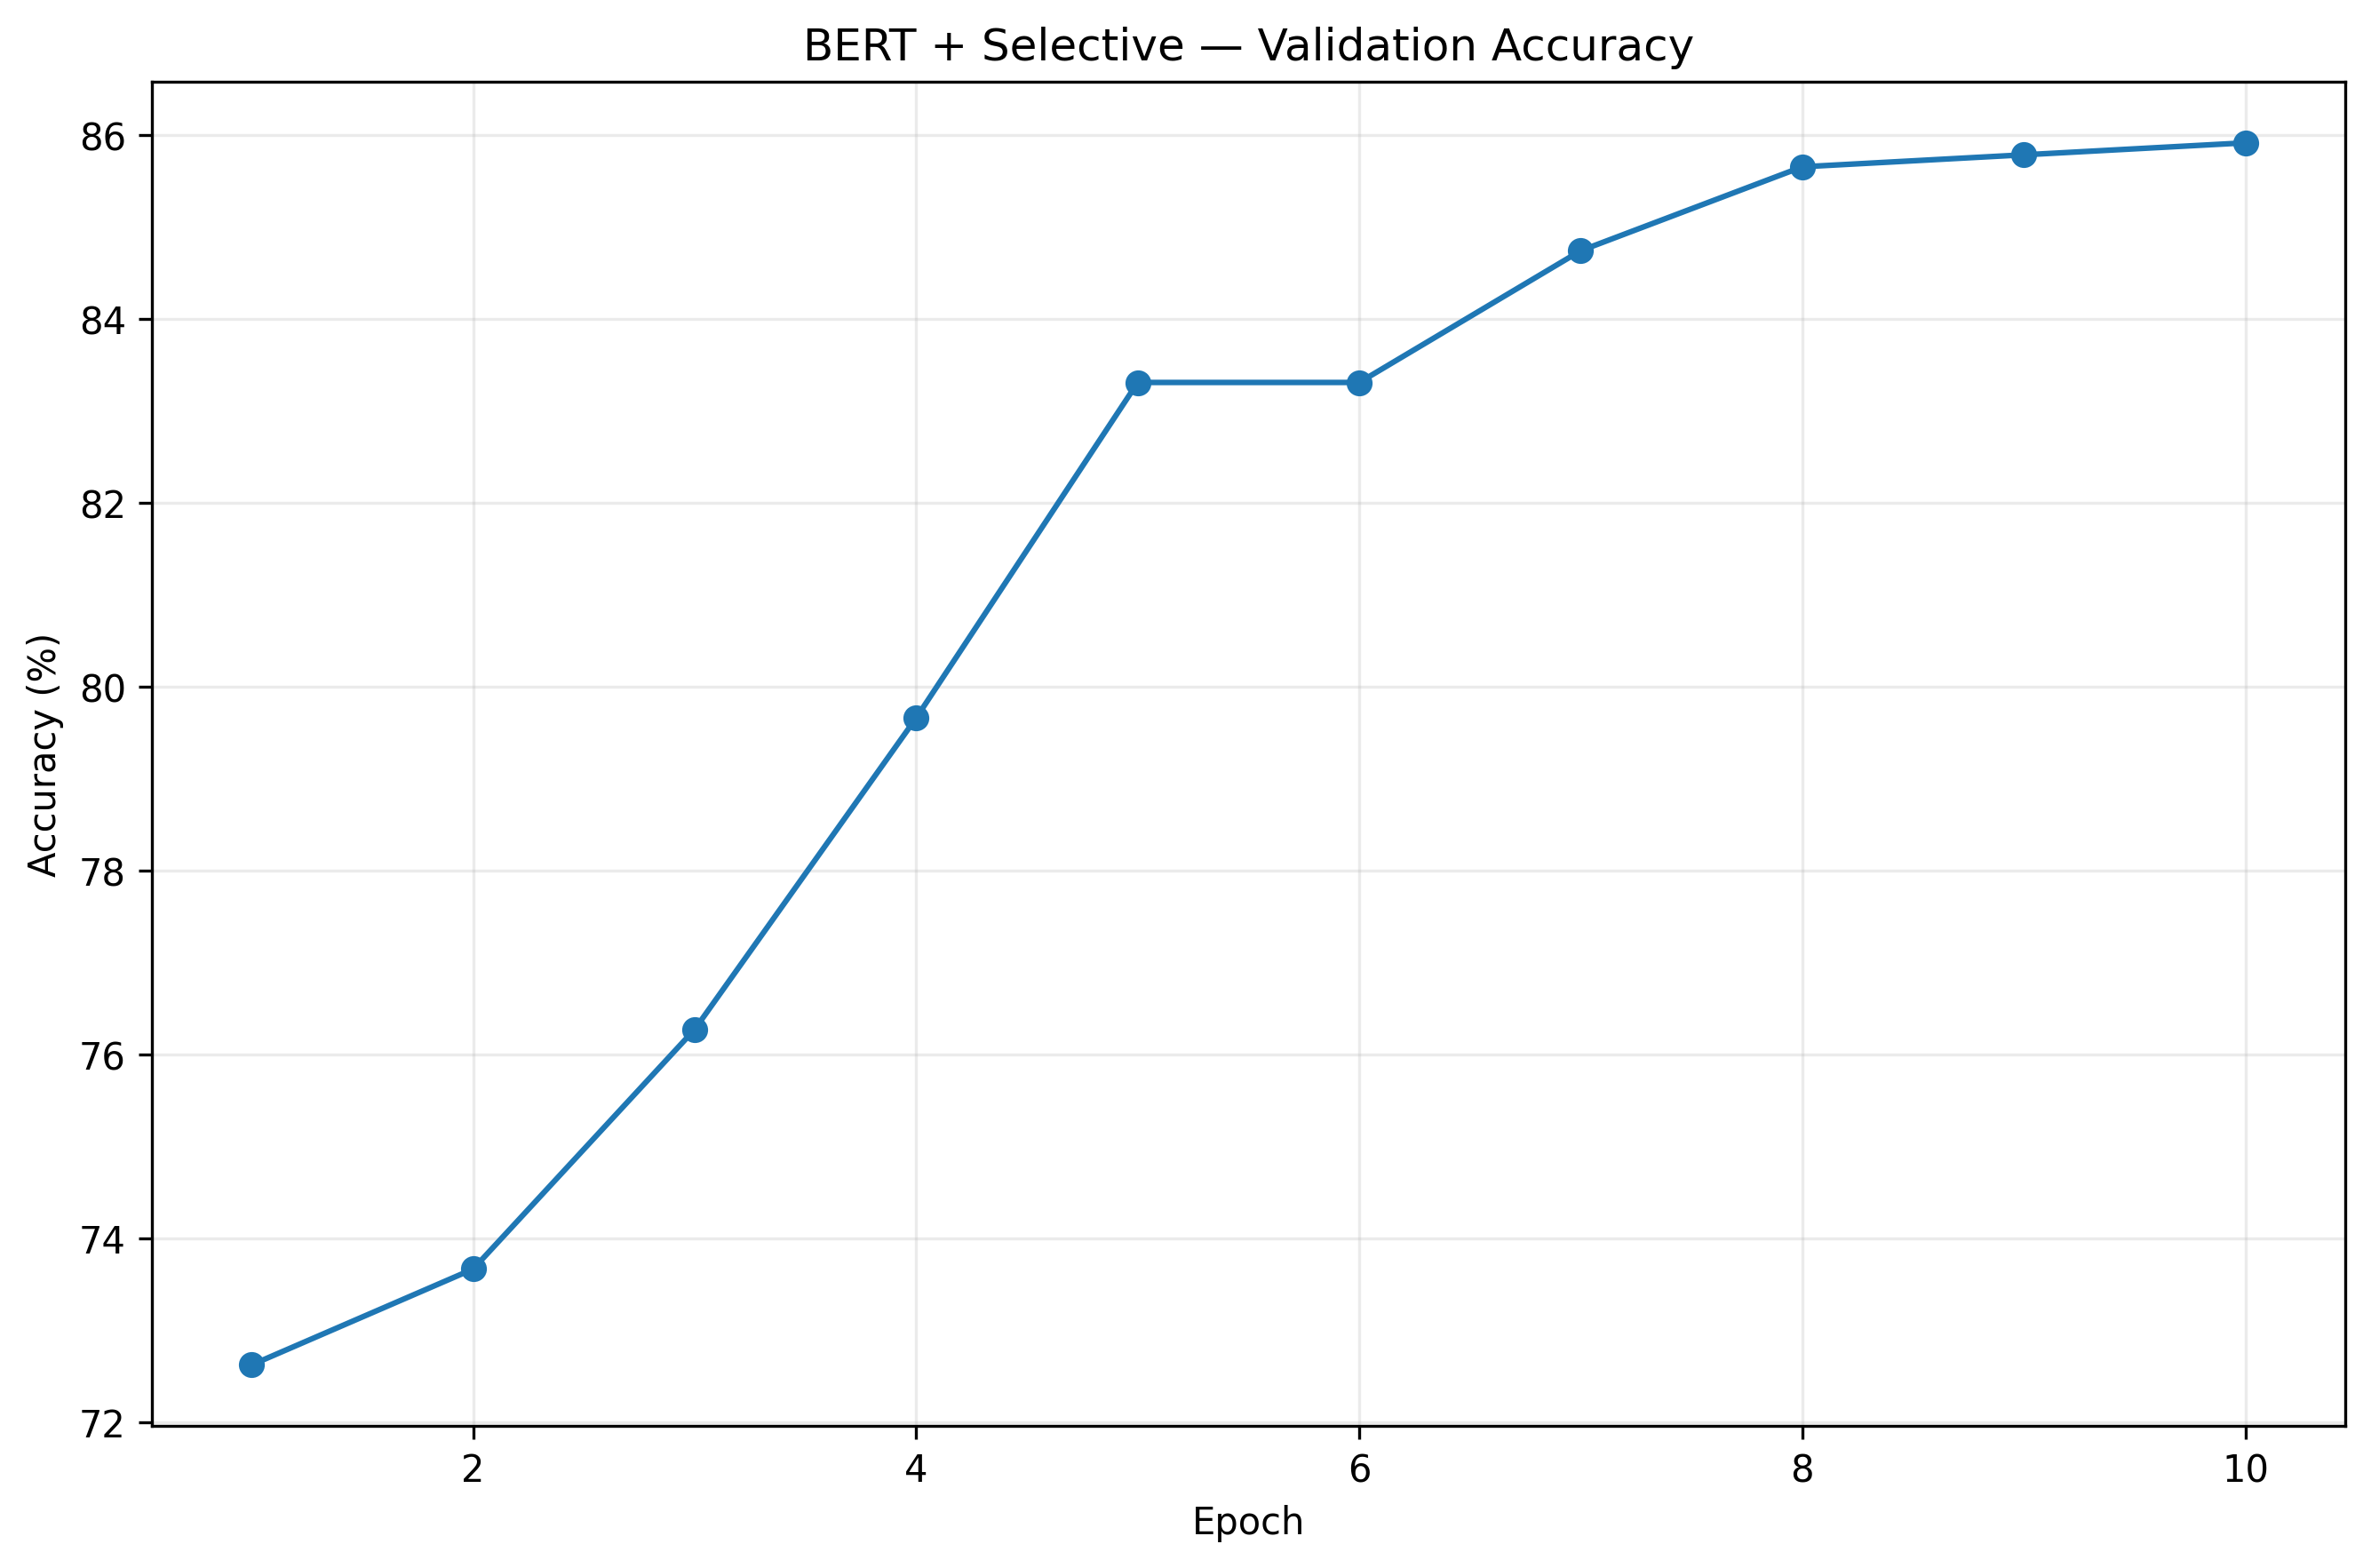


▶ bert_selective_final_metrics.png


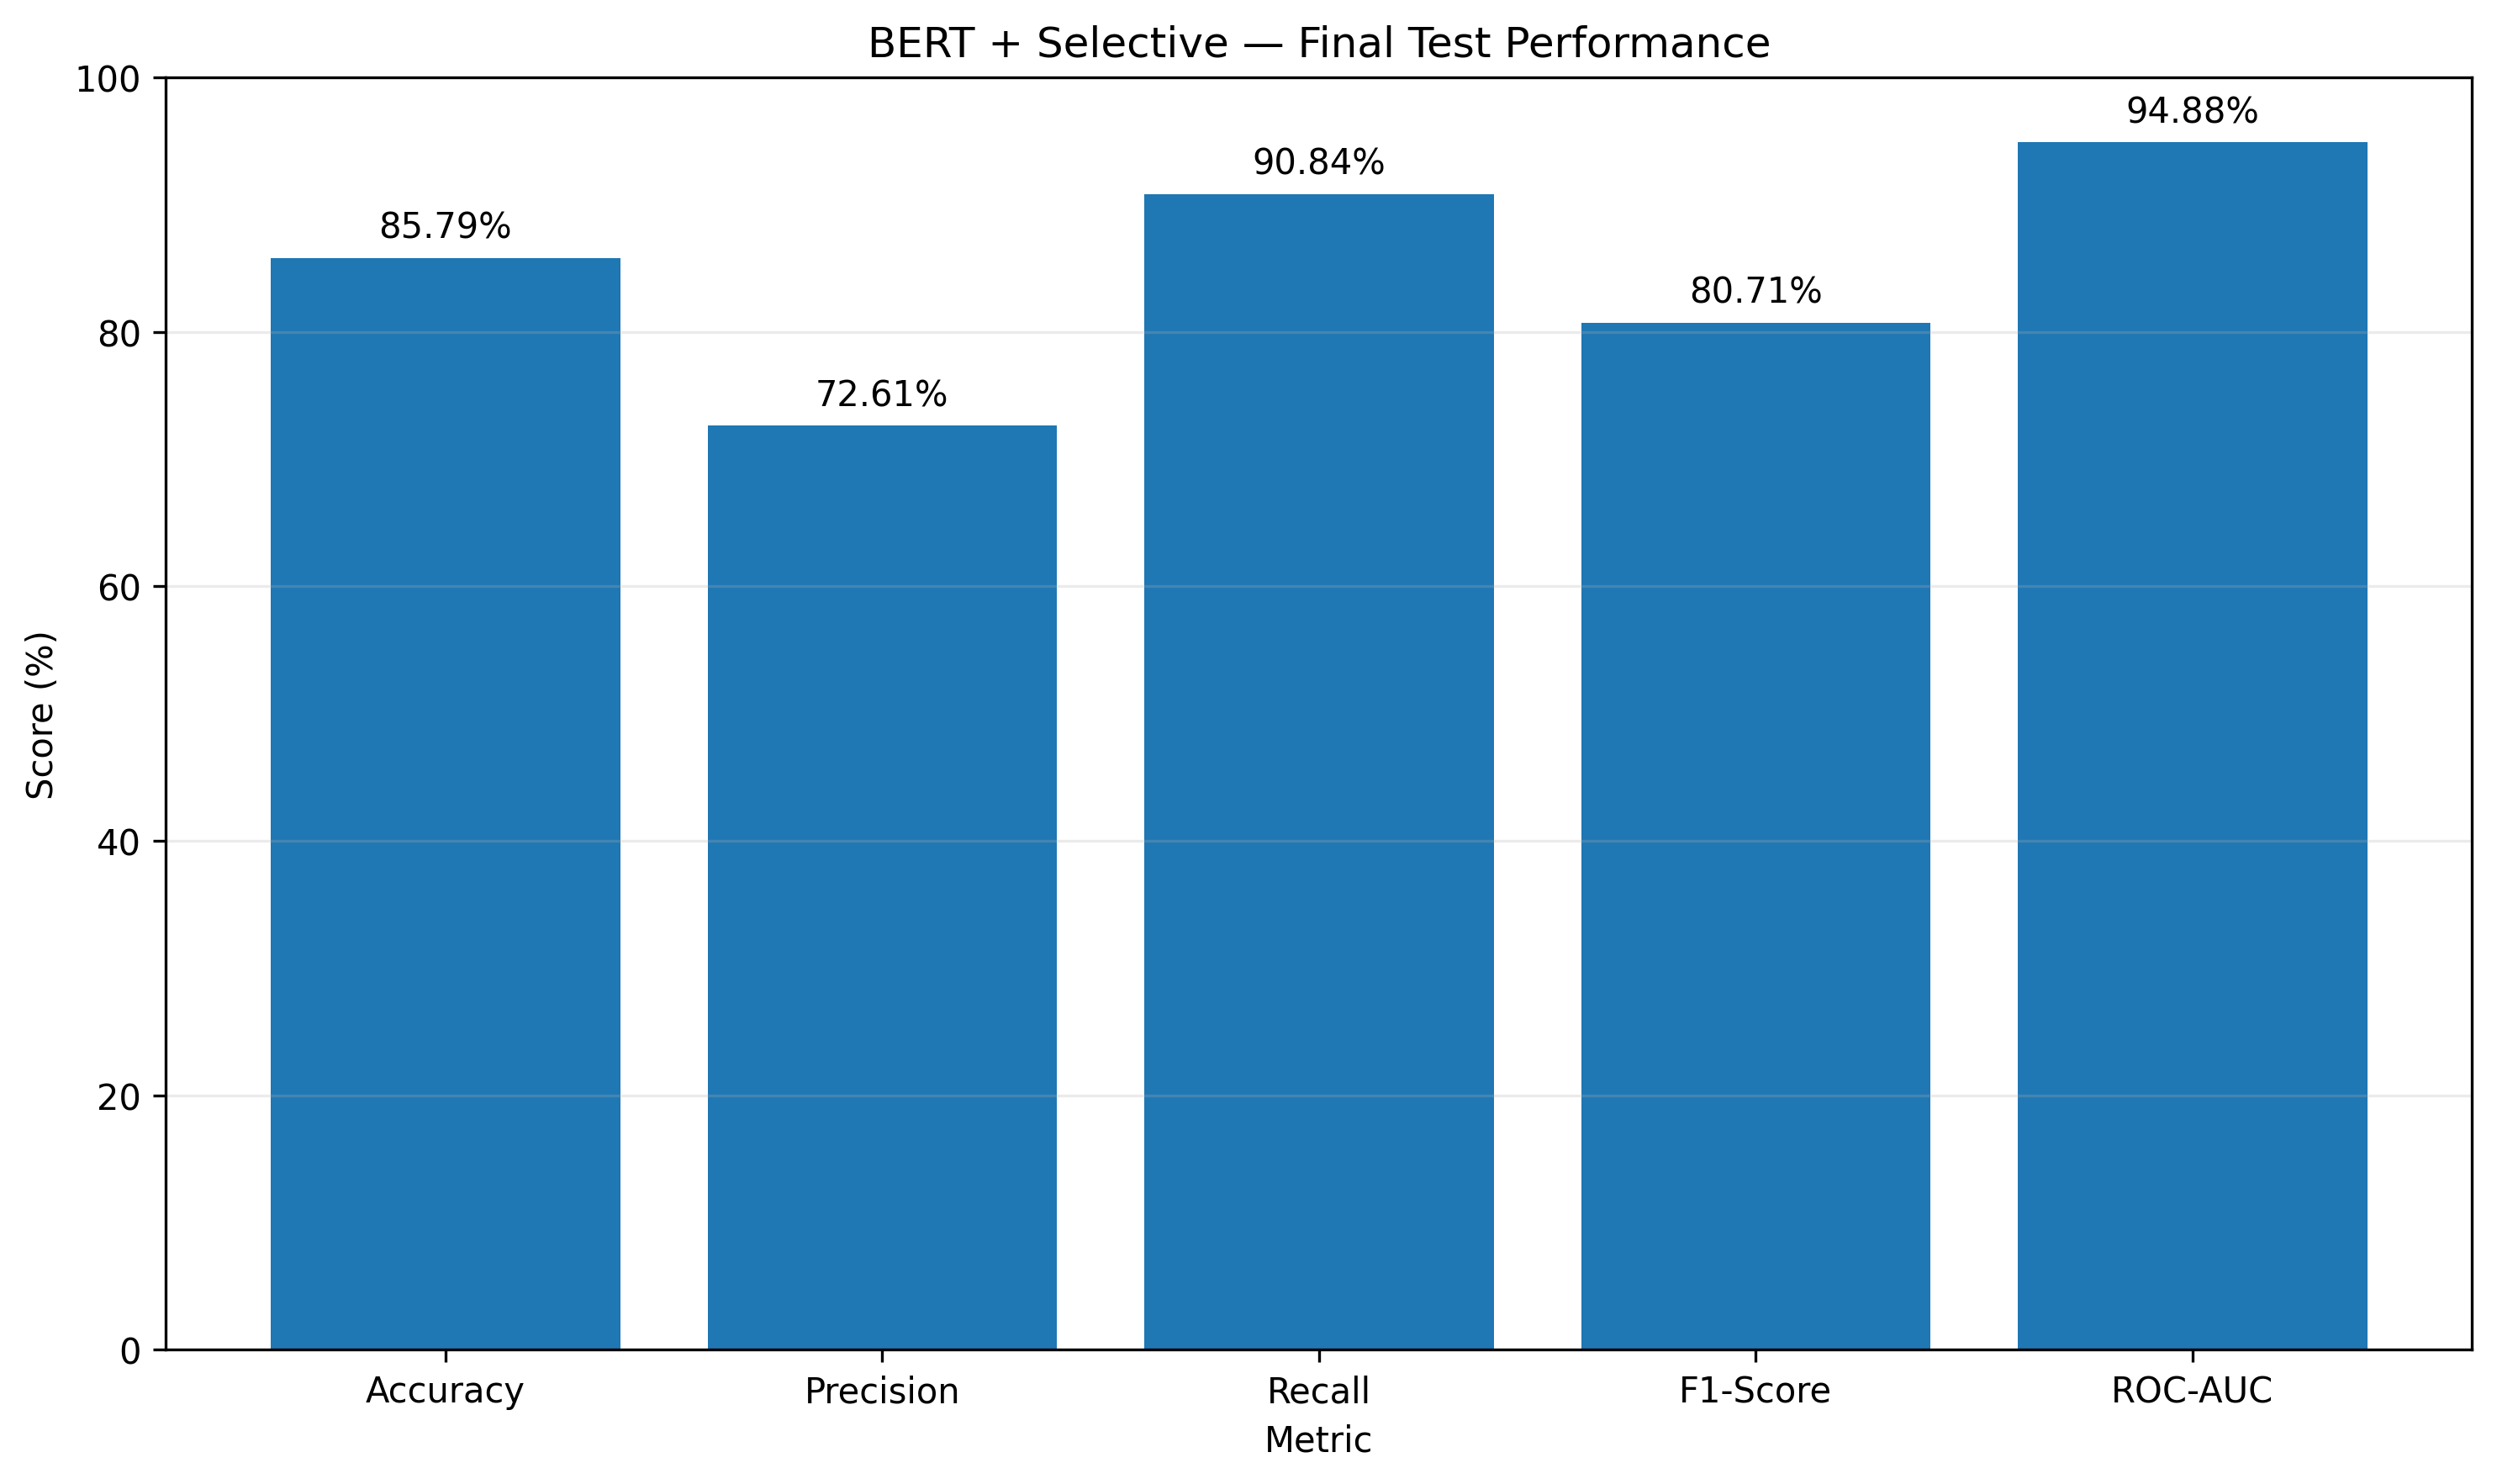


▶ bert_selective_confusion_matrix.png


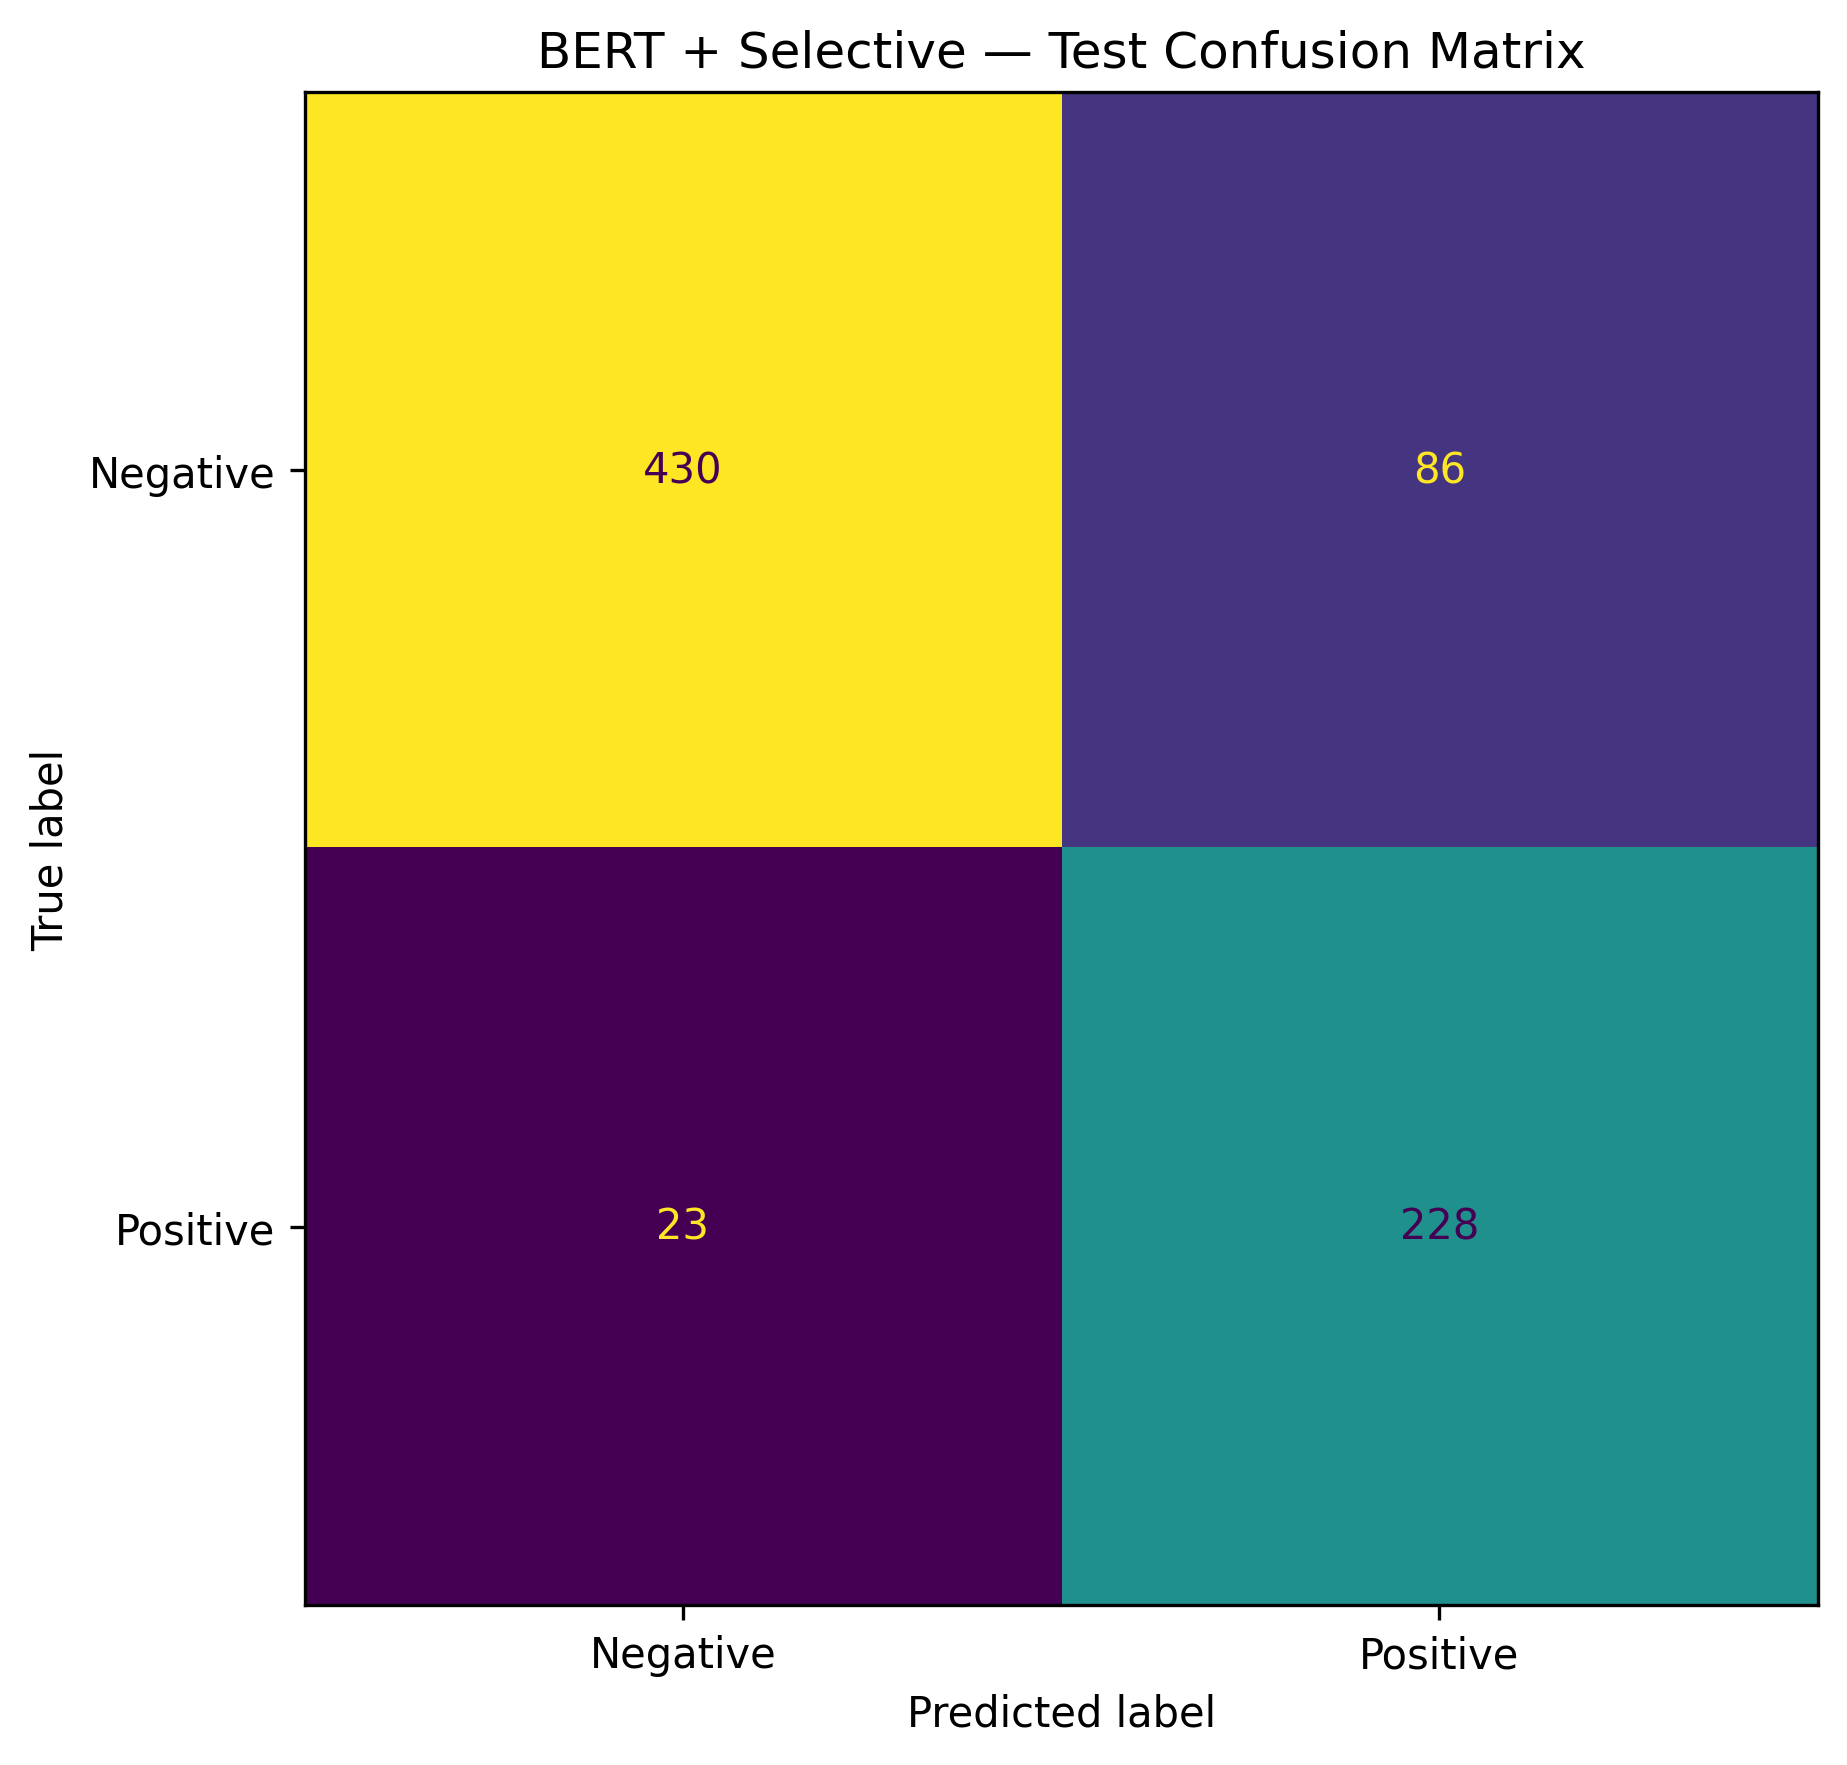


GRAPHS DISPLAYED: 6/6
✓ ALL 6 GRAPHS SAVED AND DISPLAYED


In [15]:
# ============================================================
# CELL 15 — DISPLAY BERT + SELECTIVE GRAPHS
# ============================================================

import os
from IPython.display import display, Image

print("=" * 60)
print("BERT + SELECTIVE — DISPLAYING SAVED GRAPHS")
print("=" * 60)

graph_files = [
    "bert_selective_loss_curve.png",
    "bert_selective_f1_curve.png",
    "bert_selective_validation_roc_auc.png",
    "bert_selective_validation_accuracy.png",
    "bert_selective_final_metrics.png",
    "bert_selective_confusion_matrix.png"
]

found = 0

for filename in graph_files:

    path = os.path.join(
        GRAPH_DIR,
        filename
    )

    if os.path.exists(path):

        print()
        print("▶", filename)

        display(
            Image(filename=path)
        )

        found += 1

    else:
        print(
            "✗ Missing:",
            filename
        )

print()
print("=" * 60)
print(
    f"GRAPHS DISPLAYED: "
    f"{found}/{len(graph_files)}"
)
print("=" * 60)

if found == len(graph_files):
    print(
        "✓ ALL 6 GRAPHS SAVED AND DISPLAYED"
    )
else:
    print(
        "⚠ Some graphs are missing"
    )
    

t-SNE REPRESENTATION ANALYSIS
BERT + SELECTIVE

✓ BERT model in evaluation mode

EXTRACTING FUSED REPRESENTATIONS
Processed batch 1/48
Processed batch 10/48
Processed batch 20/48
Processed batch 30/48
Processed batch 40/48
Processed batch 48/48

FUSED REPRESENTATION SUMMARY
Fused representation shape: (767, 832)
Test users: 767
Fused dimensions: 832
Negative users: 516
Positive users: 251
Metadata gate: 0.507816

PCA REDUCTION
Original dimensions: 832
PCA dimensions: 50
Variance retained: 86.25%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


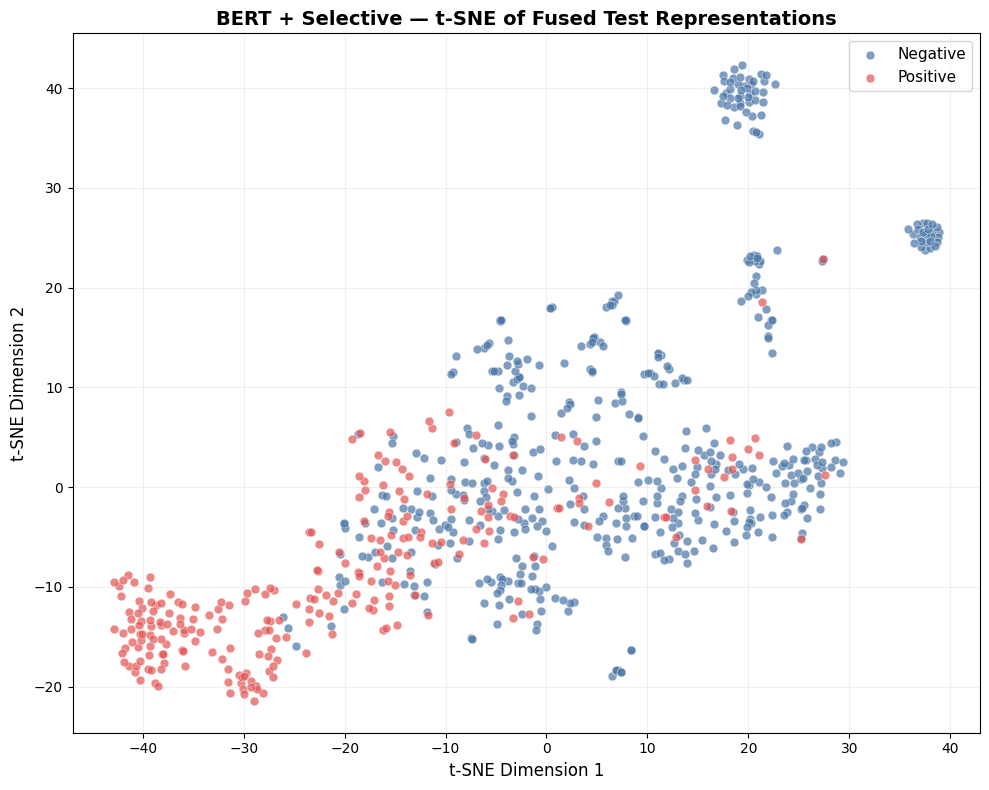


t-SNE ANALYSIS COMPLETE
✓ Exact BERT fused representation extracted
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ t-SNE graph saved:
/kaggle/working/bert_selective/results/explainability/tsne/bert_selective_tsne.png
✓ t-SNE graph displayed above
✓ Coordinates saved:
/kaggle/working/bert_selective/results/explainability/tsne/bert_selective_tsne_coordinates.csv
✓ Configuration saved


In [19]:
# ============================================================
# CELL 15 — BERT + SELECTIVE
# t-SNE REPRESENTATION ANALYSIS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("BERT + SELECTIVE")
print("=" * 70)

# ============================================================
# FIXED EXPLAINABILITY SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42

PCA_COMPONENTS = 50

TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000

np.random.seed(
    EXPLAINABILITY_SEED
)

torch.manual_seed(
    EXPLAINABILITY_SEED
)

# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    RESULT_DIR,
    "explainability"
)

TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)

os.makedirs(
    TSNE_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model.eval()

print()
print("✓ BERT model in evaluation mode")

# ============================================================
# EXTRACT EXACT FUSED REPRESENTATION
# ============================================================

fused_representations = []
test_labels = []

print()
print("=" * 70)
print("EXTRACTING FUSED REPRESENTATIONS")
print("=" * 70)

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        # ----------------------------------------------------
        # BERT ENCODER
        # ----------------------------------------------------

        encoder_output = model.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = (
            encoder_output.last_hidden_state
        )

        # ----------------------------------------------------
        # EXACT TEXT ATTENTION POOLING
        # ----------------------------------------------------

        projected = torch.tanh(
            model.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            model.attention_score(
                projected
            )
            .squeeze(-1)
        )

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                -1e9
            )
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states
            *
            attention_weights.unsqueeze(-1),
            dim=1
        )

        # ----------------------------------------------------
        # EXACT METADATA BRANCH
        # ----------------------------------------------------

        metadata_representation = (
            model.metadata_branch(
                metadata
            )
        )

        # ----------------------------------------------------
        # EXACT LEARNED METADATA GATE
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            model.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT FUSED REPRESENTATION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        fused_representations.append(
            fused.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy().tolist()
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == len(test_loader)
        ):

            print(
                f"Processed batch "
                f"{batch_idx}/{len(test_loader)}"
            )

# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)

test_labels = np.array(
    test_labels
)

# ============================================================
# REPRESENTATION SUMMARY
# ============================================================

print()
print("=" * 70)
print("FUSED REPRESENTATION SUMMARY")
print("=" * 70)

print(
    "Fused representation shape:",
    fused_representations.shape
)

print(
    "Test users:",
    len(test_labels)
)

print(
    "Fused dimensions:",
    fused_representations.shape[1]
)

print(
    "Negative users:",
    int(
        (test_labels == 0).sum()
    )
)

print(
    "Positive users:",
    int(
        (test_labels == 1).sum()
    )
)

print(
    "Metadata gate:",
    f"{float(metadata_gate.item()):.6f}"
)

assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)

assert np.isfinite(
    fused_representations
).all()

# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)

pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)

pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)

pca_representation = pca.fit_transform(
    fused_representations
)

pca_variance_retained = (
    pca.explained_variance_ratio_.sum()
)

print(
    "Original dimensions:",
    fused_representations.shape[1]
)

print(
    "PCA dimensions:",
    pca_representation.shape[1]
)

print(
    "Variance retained:",
    f"{pca_variance_retained * 100:.2f}%"
)

# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)

tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)

tsne_representation = tsne.fit_transform(
    pca_representation
)

print(
    "t-SNE output shape:",
    tsne_representation.shape
)

# ============================================================
# SAVE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[:, 0],

    "tsne_2":
        tsne_representation[:, 1],

    "label":
        test_labels

})

tsne_df["class"] = tsne_df[
    "label"
].map({
    0: "Negative",
    1: "Positive"
})

tsne_csv_path = os.path.join(
    TSNE_DIR,
    "bert_selective_tsne_coordinates.csv"
)

tsne_df.to_csv(
    tsne_csv_path,
    index=False
)

# ============================================================
# PUBLICATION-QUALITY t-SNE PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

negative_mask = (
    test_labels == 0
)

positive_mask = (
    test_labels == 1
)

plt.scatter(
    tsne_representation[
        negative_mask,
        0
    ],
    tsne_representation[
        negative_mask,
        1
    ],
    s=40,
    alpha=0.72,
    label="Negative",
    color="#4C78A8",
    edgecolors="white",
    linewidths=0.4
)

plt.scatter(
    tsne_representation[
        positive_mask,
        0
    ],
    tsne_representation[
        positive_mask,
        1
    ],
    s=40,
    alpha=0.72,
    label="Positive",
    color="#E45756",
    edgecolors="white",
    linewidths=0.4
)

plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)

plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)

plt.title(
    "BERT + Selective — "
    "t-SNE of Fused Test Representations",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

tsne_plot_path = os.path.join(
    TSNE_DIR,
    "bert_selective_tsne.png"
)

# SAVE
plt.savefig(
    tsne_plot_path,
    dpi=300,
    bbox_inches="tight"
)

# DISPLAY
plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

tsne_config = {

    "model":
        "BERT",

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "test_users":
        int(len(test_labels)),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        int(
            text_representation.shape[1]
        ),

    "metadata_representation_dimension":
        int(
            metadata_representation.shape[1]
        ),

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "pca_dimensions":
        int(
            pca_dimensions
        ),

    "pca_variance_retained":
        float(
            pca_variance_retained
        ),

    "tsne_dimensions":
        int(
            TSNE_COMPONENTS
        ),

    "tsne_perplexity":
        int(
            TSNE_PERPLEXITY
        ),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(
            TSNE_MAX_ITER
        ),

    "random_seed":
        EXPLAINABILITY_SEED,

    "metadata_gate":
        float(
            metadata_gate.item()
        )

}

with open(
    os.path.join(
        TSNE_DIR,
        "bert_selective_tsne_config.json"
    ),
    "w"
) as f:

    json.dump(
        tsne_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Exact BERT fused representation extracted"
)

print(
    "✓ PCA reduction completed"
)

print(
    "✓ t-SNE reduction completed"
)

print(
    "✓ t-SNE graph saved:"
)

print(
    tsne_plot_path
)

print(
    "✓ t-SNE graph displayed above"
)

print(
    "✓ Coordinates saved:"
)

print(
    tsne_csv_path
)

print(
    "✓ Configuration saved"
)

SHAP ANALYSIS
BERT + SELECTIVE

Total metadata features: 53

SHAP background samples: 50
Background dimensions: 53

SHAP test samples: 100
Negative: 50
Positive: 50

✓ BERT Selective model set to evaluation mode
✓ Model parameters frozen for SHAP

COMPUTING SHAP VALUES
Explained 1/100 test users
Explained 10/100 test users
Explained 20/100 test users
Explained 30/100 test users
Explained 40/100 test users
Explained 50/100 test users
Explained 60/100 test users
Explained 70/100 test users
Explained 80/100 test users
Explained 90/100 test users
Explained 100/100 test users

SHAP RESULT SUMMARY
SHAP matrix: (100, 53)
Metadata matrix: (100, 53)

TOP 20 SHAP FEATURES
                 feature  mean_abs_shap  mean_signed_shap
             lda_topic_2       0.036569          0.015967
              word_count       0.034479          0.007530
              engagement       0.023135         -0.002912
           emotion_score       0.017992          0.002799
             lda_topic_3       0.017853

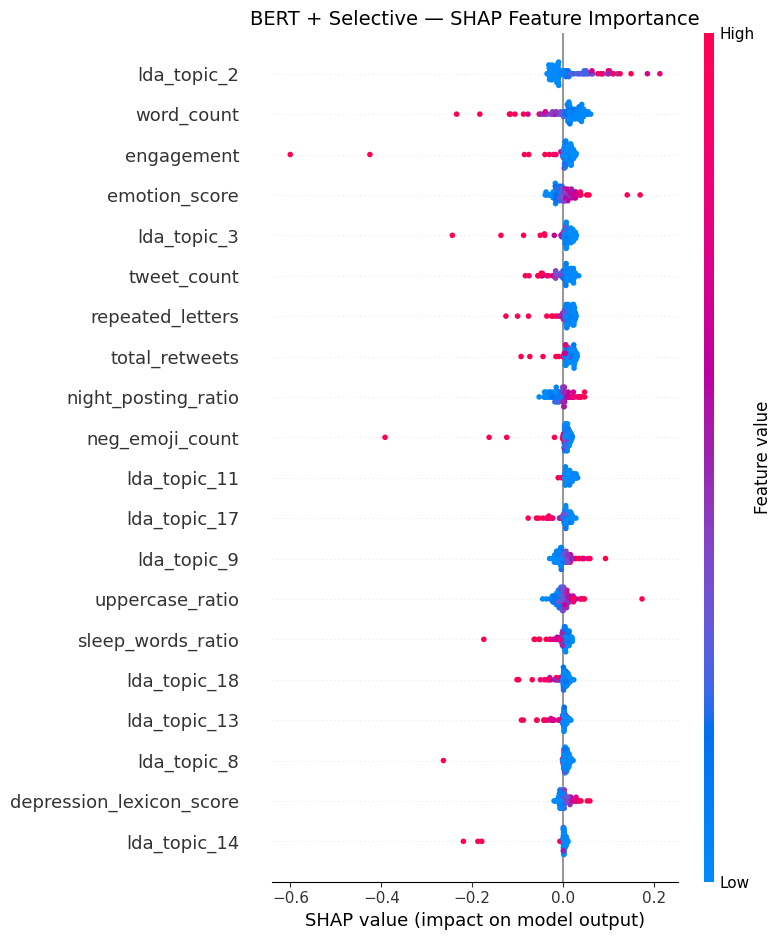

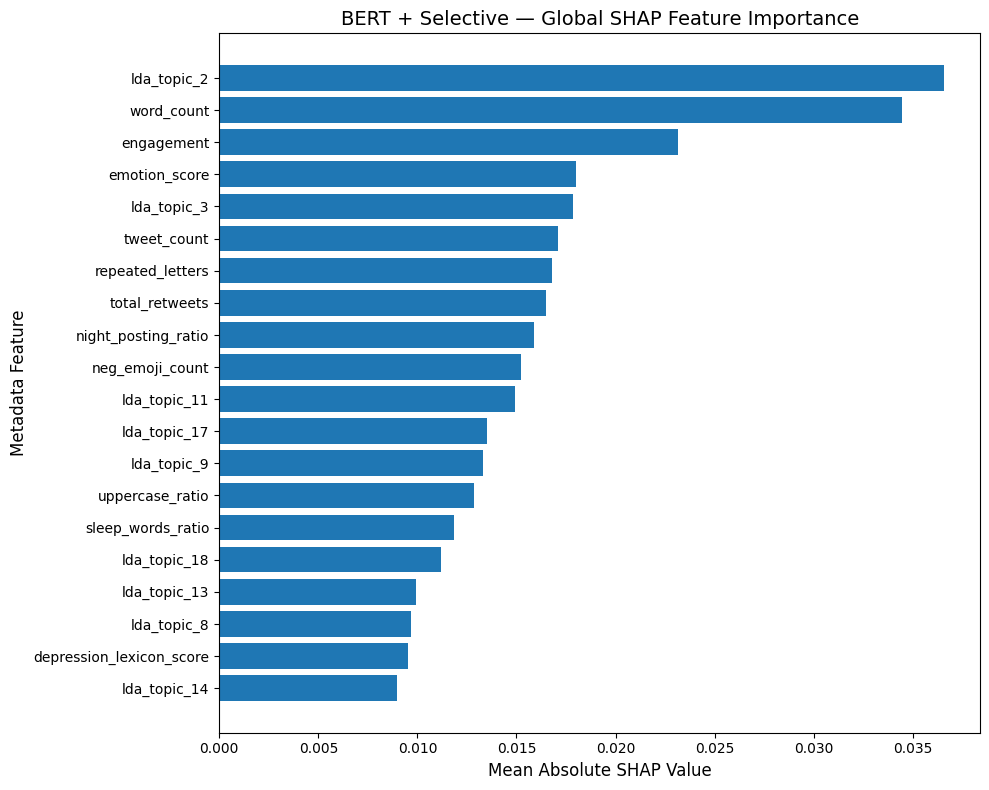


SHAP ANALYSIS COMPLETE
✓ 53 metadata features explained
✓ 50 negative + 50 positive users
✓ Training-only background used
✓ Positive-class logit explained
✓ SHAP values saved
✓ Feature ranking saved
✓ Beeswarm saved and displayed
✓ Bar plot saved and displayed
✓ Configuration saved

SHAP output directory: /kaggle/working/bert_selective/explainability/shap


In [21]:
# ============================================================
# EXPLAINABILITY — SHAP
# BERT + SELECTIVE
# GLOBAL METADATA FEATURE EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("SHAP ANALYSIS")
print("BERT + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42
SHAP_BACKGROUND_SIZE = 50
SHAP_TEST_SIZE_PER_CLASS = 50
SHAP_TOP_FEATURES = 20

np.random.seed(SHAP_SEED)
torch.manual_seed(SHAP_SEED)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

SHAP_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "shap"
)

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)


# ============================================================
# FEATURE NAMES
# ============================================================

feature_names = list(
    selected_metadata_names
)

assert len(feature_names) == 53

print()
print(
    "Total metadata features:",
    len(feature_names)
)


# ============================================================
# FIXED BACKGROUND DATA
# TRAINING USERS ONLY
# ============================================================

background_metadata = (
    train_dataset.metadata[
        :SHAP_BACKGROUND_SIZE
    ]
    .clone()
    .detach()
    .to(device)
)

print()
print(
    "SHAP background samples:",
    background_metadata.shape[0]
)

print(
    "Background dimensions:",
    background_metadata.shape[1]
)

assert background_metadata.shape[1] == 53


# ============================================================
# FIXED TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels_tensor = (
    test_dataset.labels
    .detach()
    .cpu()
)

negative_indices = torch.where(
    test_labels_tensor == 0
)[0].numpy()

positive_indices = torch.where(
    test_labels_tensor == 1
)[0].numpy()

assert len(
    negative_indices
) >= SHAP_TEST_SIZE_PER_CLASS

assert len(
    positive_indices
) >= SHAP_TEST_SIZE_PER_CLASS

shap_negative_indices = (
    negative_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_positive_indices = (
    positive_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_test_indices = np.concatenate(
    [
        shap_negative_indices,
        shap_positive_indices
    ]
)

print()
print(
    "SHAP test samples:",
    len(shap_test_indices)
)

print(
    "Negative:",
    len(shap_negative_indices)
)

print(
    "Positive:",
    len(shap_positive_indices)
)


# ============================================================
# MODEL WRAPPER
# ============================================================
# Explains metadata while keeping each user's
# Transformer text representation fixed.
# No model parameters are changed.

class MetadataSHAPWrapper(
    nn.Module
):

    def __init__(
        self,
        base_model,
        fixed_input_ids,
        fixed_attention_mask
    ):

        super().__init__()

        self.base_model = base_model

        self.fixed_input_ids = (
            fixed_input_ids
            .to(device)
        )

        self.fixed_attention_mask = (
            fixed_attention_mask
            .to(device)
        )

    def forward(
        self,
        metadata
    ):

        batch_size = metadata.size(0)

        input_ids = (
            self.fixed_input_ids
            .expand(
                batch_size,
                -1
            )
        )

        attention_mask = (
            self.fixed_attention_mask
            .expand(
                batch_size,
                -1
            )
        )

        output = self.base_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # Positive/depression class logit
        positive_logit = output[
            "logits"
        ][:, 1:2]

        return positive_logit


# ============================================================
# MODEL PREPARATION
# USE THE NOTEBOOK'S EXISTING VARIABLE:
# model
# ============================================================

model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print()
print("✓ BERT Selective model set to evaluation mode")
print("✓ Model parameters frozen for SHAP")


# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_values = []
all_metadata_values = []
all_explained_labels = []

print()
print("=" * 70)
print("COMPUTING SHAP VALUES")
print("=" * 70)


for count, test_index in enumerate(
    shap_test_indices,
    start=1
):

    sample = test_dataset[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
    )

    metadata_sample = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    label = int(
        sample["labels"].item()
    )


    # --------------------------------------------------------
    # USER-SPECIFIC SHAP WRAPPER
    # --------------------------------------------------------

    wrapper = MetadataSHAPWrapper(
        model,
        input_ids,
        attention_mask
    ).to(device)

    wrapper.eval()


    # --------------------------------------------------------
    # GRADIENT SHAP
    # --------------------------------------------------------

    explainer = shap.GradientExplainer(
        wrapper,
        background_metadata
    )

    shap_result = explainer.shap_values(
        metadata_sample
    )


    # --------------------------------------------------------
    # HANDLE SHAP OUTPUT FORMAT
    # --------------------------------------------------------

    if isinstance(
        shap_result,
        list
    ):

        shap_array = np.asarray(
            shap_result[0]
        )

    else:

        shap_array = np.asarray(
            shap_result
        )

    shap_array = np.squeeze(
        shap_array
    )

    assert shap_array.shape == (
        53,
    )


    all_shap_values.append(
        shap_array
    )

    all_metadata_values.append(
        metadata_sample
        .detach()
        .cpu()
        .numpy()
        .squeeze(0)
    )

    all_explained_labels.append(
        label
    )


    if (
        count == 1
        or count % 10 == 0
        or count == len(
            shap_test_indices
        )
    ):

        print(
            f"Explained "
            f"{count}/"
            f"{len(shap_test_indices)} "
            f"test users"
        )


# ============================================================
# COMBINE RESULTS
# ============================================================

all_shap_values = np.vstack(
    all_shap_values
)

all_metadata_values = np.vstack(
    all_metadata_values
)

all_explained_labels = np.array(
    all_explained_labels
)

print()
print("=" * 70)
print("SHAP RESULT SUMMARY")
print("=" * 70)

print(
    "SHAP matrix:",
    all_shap_values.shape
)

print(
    "Metadata matrix:",
    all_metadata_values.shape
)

assert all_shap_values.shape == (
    len(shap_test_indices),
    53
)

assert all_metadata_values.shape == (
    len(shap_test_indices),
    53
)

assert np.isfinite(
    all_shap_values
).all()


# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(
        all_shap_values
    ),
    axis=0
)

mean_signed_shap = np.mean(
    all_shap_values,
    axis=0
)

feature_importance_df = pd.DataFrame({

    "feature":
        feature_names,

    "mean_abs_shap":
        mean_abs_shap,

    "mean_signed_shap":
        mean_signed_shap

})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print()
print("=" * 70)
print("TOP 20 SHAP FEATURES")
print("=" * 70)

print(
    feature_importance_df
    .head(SHAP_TOP_FEATURES)
    .to_string(
        index=False
    )
)


# ============================================================
# SAVE SHAP VALUES
# ============================================================

shap_values_df = pd.DataFrame(
    all_shap_values,
    columns=feature_names
)

shap_values_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "bert_selective_shap_values.csv"
    ),
    index=False
)


# ============================================================
# SAVE FEATURE IMPORTANCE
# ============================================================

feature_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "bert_selective_shap_feature_importance.csv"
    ),
    index=False
)


# ============================================================
# SAVE TEST USER INFORMATION
# ============================================================

explained_users_df = pd.DataFrame({

    "test_index":
        shap_test_indices,

    "label":
        all_explained_labels

})

explained_users_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "bert_selective_shap_test_users.csv"
    ),
    index=False
)


# ============================================================
# SHAP BEESWARM
# ============================================================

plt.figure(
    figsize=(11, 8)
)

shap.summary_plot(
    all_shap_values,
    all_metadata_values,
    feature_names=feature_names,
    max_display=SHAP_TOP_FEATURES,
    show=False
)

plt.title(
    "BERT + Selective — SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_beeswarm_path = os.path.join(
    SHAP_DIR,
    "bert_selective_shap_beeswarm.png"
)

plt.savefig(
    shap_beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# SHAP BAR
# ============================================================

top_features = (
    feature_importance_df
    .head(
        SHAP_TOP_FEATURES
    )
    .iloc[::-1]
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"]
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=12
)

plt.ylabel(
    "Metadata Feature",
    fontsize=12
)

plt.title(
    "BERT + Selective — Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_bar_path = os.path.join(
    SHAP_DIR,
    "bert_selective_shap_bar.png"
)

plt.savefig(
    shap_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# SAVE CONFIG
# ============================================================

shap_config = {

    "model":
        "BERT",

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "metadata_features":
        53,

    "background_samples":
        SHAP_BACKGROUND_SIZE,

    "test_samples_per_class":
        SHAP_TEST_SIZE_PER_CLASS,

    "total_explained_users":
        len(shap_test_indices),

    "target":
        "Positive/depression class logit",

    "explainer":
        "GradientExplainer",

    "text_fixed_per_user":
        True,

    "random_seed":
        SHAP_SEED,

    "top_features":
        SHAP_TOP_FEATURES
}

with open(
    os.path.join(
        SHAP_DIR,
        "bert_selective_shap_config.json"
    ),
    "w"
) as f:

    json.dump(
        shap_config,
        f,
        indent=2
    )


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)

print("✓ 53 metadata features explained")
print("✓ 50 negative + 50 positive users")
print("✓ Training-only background used")
print("✓ Positive-class logit explained")
print("✓ SHAP values saved")
print("✓ Feature ranking saved")
print("✓ Beeswarm saved and displayed")
print("✓ Bar plot saved and displayed")
print("✓ Configuration saved")

print()
print(
    "SHAP output directory:",
    SHAP_DIR
)

GRAD-CAM ANALYSIS
BERT + SELECTIVE

✓ BERT Selective model ready

Test users: 767

SELECTED CASES
TP: Test Index = 1 | True = 1 | Pred = 1 | Positive Probability = 0.8267
TN: Test Index = 0 | True = 0 | Pred = 0 | Positive Probability = 0.2559
FP: Test Index = 8 | True = 0 | Pred = 1 | Positive Probability = 0.5210
FN: Test Index = 35 | True = 1 | Pred = 0 | Positive Probability = 0.3931

COMPUTING GRAD-CAM

Processing TP (Test Index 1)
✓ TP complete

Processing TN (Test Index 0)
✓ TN complete

Processing FP (Test Index 8)
✓ FP complete

Processing FN (Test Index 35)
✓ FN complete


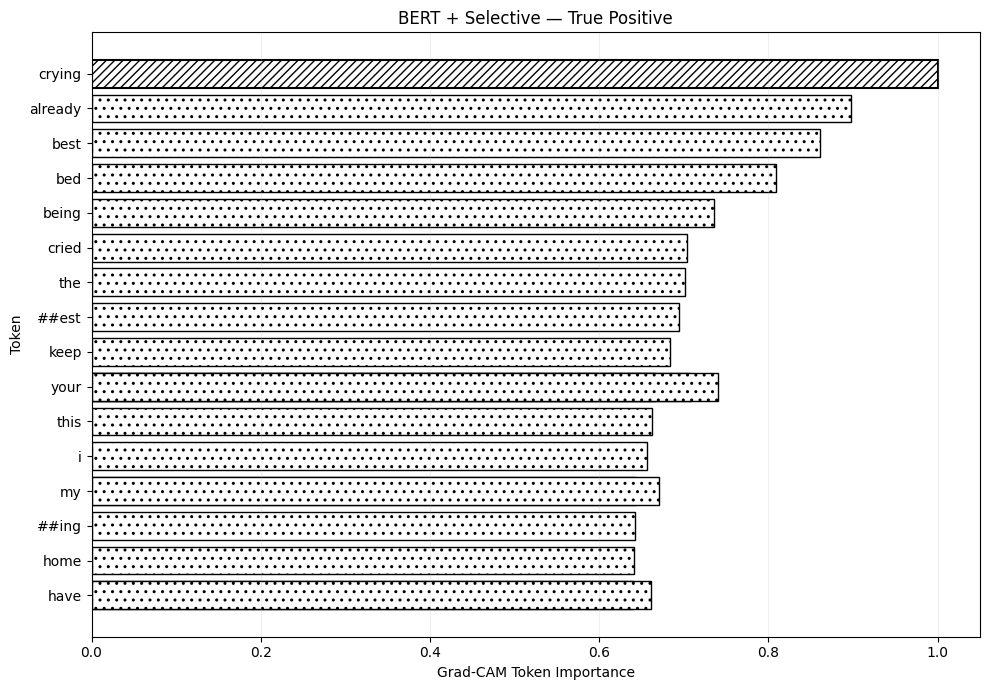

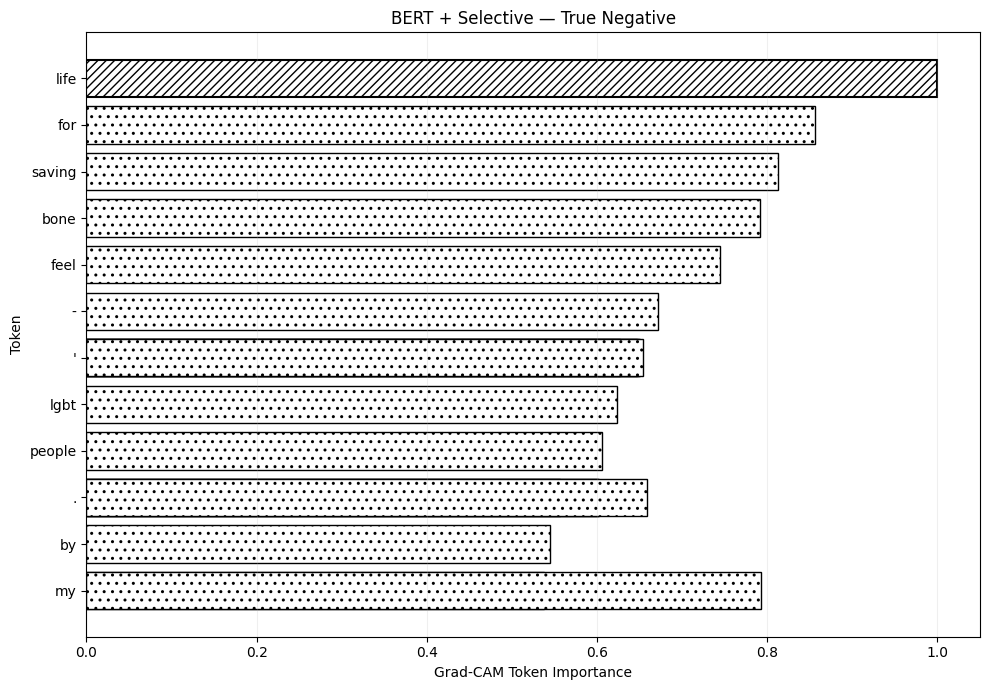

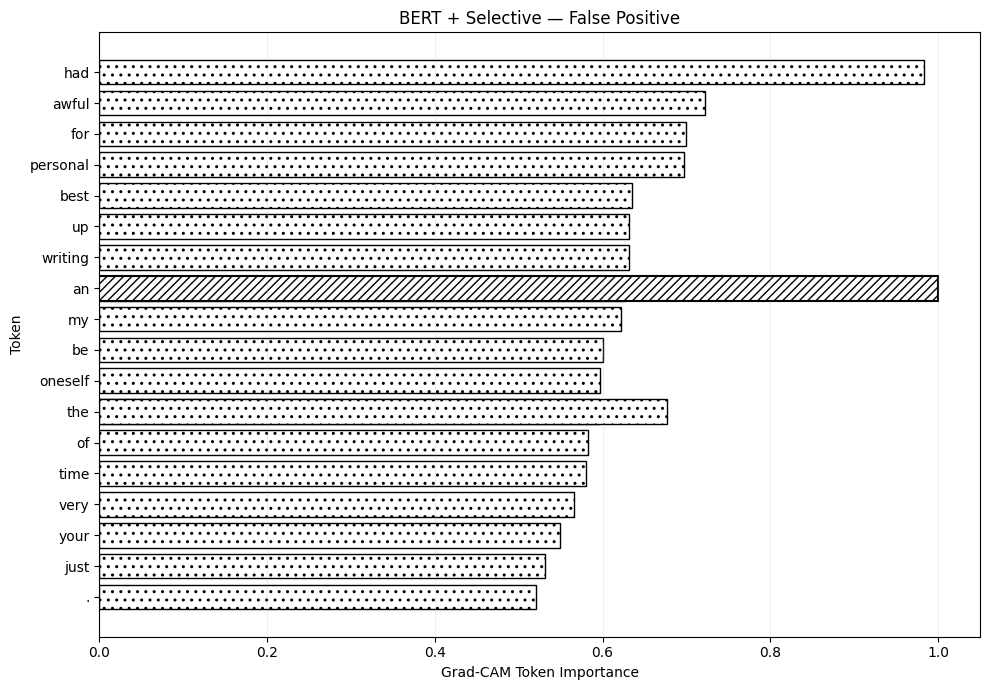

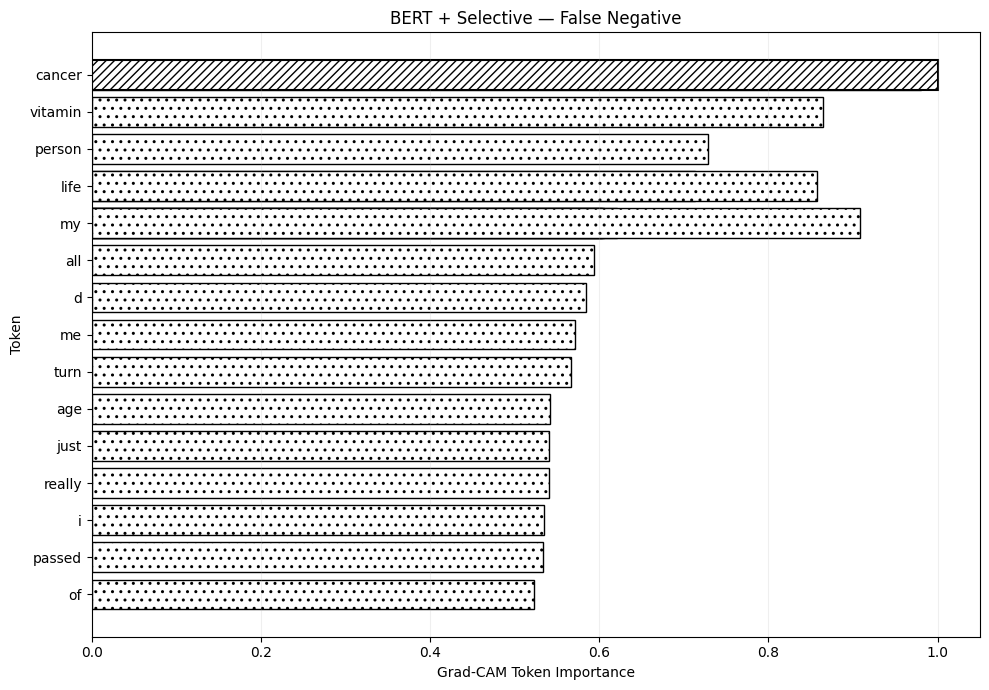


GRAD-CAM ANALYSIS COMPLETE

TP — True: 1 | Predicted: 1 | P(Positive): 0.8267
Top tokens: [('crying', 1.0), ('already', 0.8978888988494873), ('best', 0.8603379130363464), ('bed', 0.808362603187561), ('your', 0.7403746247291565), ('being', 0.7356455326080322), ('your', 0.708668053150177), ('cried', 0.703223466873169), ('the', 0.7014110088348389), ('##est', 0.6946297883987427), ('keep', 0.6833323240280151), ('my', 0.6706968545913696), ('your', 0.6654273271560669), ('this', 0.6627329587936401), ('have', 0.6608571410179138), ('i', 0.6569497585296631), ('my', 0.6434453725814819), ('##ing', 0.6424044370651245), ('home', 0.6408354043960571), ('have', 0.6398214101791382)]

TN — True: 0 | Predicted: 0 | P(Positive): 0.2559
Top tokens: [('life', 1.0), ('for', 0.855869710445404), ('saving', 0.8131620287895203), ('my', 0.7931908965110779), ('bone', 0.7920703291893005), ('feel', 0.7450159192085266), ('-', 0.6721222996711731), ('.', 0.6589047908782959), ("'", 0.6537679433822632), ("'", 0.6505532264

In [22]:
# ============================================================
# EXPLAINABILITY — GRAD-CAM
# BERT + SELECTIVE
# TOKEN-LEVEL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print("=" * 70)
print("GRAD-CAM ANALYSIS")
print("BERT + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED SETTINGS
# ============================================================

GRADCAM_SEED = 42
TOP_TOKENS = 20

np.random.seed(GRADCAM_SEED)
torch.manual_seed(GRADCAM_SEED)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print()
print("✓ BERT Selective model ready")


# ============================================================
# COLLECT TEST PREDICTIONS
# ============================================================

test_true = []
test_pred = []
test_prob = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).long()

        test_true.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_pred.extend(
            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_prob.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )


test_true = np.asarray(
    test_true
)

test_pred = np.asarray(
    test_pred
)

test_prob = np.asarray(
    test_prob
)


print()
print(
    "Test users:",
    len(test_true)
)


# ============================================================
# DETERMINISTIC TP / TN / FP / FN CASES
# ============================================================

tp_candidates = np.where(
    (test_true == 1) &
    (test_pred == 1)
)[0]

tn_candidates = np.where(
    (test_true == 0) &
    (test_pred == 0)
)[0]

fp_candidates = np.where(
    (test_true == 0) &
    (test_pred == 1)
)[0]

fn_candidates = np.where(
    (test_true == 1) &
    (test_pred == 0)
)[0]


assert len(tp_candidates) > 0
assert len(tn_candidates) > 0
assert len(fp_candidates) > 0
assert len(fn_candidates) > 0


selected_cases = {

    "TP":
        int(tp_candidates[0]),

    "TN":
        int(tn_candidates[0]),

    "FP":
        int(fp_candidates[0]),

    "FN":
        int(fn_candidates[0])
}


print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)

for case_name, index in selected_cases.items():

    print(
        f"{case_name}: "
        f"Test Index = {index} | "
        f"True = {test_true[index]} | "
        f"Pred = {test_pred[index]} | "
        f"Positive Probability = {test_prob[index]:.4f}"
    )


# ============================================================
# GRAD-CAM FUNCTION
# ============================================================

def compute_gradcam(
    sample_index
):

    sample = test_dataset[
        sample_index
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
        .to(device)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
        .to(device)
    )

    metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )


    # --------------------------------------------------------
    # ENABLE GRADIENTS
    # --------------------------------------------------------

    model.zero_grad(
        set_to_none=True
    )


    # --------------------------------------------------------
    # BERT ENCODER
    # --------------------------------------------------------

    encoder_output = model.encoder(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    hidden_states = (
        encoder_output.last_hidden_state
    )

    # Enable gradients on final hidden states
    # while keeping model weights frozen
    hidden_states.requires_grad_(True)
    hidden_states.retain_grad()


    # --------------------------------------------------------
    # ATTENTION POOLING
    # --------------------------------------------------------

    projected = torch.tanh(
        model.attention_projection(
            hidden_states
        )
    )

    attention_scores = (
        model.attention_score(
            projected
        )
        .squeeze(-1)
    )

    attention_scores = (
        attention_scores.masked_fill(
            attention_mask == 0,
            -1e9
        )
    )

    attention_weights = torch.softmax(
        attention_scores,
        dim=1
    )


    text_representation = torch.sum(
        hidden_states *
        attention_weights.unsqueeze(-1),
        dim=1
    )


    # --------------------------------------------------------
    # METADATA BRANCH
    # --------------------------------------------------------

    metadata_representation = (
        model.metadata_branch(
            metadata
        )
    )


    metadata_gate = torch.sigmoid(
        model.metadata_beta
    )

    gated_metadata = (
        metadata_gate *
        metadata_representation
    )


    # --------------------------------------------------------
    # FUSION
    # --------------------------------------------------------

    fused = torch.cat(
        [
            text_representation,
            gated_metadata
        ],
        dim=1
    )


    # --------------------------------------------------------
    # CLASSIFIER
    # --------------------------------------------------------

    logits = model.classifier(
        fused
    )


    positive_logit = (
        logits[:, 1]
    )

    positive_logit.backward()


    # --------------------------------------------------------
    # GRAD-CAM
    # --------------------------------------------------------

    gradients = hidden_states.grad

    channel_weights = gradients.mean(
        dim=1
    )


    cam = (
        (
            hidden_states *
            channel_weights.unsqueeze(1)
        )
        .sum(dim=2)
        .squeeze(0)
    )


    # ReLU
    cam = torch.relu(
        cam
    )


    # Normalize
    cam = (
        cam /
        (
            cam.max() +
            1e-12
        )
    )


    cam = cam.detach().cpu().numpy()


    tokens = tokenizer.convert_ids_to_tokens(
        input_ids.squeeze(0)
        .detach()
        .cpu()
        .tolist()
    )


    mask = (
        attention_mask.squeeze(0)
        .detach()
        .cpu()
        .numpy()
        .astype(bool)
    )


    tokens = [
        token
        for token, valid in zip(
            tokens,
            mask
        )
        if valid
    ]

    cam = cam[
        mask
    ]


    # --------------------------------------------------------
    # REMOVE SPECIAL TOKENS
    # --------------------------------------------------------

    valid_pairs = []

    special_tokens = {
        tokenizer.cls_token,
        tokenizer.sep_token,
        tokenizer.pad_token
    }


    for token, importance in zip(
        tokens,
        cam
    ):

        if token in special_tokens:
            continue

        valid_pairs.append(
            (
                token,
                float(importance)
            )
        )


    # --------------------------------------------------------
    # TOP TOKENS
    # --------------------------------------------------------

    valid_pairs = sorted(
        valid_pairs,
        key=lambda x: x[1],
        reverse=True
    )

    top_pairs = valid_pairs[
        :TOP_TOKENS
    ]

    return (
        top_pairs,
        tokens,
        cam,
        int(test_true[sample_index]),
        int(test_pred[sample_index]),
        float(test_prob[sample_index])
    )


# ============================================================
# RUN FOUR CASES
# ============================================================

gradcam_results = {}

print()
print("=" * 70)
print("COMPUTING GRAD-CAM")
print("=" * 70)


for case_name, sample_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(Test Index {sample_index})"
    )

    result = compute_gradcam(
        sample_index
    )

    gradcam_results[
        case_name
    ] = result

    print(
        f"✓ {case_name} complete"
    )


# ============================================================
# SAVE TOKEN IMPORTANCE CSV
# ============================================================

all_rows = []


for case_name, result in gradcam_results.items():

    top_pairs = result[0]

    true_label = result[3]
    predicted_label = result[4]
    positive_probability = result[5]


    for rank, (
        token,
        importance
    ) in enumerate(
        top_pairs,
        start=1
    ):

        all_rows.append({

            "case":
                case_name,

            "rank":
                rank,

            "token":
                token,

            "importance":
                importance,

            "true_label":
                true_label,

            "predicted_label":
                predicted_label,

            "positive_probability":
                positive_probability
        })


gradcam_df = pd.DataFrame(
    all_rows
)

gradcam_csv_path = os.path.join(
    GRADCAM_DIR,
    "bert_selective_gradcam_token_importance.csv"
)

gradcam_df.to_csv(
    gradcam_csv_path,
    index=False
)


# ============================================================
# PLOT FOUR CASES
# ============================================================

case_titles = {

    "TP":
        "True Positive",

    "TN":
        "True Negative",

    "FP":
        "False Positive",

    "FN":
        "False Negative"
}


for case_name, result in gradcam_results.items():

    top_pairs = result[0]

    tokens_plot = [
        pair[0]
        for pair in top_pairs
    ][::-1]

    importance_plot = [
        pair[1]
        for pair in top_pairs
    ][::-1]


    plt.figure(
        figsize=(10, 7)
    )


    # --------------------------------------------------------
    # TEXTURED / HATCHED BARS
    # No multiple colors used.
    # Highest-importance token gets a denser texture.
    # --------------------------------------------------------

    bars = plt.barh(
        tokens_plot,
        importance_plot,
        facecolor="white",
        edgecolor="black",
        linewidth=1.0
    )


    if len(bars) > 0:

        max_index = int(
            np.argmax(
                importance_plot
            )
        )


        for index, bar in enumerate(
            bars
        ):

            if index == max_index:

                bar.set_hatch(
                    "////"
                )

                bar.set_linewidth(
                    1.5
                )

            else:

                bar.set_hatch(
                    ".."
                )


    plt.xlabel(
        "Grad-CAM Token Importance"
    )

    plt.ylabel(
        "Token"
    )

    plt.title(
        "BERT + Selective — "
        f"{case_titles[case_name]}"
    )

    plt.grid(
        axis="x",
        alpha=0.20
    )

    plt.tight_layout()


    plot_path = os.path.join(
        GRADCAM_DIR,
        f"bert_selective_gradcam_{case_name.lower()}.png"
    )


    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        "BERT",

    "cleaning":
        "Selective",

    "method":
        "Gradient-weighted Class Activation Mapping",

    "target":
        "Positive/depression-class logit",

    "representation":
        "Final Transformer hidden states",

    "channel_weight":
        "Mean gradient across token positions",

    "activation":
        "ReLU",

    "normalization":
        "Per-user max normalization",

    "top_tokens":
        TOP_TOKENS,

    "seed":
        GRADCAM_SEED,

    "cases":
        selected_cases,

    "test_users":
        len(test_true)

}


with open(
    os.path.join(
        GRADCAM_DIR,
        "bert_selective_gradcam_config.json"
    ),
    "w"
) as f:

    json.dump(
        gradcam_config,
        f,
        indent=2
    )


# ============================================================
# PRINT RESULTS
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM ANALYSIS COMPLETE")
print("=" * 70)


for case_name, result in gradcam_results.items():

    print()
    print(
        f"{case_name} — "
        f"True: {result[3]} | "
        f"Predicted: {result[4]} | "
        f"P(Positive): {result[5]:.4f}"
    )

    print(
        "Top tokens:",
        result[0]
    )


print()
print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Final BERT hidden states used"
)

print(
    "✓ Positive/depression-class logit used"
)

print(
    "✓ Top 20 tokens extracted"
)

print(
    "✓ Token importance CSV saved"
)

print(
    "✓ Four paper-ready textured plots saved and displayed"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "Grad-CAM output directory:",
    GRADCAM_DIR
)

LIME ANALYSIS
BERT + SELECTIVE

✓ BERT Selective model ready

Test users: 767

SELECTED CASES
TP: Test Index = 1 | True = 1 | Pred = 1 | Positive Probability = 0.8267
TN: Test Index = 0 | True = 0 | Pred = 0 | Positive Probability = 0.2559
FP: Test Index = 8 | True = 0 | Pred = 1 | Positive Probability = 0.5210
FN: Test Index = 35 | True = 1 | Pred = 0 | Positive Probability = 0.3931

✓ LIME explainer ready

GENERATING LIME EXPLANATIONS

Processing TP (test index 1)...
✓ TP explanation complete

Processing TN (test index 0)...
✓ TN explanation complete

Processing FP (test index 8)...
✓ FP explanation complete

Processing FN (test index 35)...
✓ FN explanation complete

LIME EXPLANATIONS

TP — LIME LOCAL EXPLANATION



TN — LIME LOCAL EXPLANATION



FP — LIME LOCAL EXPLANATION



FN — LIME LOCAL EXPLANATION


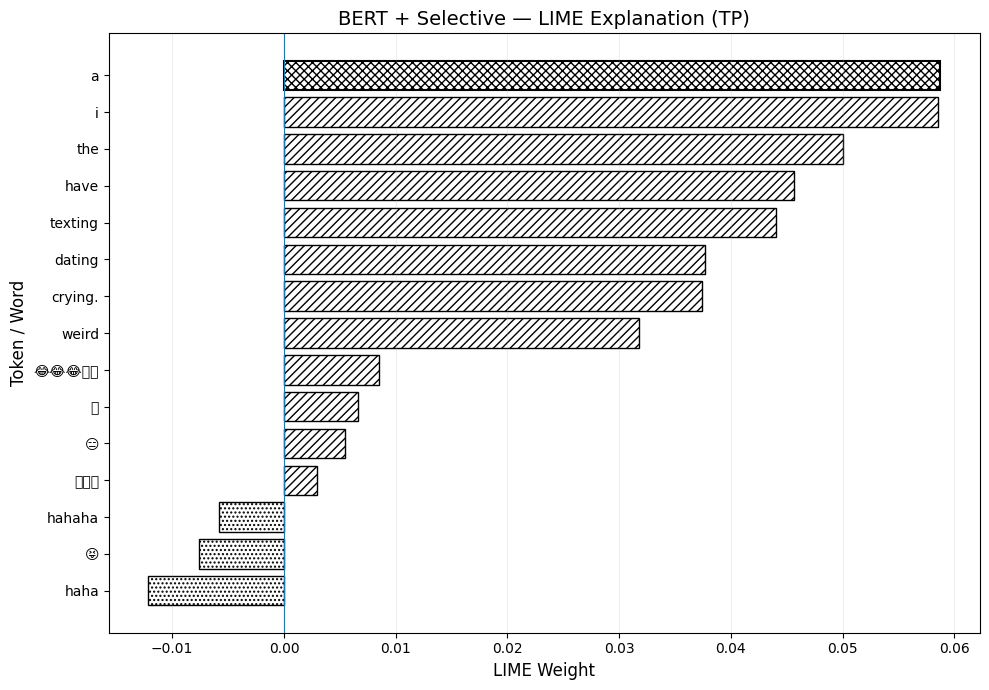

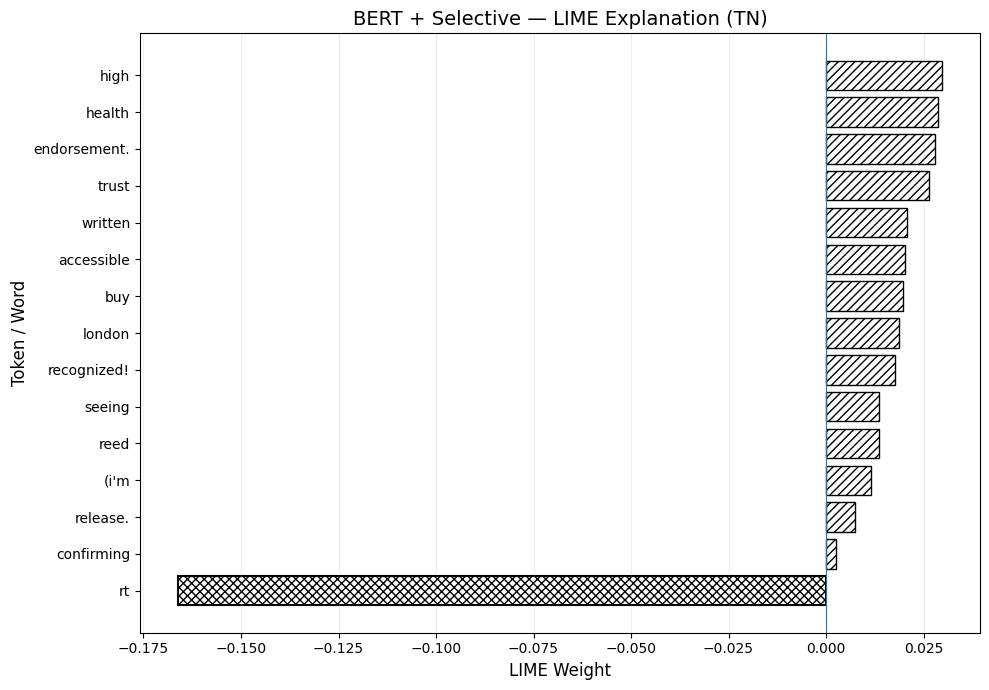

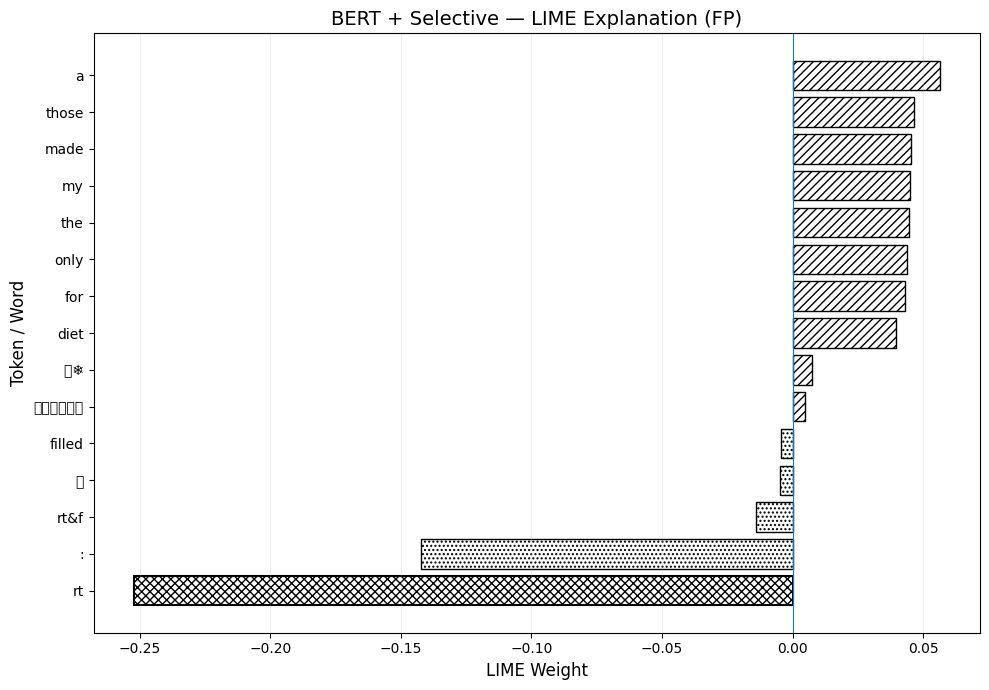

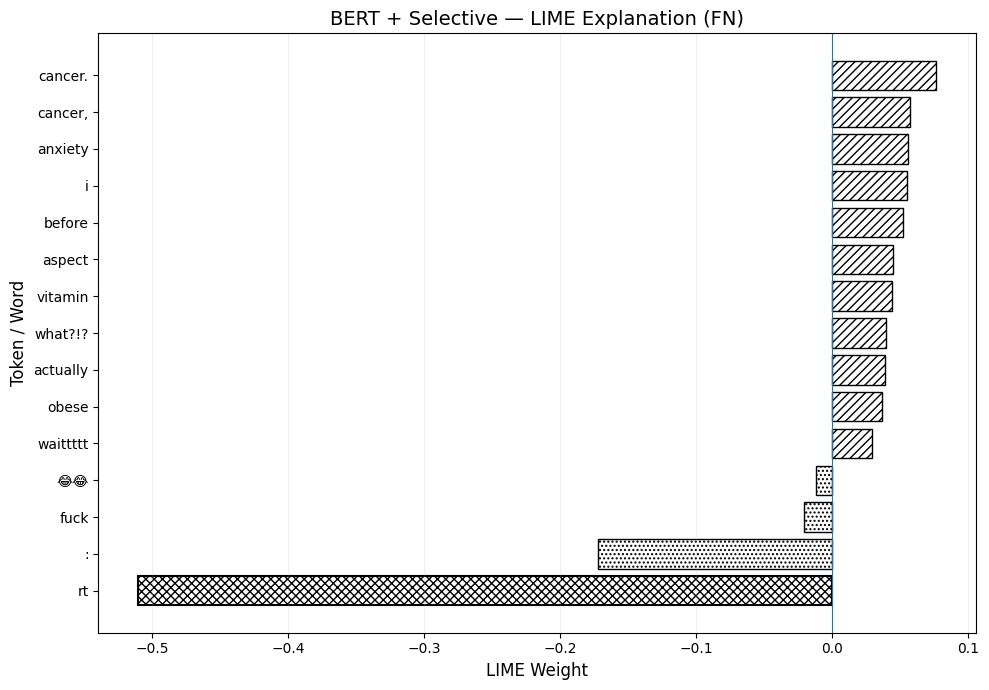


LIME ANALYSIS COMPLETE
✓ TP, TN, FP, FN cases explained
✓ Same trained BERT model used
✓ Metadata held fixed per user
✓ 1000 LIME perturbations per case
✓ Top 15 features extracted
✓ LIME results saved
✓ HTML explanations saved
✓ Paper-ready textured LIME plots saved and displayed

LIME output directory: /kaggle/working/bert_selective/explainability/lime


In [23]:
# ============================================================
# EXPLAINABILITY — LIME
# BERT + SELECTIVE
# LOCAL TOKEN-LEVEL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML


print("=" * 70)
print("LIME ANALYSIS")
print("BERT + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED LIME SETTINGS
# ============================================================

LIME_SEED = 42
LIME_NUM_FEATURES = 15
LIME_NUM_SAMPLES = 1000
LIME_BATCH_SIZE = 8


np.random.seed(
    LIME_SEED
)

torch.manual_seed(
    LIME_SEED
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

LIME_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "lime"
)

os.makedirs(
    LIME_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print()
print("✓ BERT Selective model ready")


# ============================================================
# TEST PREDICTIONS
# ============================================================

labels_np = []
preds_np = []
probs_np = []


with torch.no_grad():

    for batch in test_loader:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).long()

        labels_np.extend(
            labels.cpu()
            .numpy()
            .tolist()
        )

        preds_np.extend(
            predictions.cpu()
            .numpy()
            .tolist()
        )

        probs_np.extend(
            probabilities.cpu()
            .numpy()
            .tolist()
        )


labels_np = np.asarray(
    labels_np
)

preds_np = np.asarray(
    preds_np
)

probs_np = np.asarray(
    probs_np
)


print()
print(
    "Test users:",
    len(labels_np)
)


# ============================================================
# DETERMINISTIC TP / TN / FP / FN
# ============================================================

tp_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 1)
)[0]


tn_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 0)
)[0]


fp_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 1)
)[0]


fn_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 0)
)[0]


assert len(tp_candidates) > 0
assert len(tn_candidates) > 0
assert len(fp_candidates) > 0
assert len(fn_candidates) > 0


selected_cases = {

    "TP":
        int(
            tp_candidates[0]
        ),

    "TN":
        int(
            tn_candidates[0]
        ),

    "FP":
        int(
            fp_candidates[0]
        ),

    "FN":
        int(
            fn_candidates[0]
        )
}


print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)


for case_name, test_index in selected_cases.items():

    print(
        f"{case_name}: "
        f"Test Index = {test_index} | "
        f"True = {labels_np[test_index]} | "
        f"Pred = {preds_np[test_index]} | "
        f"Positive Probability = "
        f"{probs_np[test_index]:.4f}"
    )


# ============================================================
# LIME TEXT ACCESS
# ============================================================
# The same cleaned model_text that was used for BERT
# tokenization is used for LIME explanations.
# ============================================================

def get_test_text(
    test_index
):

    return str(
        test_bert_selective_df.iloc[
            int(test_index)
        ]["model_text"]
    )


# ============================================================
# LIME PREDICTOR
# ============================================================
# Text is perturbed by LIME.
# Metadata remains fixed for the explained user.
# ============================================================

def make_lime_predictor(
    test_index
):

    sample = test_dataset[
        int(test_index)
    ]


    fixed_metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .float()
        .to(device)
    )


    def lime_predict(
        texts
    ):

        all_probabilities = []


        for start in range(
            0,
            len(texts),
            LIME_BATCH_SIZE
        ):

            text_batch = texts[
                start:
                start + LIME_BATCH_SIZE
            ]


            encoded = tokenizer(
                text_batch,
                max_length=MAX_LENGTH,
                truncation=True,
                padding="max_length",
                return_attention_mask=True
            )


            input_ids = torch.tensor(
                encoded["input_ids"],
                dtype=torch.long
            ).to(device)


            attention_mask = torch.tensor(
                encoded["attention_mask"],
                dtype=torch.long
            ).to(device)


            metadata_batch = (
                fixed_metadata
                .expand(
                    len(text_batch),
                    -1
                )
            )


            with torch.no_grad():

                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    metadata=metadata_batch
                )


                logits = outputs["logits"]

                probabilities = torch.softmax(
                    logits.float(),
                    dim=1
                )


            all_probabilities.append(
                probabilities
                .cpu()
                .numpy()
            )


            del input_ids
            del attention_mask
            del metadata_batch
            del outputs
            del logits
            del probabilities


            if torch.cuda.is_available():
                torch.cuda.empty_cache()


        return np.vstack(
            all_probabilities
        )


    return lime_predict


# ============================================================
# LIME EXPLAINER
# ============================================================

explainer = LimeTextExplainer(
    class_names=[
        "Negative",
        "Positive"
    ],
    split_expression=r"\s+",
    random_state=LIME_SEED
)


print()
print("✓ LIME explainer ready")


# ============================================================
# RUN LIME FOR FOUR CASES
# ============================================================

all_explanations = {}


print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)


for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )


    text = get_test_text(
        test_index
    )


    predictor = make_lime_predictor(
        test_index
    )


    explanation = explainer.explain_instance(
        text,
        predictor,
        labels=(1,),
        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )


    all_explanations[
        case_name
    ] = explanation


    print(
        f"✓ {case_name} explanation complete"
    )


# ============================================================
# SAVE LIME RESULTS
# ============================================================

all_lime_rows = []


for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )


    for rank, (
        word,
        weight
    ) in enumerate(
        explanation_list,
        start=1
    ):

        all_lime_rows.append({

            "case":
                case_name,

            "test_index":
                selected_cases[
                    case_name
                ],

            "true_label":
                int(
                    labels_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "rank":
                rank,

            "word":
                word,

            "lime_weight":
                float(weight)

        })


lime_results_df = pd.DataFrame(
    all_lime_rows
)


lime_csv_path = os.path.join(
    LIME_DIR,
    "bert_selective_lime_results.csv"
)


lime_results_df.to_csv(
    lime_csv_path,
    index=False
)


# ============================================================
# DISPLAY + SAVE HTML
# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)


for case_name, explanation in all_explanations.items():

    print()
    print(
        "=" * 60
    )


    print(
        f"{case_name} — "
        f"LIME LOCAL EXPLANATION"
    )


    print(
        "=" * 60
    )


    display(
        HTML(
            explanation.as_html(
                labels=[1]
            )
        )
    )


    html_path = os.path.join(
        LIME_DIR,
        f"bert_selective_lime_{case_name}.html"
    )


    with open(
        html_path,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(
            explanation.as_html(
                labels=[1]
            )
        )


# ============================================================
# PAPER-FRIENDLY LIME BAR PLOTS
# ============================================================

for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )


    plot_df = pd.DataFrame(
        explanation_list,
        columns=[
            "word",
            "weight"
        ]
    )


    plot_df = plot_df.sort_values(
        "weight"
    )


    plt.figure(
        figsize=(10, 7)
    )


    # --------------------------------------------------------
    # TEXTURED / HATCHED BARS
    # Positive and negative contributions are represented
    # using textures instead of different colors.
    # --------------------------------------------------------

    bars = plt.barh(
        plot_df["word"],
        plot_df["weight"],
        facecolor="white",
        edgecolor="black",
        linewidth=1.0
    )


    # Apply different textures
    for bar, weight in zip(
        bars,
        plot_df["weight"]
    ):

        if weight > 0:
            bar.set_hatch(
                "////"
            )

        else:
            bar.set_hatch(
                "...."
            )


    # Highlight strongest contribution
    if len(bars) > 0:

        strongest_index = int(
            np.argmax(
                np.abs(
                    plot_df["weight"]
                    .to_numpy()
                )
            )
        )


        bars[strongest_index].set_hatch(
            "xxxx"
        )

        bars[strongest_index].set_linewidth(
            1.5
        )


    plt.axvline(
        0,
        linewidth=0.8
    )


    plt.xlabel(
        "LIME Weight",
        fontsize=12
    )


    plt.ylabel(
        "Token / Word",
        fontsize=12
    )


    plt.title(
        f"BERT + Selective — "
        f"LIME Explanation ({case_name})",
        fontsize=14
    )


    plt.grid(
        axis="x",
        alpha=0.20
    )


    plt.tight_layout()


    plot_path = os.path.join(
        LIME_DIR,
        f"bert_selective_lime_{case_name}.png"
    )


    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()


# ============================================================
# SAVE CASE INFORMATION
# ============================================================

case_info_rows = []


for case_name, test_index in selected_cases.items():

    case_info_rows.append({

        "case":
            case_name,

        "test_index":
            int(test_index),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            ),

        "text_length_characters":
            len(
                get_test_text(
                    test_index
                )
            )

    })


case_info_df = pd.DataFrame(
    case_info_rows
)


case_info_df.to_csv(
    os.path.join(
        LIME_DIR,
        "bert_selective_lime_case_information.csv"
    ),
    index=False
)


# ============================================================
# SAVE CONFIGURATION
# ============================================================

lime_config = {

    "model":
        "BERT",

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class",

    "representative_cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "random_seed":
        LIME_SEED,

    "num_samples":
        LIME_NUM_SAMPLES,

    "num_features":
        LIME_NUM_FEATURES,

    "batch_size":
        LIME_BATCH_SIZE,

    "metadata":
        "Fixed for each explained user",

    "text_perturbation":
        "LIME word-level perturbations",

    "model_training":
        "No additional training"
}


with open(
    os.path.join(
        LIME_DIR,
        "bert_selective_lime_config.json"
    ),
    "w"
) as f:

    json.dump(
        lime_config,
        f,
        indent=2
    )


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)


print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Same trained BERT model used"
)

print(
    "✓ Metadata held fixed per user"
)

print(
    "✓ 1000 LIME perturbations per case"
)

print(
    "✓ Top 15 features extracted"
)

print(
    "✓ LIME results saved"
)

print(
    "✓ HTML explanations saved"
)

print(
    "✓ Paper-ready textured LIME plots saved and displayed"
)

print()

print(
    "LIME output directory:",
    LIME_DIR
)